# Pràctica IAA - Predicció d'esquizofrènia resistent al tractament

L’objectiu d’aquesta pràctica és desenvolupar i avaluar un model de classificació que, a partir de paràmetres de laboratori, marcadors genètics, característiques de neuroimatge i variables demogràfiques, sigui capaç de predir si un pacient presenta esquizofrènia resistent al tractament (TRS) o no resistent (NTRS). Al llarg del treball es realitza una anàlisi i preprocessat de les dades, la preparació de variables i l’entrenament i comparació de diversos models

## Importem les llibreries necessàries

In [1]:
import warnings
from datetime import date
from io import StringIO
import uuid
import sys
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, HTML

import xgboost as xgb


import verifyml.model_card_toolkit as mctlib
import verifyml.model_tests.utils as utils


from interpret.glassbox import ExplainableBoostingClassifier

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    roc_curve, auc, RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_score,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.svm import SVC



sns.set()
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)
warnings.filterwarnings("ignore")
plt.rcParams["axes.unicode_minus"] = False


***
## SECCIÓ 1: Preprocessament

### 1.1 Carreguem les dades

In [2]:

df_train = pd.read_csv("trs_train.csv")
X_train_full = df_train.drop(columns=["patient_id", "TRS"])
y_train_full = df_train["TRS"].copy()

df_eval = pd.read_csv("trs_eval.csv")
X_eval = df_eval.drop(columns=["patient_id"])


### 1.2 Anàlisi del dataset

In [3]:
X_train_full.head()

,Age,Sex,Ethnicity,Duration_untreated_psychosis,Family_history,Initial_response,Lymphocyte_count,Neutrophil_count,BMI,Triglycerides,Glucose,Alkaline_phosphatase,Prior_antipsychotics,CYP2D6_metabolic_phenotype,HLA_DRB1_04_02,HLA_B_15_02,HLA_A_31_01,Polygenic_risk_score,Del_22q11_2_status,IL_17A,CCL23,TWEAK,Ki_whole_striatum,Ki_associative_striatum,SUVRc_whole_striatum,SUVRc_associative_striatum
0,28.0,1,Caucasian,7.5,1,24.7,2.35,NaN,31.2,230.6,NaN,NaN,2,Extensive,0,0,1,0.330,0,2.76,5.66,4.47,0.01147,0.01082,1.225,1.133
1,23.0,1,Asian,3.6,1,41.0,2.02,3.34,26.2,58.9,NaN,NaN,2,Extensive,0,0,0,0.121,0,2.04,2.67,1.93,0.01386,0.01437,1.042,1.502
2,29.0,1,Caucasian,7.4,0,6.0,NaN,5.38,39.2,NaN,114.9,77.7,0,Intermediate,0,0,0,-0.098,0,1.55,2.31,2.92,0.01589,0.01632,1.728,1.842
3,36.0,0,Hispanic,5.5,0,43.4,1.60,6.84,31.5,152.5,65.5,92.1,0,Extensive,0,0,0,0.019,0,1.77,2.37,4.26,0.01178,0.01154,1.399,1.249
4,23.0,0,Caucasian,4.5,0,86.1,NaN,3.18,29.6,221.0,112.2,96.2,0,Intermediate,0,0,0,-0.049,0,2.11,3.55,3.84,0.01209,0.01171,0.800,1.533


In [4]:
buffer = StringIO()
X_train_full.info(buf=buffer)
print(buffer.getvalue())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           9000 non-null   float64
 1   Sex                           9000 non-null   int64  
 2   Ethnicity                     9000 non-null   object 
 3   Duration_untreated_psychosis  8872 non-null   float64
 4   Family_history                9000 non-null   int64  
 5   Initial_response              9000 non-null   float64
 6   Lymphocyte_count              7009 non-null   float64
 7   Neutrophil_count              7015 non-null   float64
 8   BMI                           9000 non-null   float64
 9   Triglycerides                 6547 non-null   float64
 10  Glucose                       6381 non-null   float64
 11  Alkaline_phosphatase          6062 non-null   float64
 12  Prior_antipsychotics          9000 non-null   int64  
 13  CYP

Taula resum

In [6]:

# Categòriques
cat_cols = ["Ethnicity", "CYP2D6_metabolic_phenotype"]

# Tot el que no és categóric
num_candidates = [c for c in X_train_full.columns if c not in cat_cols]

# Binàries
bin_cols = [c for c in num_candidates if set(X_train_full[c].dropna().unique()).issubset({0, 1})]

# Numèriques no binàries
num_cols = [c for c in num_candidates if c not in bin_cols]

print("Nombre de variables categòriques:", len(cat_cols))
print("Nombre de variables binàries:", len(bin_cols))
print("Nombre de variables numèriques (no binàries):", len(num_cols))

print("\nVariables categòriques:", cat_cols)
print("\nVariables binàries:", bin_cols)

# Taula estadística
X_train_full.describe(include="all").T


Nombre de variables categòriques: 2
Nombre de variables binàries: 6
Nombre de variables numèriques (no binàries): 18

Variables categòriques: ['Ethnicity', 'CYP2D6_metabolic_phenotype']

Variables binàries: ['Sex', 'Family_history', 'HLA_DRB1_04_02', 'HLA_B_15_02', 'HLA_A_31_01', 'Del_22q11_2_status']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,9000.0,NaN,NaN,NaN,26.039444,10.011767,13.0,19.0,25.0,31.0,64.0
Sex,9000.0,NaN,NaN,NaN,0.576,0.494218,0.0,0.0,1.0,1.0,1.0
Ethnicity,9000,4,Caucasian,5408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration_untreated_psychosis,8872.0,NaN,NaN,NaN,19.220548,19.545745,0.3,6.4,12.5,24.3,125.0
Family_history,9000.0,NaN,NaN,NaN,0.118778,0.323545,0.0,0.0,0.0,0.0,1.0
Initial_response,9000.0,NaN,NaN,NaN,41.840367,30.16023,0.0,10.1,38.2,72.3,100.0
Lymphocyte_count,7009.0,NaN,NaN,NaN,1.795761,0.601099,0.5,1.38,1.8,2.2,4.02
Neutrophil_count,7015.0,NaN,NaN,NaN,5.014574,1.471581,1.5,4.005,5.02,6.01,9.96
BMI,9000.0,NaN,NaN,NaN,28.107556,5.4331,15.0,24.4,28.0,31.7,49.6
Triglycerides,6547.0,NaN,NaN,NaN,152.0128,61.099018,40.0,108.05,151.1,194.6,394.6


Comprovar desbalanceig de classes

Comptatge de classes (train):
TRS
0    6162
1    2838
Name: count, dtype: int64

Proporció de classes (train):
TRS
0    0.684667
1    0.315333
Name: proportion, dtype: float64


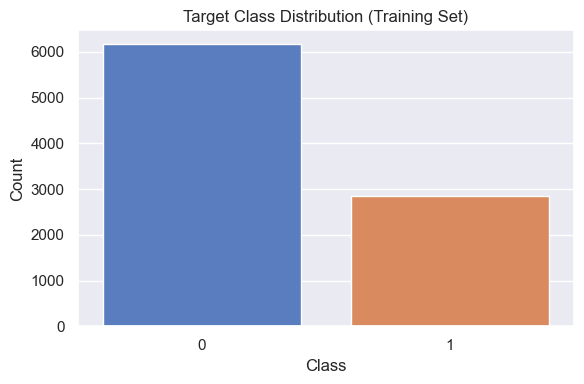

In [7]:

counts = y_train_full.value_counts().sort_values(ascending=False)

print("Comptatge de classes (train):")
print(counts)

print("\nProporció de classes (train):")
print((counts / counts.sum()).rename("proportion"))

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette="muted")
plt.title("Target Class Distribution (Training Set)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Comprovar presència de missings

In [8]:
missing_values = X_train_full.isna().sum().sort_values(ascending=False)
missing_values[missing_values > 0]

Alkaline_phosphatase            2938
Glucose                         2619
Triglycerides                   2453
Lymphocyte_count                1991
Neutrophil_count                1985
Duration_untreated_psychosis     128
IL_17A                             1
Polygenic_risk_score               1
dtype: int64

Comprovar outliers

Variables amb almenys 1 outlier: 16


,outliers_low,outliers_high,outliers_total,outliers_pct
Duration_untreated_psychosis,0,651,651,7.233333
Age,0,360,360,4.000000
Polygenic_risk_score,11,114,125,1.388889
Ki_associative_striatum,0,83,83,0.922222
Ki_whole_striatum,0,71,71,0.788889
CCL23,31,28,59,0.655556
TWEAK,30,28,58,0.644444
IL_17A,29,28,57,0.633333
BMI,0,39,39,0.433333
SUVRc_whole_striatum,0,35,35,0.388889


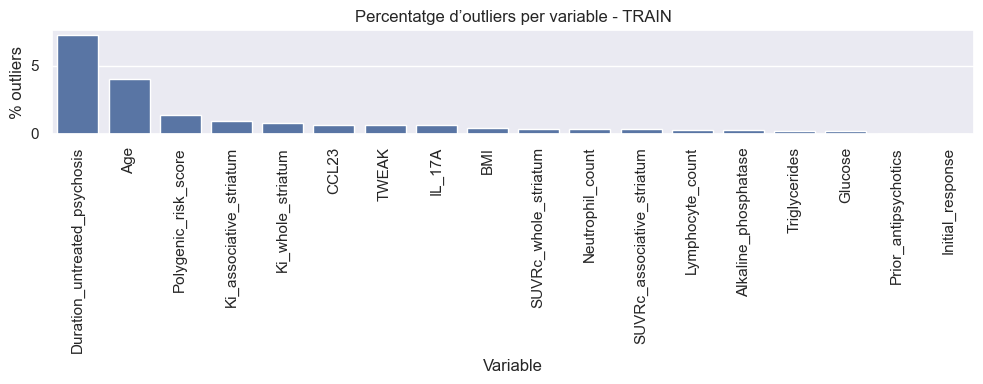

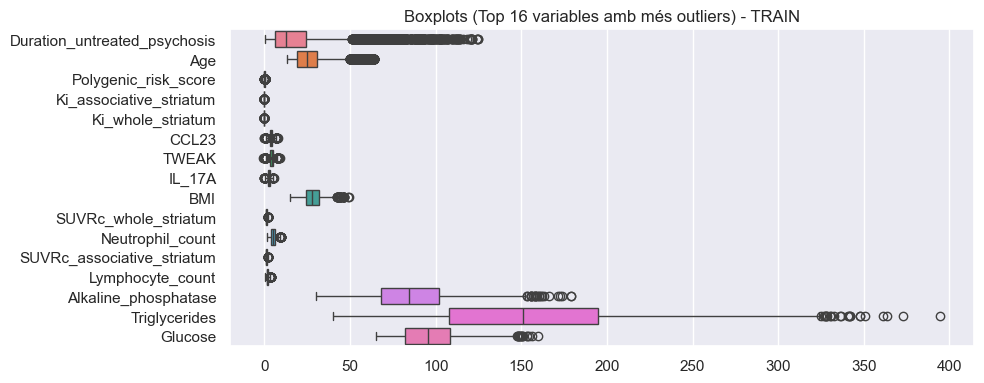

In [9]:

X_num = X_train_full[num_cols]

# Quartils i IQR per columna
Q1 = X_num.quantile(0.25)
Q3 = X_num.quantile(0.75)
IQR = Q3 - Q1

k = 1.5
lower_bound = Q1 - k * IQR
upper_bound = Q3 + k * IQR

# Comptatge d’outliers per variable (per sobre / per sota)
outliers_low = (X_num < lower_bound).sum()
outliers_high = (X_num > upper_bound).sum()
outliers_total = outliers_low + outliers_high

outliers_summary = pd.DataFrame({
    "outliers_low": outliers_low,
    "outliers_high": outliers_high,
    "outliers_total": outliers_total,
    "outliers_pct": 100 * outliers_total / len(X_num)
}).sort_values("outliers_total", ascending=False)

print("Variables amb almenys 1 outlier:", (outliers_total > 0).sum())
display(outliers_summary[outliers_summary["outliers_total"] > 0])

# Gràfic 1: percentatge d’outliers per variable
plt.figure(figsize=(10, 4))
sns.barplot(x=outliers_summary.index, y=outliers_summary["outliers_pct"])
plt.xticks(rotation=90)
plt.ylabel("% outliers")
plt.xlabel("Variable")
plt.title("Percentatge d’outliers per variable - TRAIN")
plt.tight_layout()
plt.show()

# Gràfic 2: boxplots
top_k = 16
top_vars = outliers_summary.head(top_k).index.tolist()

plt.figure(figsize=(10, 4))
sns.boxplot(data=X_num[top_vars], orient="h")
plt.title(f"Boxplots (Top {top_k} variables amb més outliers) - TRAIN")
plt.tight_layout()
plt.show()


### 1.3 Divisió del dataset i transformacions

Dividir el dataset de forma stratificada

In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)


print(f"Dataset complet: {X_train_full.shape[0]} mostres × {X_train_full.shape[1]} variables")

print(f"\nConjunt train: {X_train.shape[0]} mostres")
print(f"  Classe 0: {(y_train==0).sum()} ({(y_train==0).sum()/len(y_train)*100:.1f}%)")
print(f"  Classe 1: {(y_train==1).sum()} ({(y_train==1).sum()/len(y_train)*100:.1f}%)")

print(f"\nConjunt test: {X_test.shape[0]} mostres")
print(f"  Classe 0: {(y_test==0).sum()} ({(y_test==0).sum()/len(y_test)*100:.1f}%)")
print(f"  Classe 1: {(y_test==1).sum()} ({(y_test==1).sum()/len(y_test)*100:.1f}%)")


Dataset complet: 9000 mostres × 26 variables

Conjunt train: 7200 mostres
  Classe 0: 4930 (68.5%)
  Classe 1: 2270 (31.5%)

Conjunt test: 1800 mostres
  Classe 0: 1232 (68.4%)
  Classe 1: 568 (31.6%)


Un cop dividit el dataset, imputem els missings

In [11]:
imp_num = SimpleImputer(strategy="median")

X_train_imp = X_train.copy()
X_test_imp  = X_test.copy()

X_train_imp[num_cols] = imp_num.fit_transform(X_train[num_cols])

X_test_imp[num_cols]  = imp_num.transform(X_test[num_cols])


***
## SECCIÓ 2: Preparació de variables

### 2.1 Normalització de variables

In [12]:
scaler = StandardScaler()

X_train_scaled = X_train_imp.copy()
X_test_scaled  = X_test_imp.copy()

scaler.fit(X_train_imp[num_cols])

X_train_scaled[num_cols] = scaler.transform(X_train_imp[num_cols])
X_test_scaled[num_cols]  = scaler.transform(X_test_imp[num_cols])

X_train_scaled.shape, X_test_scaled.shape

((7200, 26), (1800, 26))

### 2.2 Anàlisi de variables

Variables numèriques

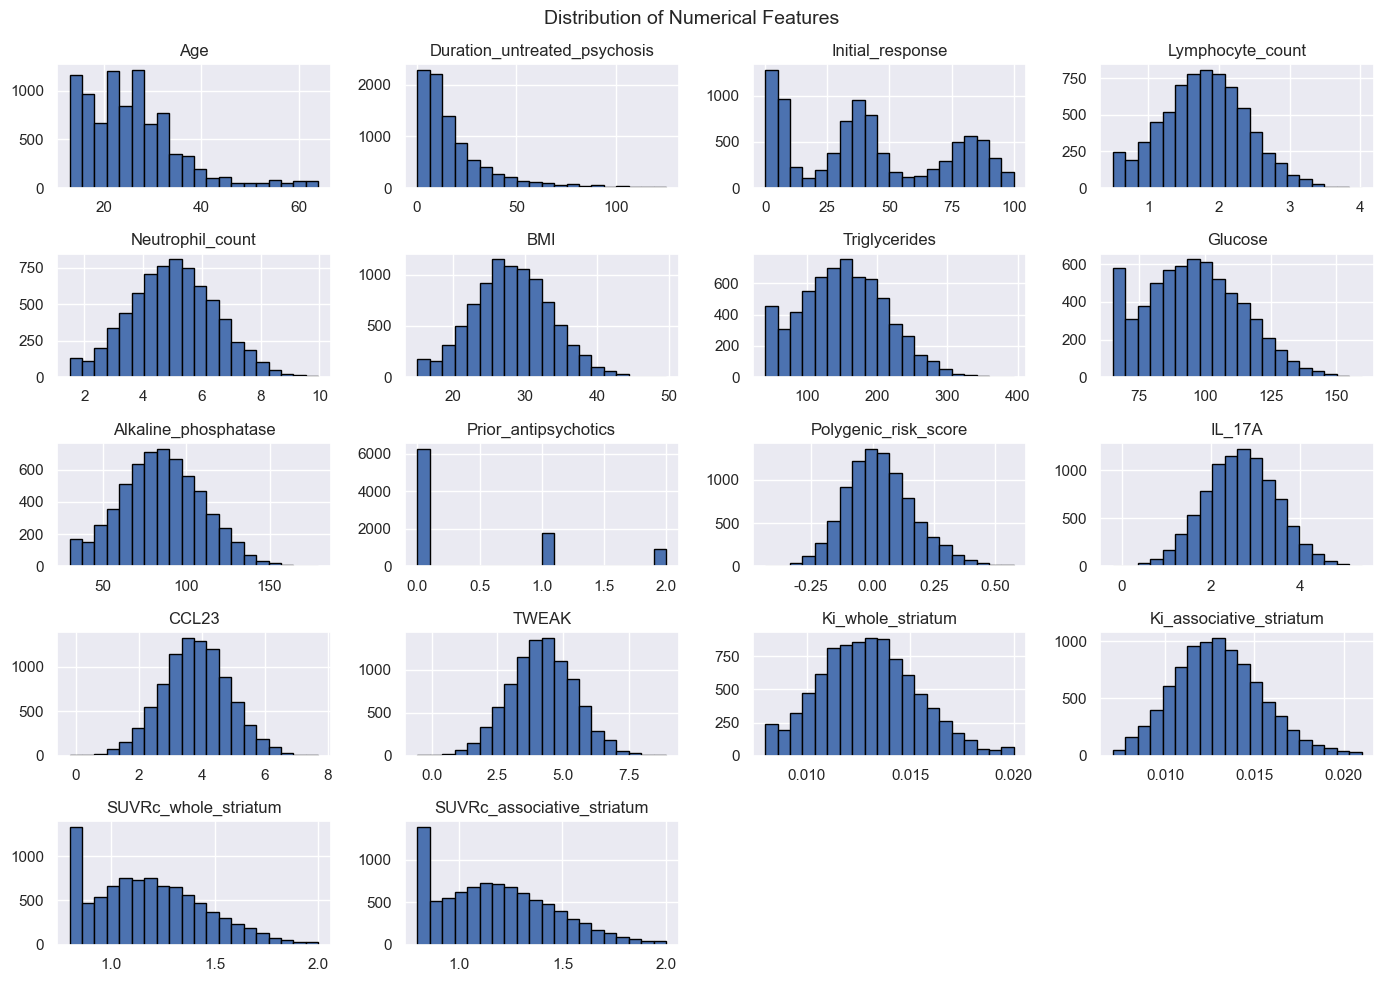

In [13]:
# Histogrames per a les variables numèriques
X_train_full[num_cols].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=14)
plt.tight_layout()
plt.show()


Variables categòriques i binàries en relació a la variable objectiu

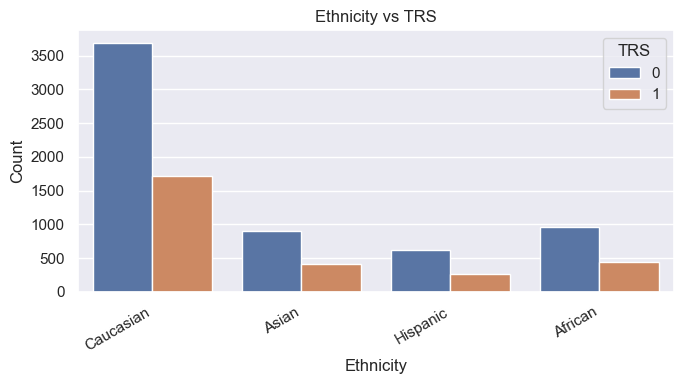

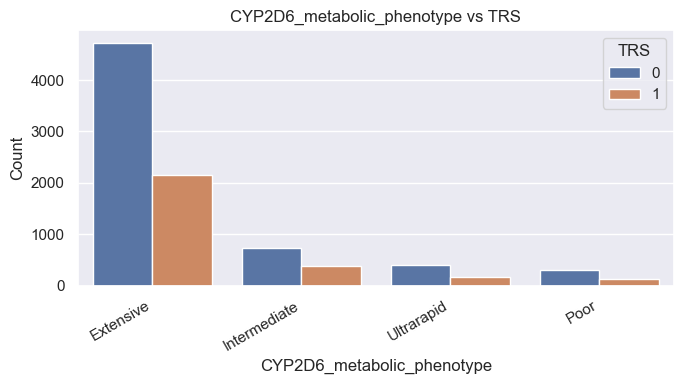

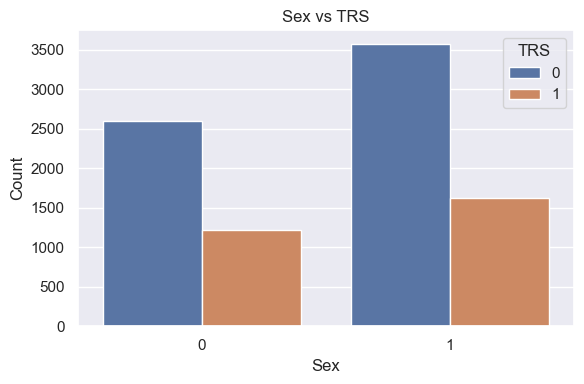

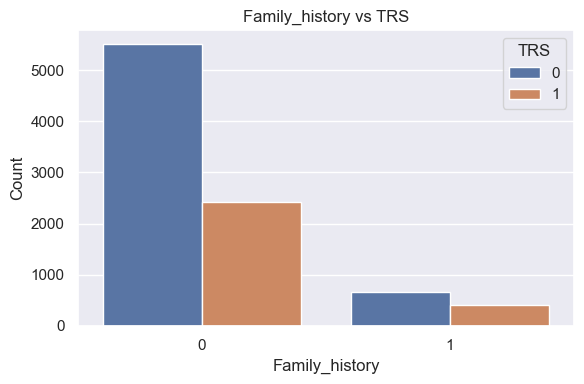

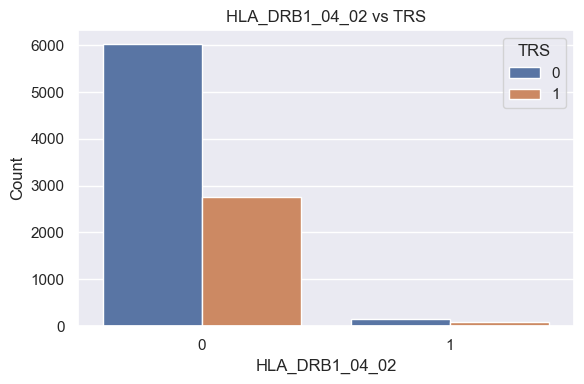

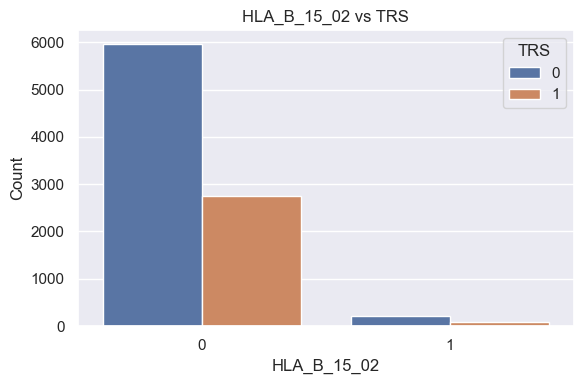

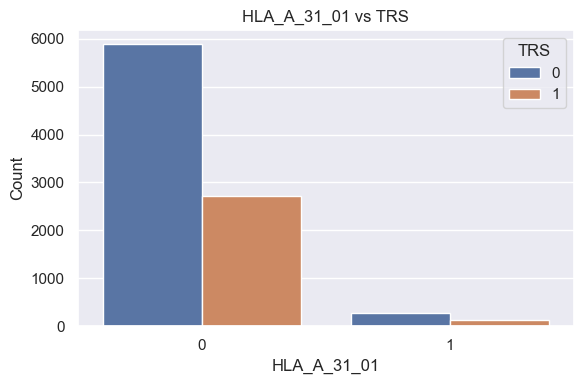

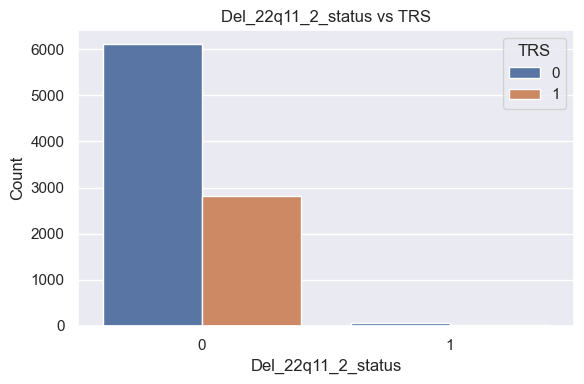

In [14]:

# Categòriques vs TRS
for col in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df_train, x=col, hue="TRS")
    plt.title(f"{col} vs TRS")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# 2) Binàries vs TRS
for col in bin_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_train, x=col, hue="TRS")
    plt.title(f"{col} vs TRS")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


### 2.3 Estudi de correlació

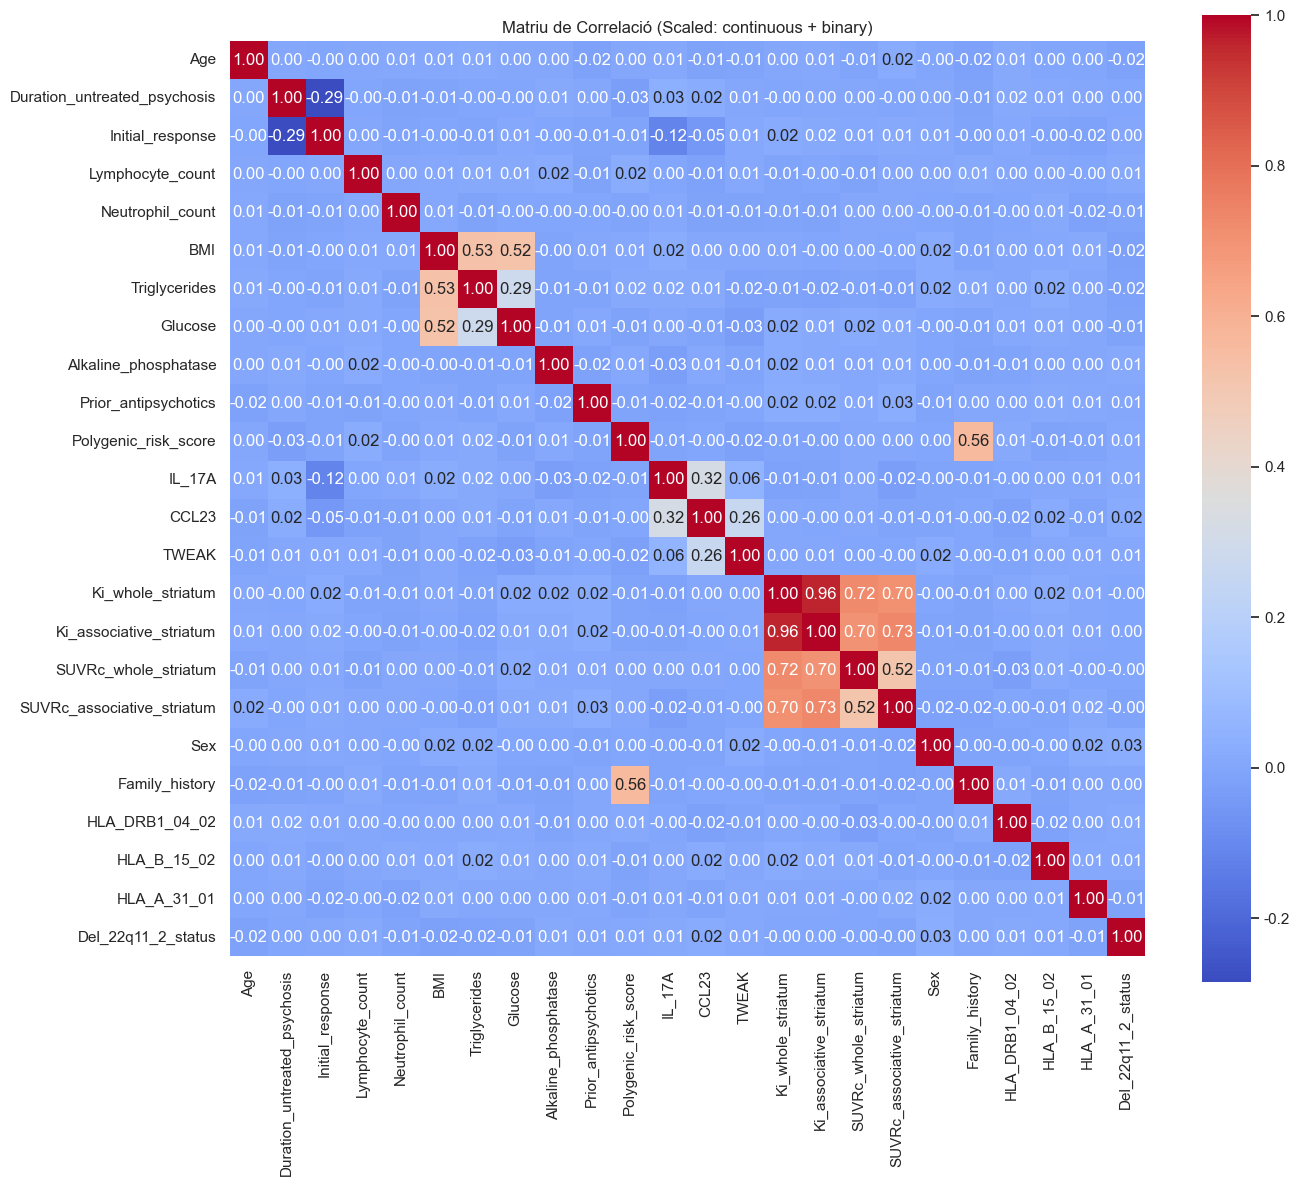

Pairs with |corr| >= 0.7 (continuous + binary): 5


,feature_1,feature_2,corr
231,Ki_whole_striatum,Ki_associative_striatum,0.963712
241,Ki_associative_striatum,SUVRc_associative_striatum,0.731404
232,Ki_whole_striatum,SUVRc_whole_striatum,0.724525
233,Ki_whole_striatum,SUVRc_associative_striatum,0.704900
240,Ki_associative_striatum,SUVRc_whole_striatum,0.700999


In [15]:
CORR_THRESHOLD = 0.7

numeric_cols_all = num_cols + bin_cols

corr_all = X_train_scaled[numeric_cols_all].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_all, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Matriu de Correlació (Scaled: continuous + binary)")
plt.tight_layout()
plt.show()

upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
         .reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "corr"})
)

high_corr_pairs["abs_corr"] = high_corr_pairs["corr"].abs()
high_corr_pairs = high_corr_pairs[high_corr_pairs["abs_corr"] >= CORR_THRESHOLD]
high_corr_pairs = high_corr_pairs.sort_values("abs_corr", ascending=False).drop(columns=["abs_corr"])

print(f"Pairs with |corr| >= {CORR_THRESHOLD} (continuous + binary): {len(high_corr_pairs)}")
display(high_corr_pairs)


Eliminem variables redundants

In [16]:

drop_cols = ["Ki_associative_striatum"]

num_cols_final = [c for c in num_cols if c not in drop_cols]


### Estudi de dimensionalitat

In [17]:
pca = PCA()
X_train_pca_full = pca.fit_transform(X_train_scaled[num_cols_final])

pca.explained_variance_ratio_

array([0.13551399, 0.11215323, 0.08771595, 0.07378192, 0.06153353,
       0.05987372, 0.05907215, 0.05850935, 0.05768478, 0.05735661,
       0.05440801, 0.04210402, 0.04104315, 0.03587801, 0.02841851,
       0.02237545, 0.01257761])

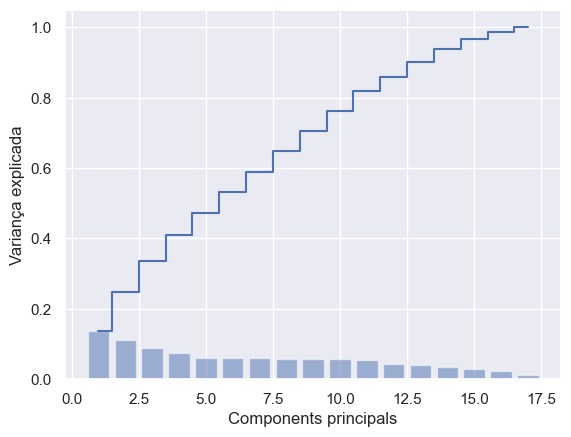

90% explained variance -> 13 components
95% explained variance -> 15 components
99% explained variance -> 17 components
100% explained variance -> 17 components


In [18]:
n_comp = len(pca.explained_variance_ratio_)

plt.bar(range(1, n_comp + 1), pca.explained_variance_ratio_, alpha=0.5, align='center')
plt.step(range(1, n_comp + 1), np.cumsum(pca.explained_variance_ratio_), where='mid')
plt.ylabel('Variança explicada')
plt.xlabel('Components principals')
plt.show()

cum_var = np.cumsum(pca.explained_variance_ratio_)
for thr in [0.90, 0.95, 0.99, 1]:
    k = np.argmax(cum_var >= thr) + 1
    print(f"{thr:.0%} explained variance -> {k} components")

***
## SECCIÓ 3: Modelatge

### 3.1 Preprocessament i validació creuada

En aquest apartat es realitza una nova partició del dataset. Per tal d'evitar data leakage s'han de repetir les transformacions realitzades en la secció 1 i 2 des de 0.

In [19]:
drop_cols_finals = ["Ki_associative_striatum"]

# Columnes finals
num_cols_cv = [c for c in num_cols if c not in drop_cols_finals]
bin_cols_cv = [c for c in bin_cols if c not in drop_cols_finals]
cat_cols_cv = [c for c in cat_cols if c not in drop_cols_finals]


preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols_cv),

        ("bin", "passthrough", bin_cols_cv),

        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_cv),
    ],
    remainder="drop"
)

# Cross-validation estratificada (sobre X_train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Mètriques per CV
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}


### 3.2 Model Suport Vector Machines (SVM)

#### 3.2.1 Anàlisi d'hiperparàmetres

In [20]:
pipe_svm = Pipeline([
    ("prep", preprocess),
    ("svm", SVC())
])

param_kernel = [
    {"svm__kernel": ["linear"],
     "svm__C": [0.01, 0.1, 1, 10, 100],
     "svm__class_weight": [None, "balanced"]},

    {"svm__kernel": ["rbf"],
     "svm__C": [0.01, 0.1, 1, 10, 100],
     "svm__gamma": ["scale", 0.001, 0.01, 0.1],
     "svm__class_weight": [None, "balanced"]},

    {"svm__kernel": ["poly"],
     "svm__C": [0.01, 0.1, 1, 10, 100],
     "svm__degree": [2, 4],
     "svm__class_weight": [None, "balanced"]},
]


gs_kernel = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_kernel,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_kernel.fit(X_train, y_train)

print(f"Best CV F1-macro: {gs_kernel.best_score_:.4f}")

res = pd.DataFrame(gs_kernel.cv_results_)

cols = [
    "param_svm__kernel", "param_svm__C", "param_svm__degree", "param_svm__gamma", "param_svm__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_kernel = res[cols].sort_values("rank_test_f1_macro")

table_kernel = table_kernel.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_kernel

gs_kernel.best_estimator_.named_steps["svm"]

Best CV F1-macro: 0.5901


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.001
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [21]:
table_kernel

,param_svm__kernel,param_svm__C,param_svm__degree,param_svm__gamma,param_svm__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
23,rbf,0.10,NaN,0.001,balanced,0.656111,0.594717,0.588801,0.590094,0.009625,1,0.657326,0.596352,0.591055,0.592408
14,rbf,0.01,NaN,scale,balanced,0.614861,0.587902,0.597898,0.584533,0.009374,2,0.622847,0.597017,0.609048,0.594489
33,rbf,1.00,NaN,0.1,balanced,0.605417,0.572523,0.580662,0.571391,0.014136,3,0.849028,0.824801,0.860045,0.835390
30,rbf,1.00,NaN,scale,balanced,0.591944,0.578235,0.589958,0.570474,0.009969,4,0.713021,0.697600,0.726800,0.696800
40,rbf,10.00,NaN,0.01,balanced,0.585556,0.577290,0.589215,0.566750,0.008365,5,0.649757,0.639716,0.661232,0.633048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35,rbf,10.00,NaN,0.001,None,0.684722,0.342361,0.500000,0.406430,0.000000,53,0.684722,0.342361,0.500000,0.406430
12,rbf,0.01,NaN,0.01,None,0.684722,0.342361,0.500000,0.406430,0.000000,53,0.684722,0.342361,0.500000,0.406430
11,rbf,0.01,NaN,0.001,None,0.684722,0.342361,0.500000,0.406430,0.000000,53,0.684722,0.342361,0.500000,0.406430
8,linear,100.00,NaN,NaN,None,0.684722,0.342361,0.500000,0.406430,0.000000,53,0.684722,0.342361,0.500000,0.406430


#### 3.2.2 Validació numèrica i gràfica

Validació numèrica: Mètriques

In [22]:
best_svm = gs_kernel.best_estimator_


y_pred_svm_init = best_svm.predict(X_test)


metrics_svm = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_svm_init),
    "precision_macro": precision_score(y_test, y_pred_svm_init, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_svm_init, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_svm_init, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_svm_init, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_svm_init, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_svm_init, pos_label=1, zero_division=0),
}])

metrics_svm


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.612778,0.571464,0.577642,0.572097,0.404727,0.482394,0.440161


Validació gràfica: Matriu de confusió

<Figure size 640x480 with 0 Axes>

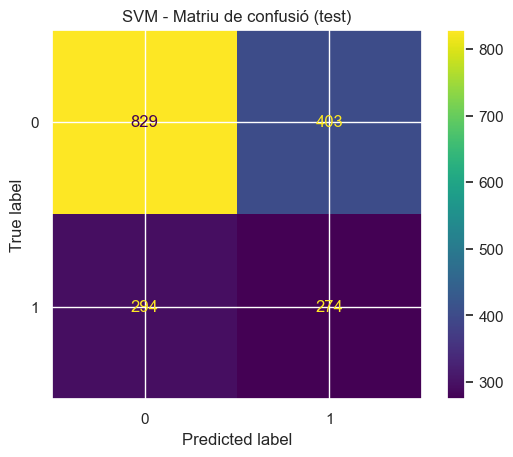

In [23]:
cm = confusion_matrix(y_test, y_pred_svm_init, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

plt.figure()
disp.plot(values_format="d")
plt.title("SVM - Matriu de confusió (test)")
plt.show()


Validació gràfica: Corva precision - recall

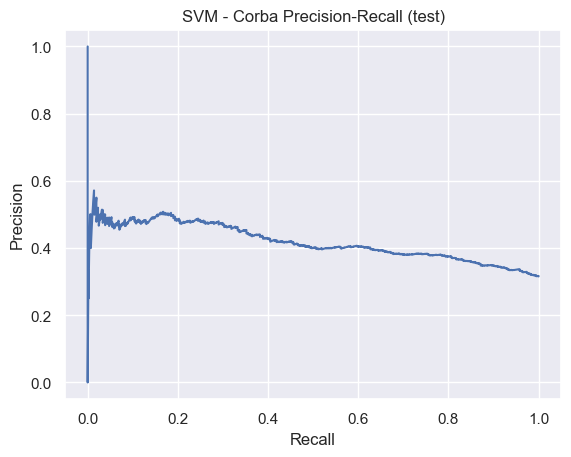

In [24]:
scores = best_svm.decision_function(X_test)

p, r, _ = precision_recall_curve(y_test, scores, pos_label=1)

plt.figure()
plt.plot(r, p)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("SVM - Corba Precision-Recall (test)")
plt.show()


#### 3.2.3 Intents de millora

Iteració 1: Nou anàlisi d'hiperparàmetres

In [25]:
pipe_svm_fine = Pipeline([
    ("prep", preprocess),
    ("svm", SVC())
])

param_kernel_fine = [
    {"svm__kernel": ["rbf"],
     "svm__C": [0.03, 0.05, 0.1, 0.2, 0.3],
     "svm__gamma": [0.0003, 0.0005, 0.001, 0.002, 0.003, 0.01],
     "svm__class_weight": ["balanced"]},
]


gs_kernel_fine = GridSearchCV(
    estimator=pipe_svm_fine,
    param_grid=param_kernel_fine,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_kernel_fine.fit(X_train, y_train);

print(f"Best CV F1-macro: {gs_kernel_fine.best_score_:.4f}")

res_fine = pd.DataFrame(gs_kernel_fine.cv_results_)

cols = [
    "param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_kernel_fine = res_fine[cols].sort_values("rank_test_f1_macro")

table_kernel_fine = table_kernel_fine.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_kernel_fine

gs_kernel_fine.best_estimator_.named_steps["svm"]

Best CV F1-macro: 0.5924


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.2
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.0005
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [26]:
table_kernel_fine

,param_svm__kernel,param_svm__C,param_svm__gamma,param_svm__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
19,rbf,0.20,0.0005,balanced,0.657083,0.596500,0.591056,0.592394,0.009135,1,0.657708,0.597262,0.592404,0.593809
14,rbf,0.10,0.0010,balanced,0.656111,0.594717,0.588801,0.590094,0.009625,2,0.657326,0.596352,0.591055,0.592408
9,rbf,0.05,0.0020,balanced,0.657500,0.594762,0.588032,0.589843,0.008006,3,0.657847,0.595335,0.589148,0.590950
10,rbf,0.05,0.0030,balanced,0.625694,0.589489,0.598084,0.589591,0.006790,4,0.627604,0.591859,0.601261,0.592391
25,rbf,0.30,0.0005,balanced,0.619028,0.587917,0.597851,0.586800,0.008156,5,0.623194,0.592111,0.602884,0.591585
15,rbf,0.10,0.0020,balanced,0.606528,0.592337,0.605955,0.585372,0.011047,6,0.607708,0.594305,0.608540,0.587204
24,rbf,0.30,0.0003,balanced,0.659722,0.593048,0.582762,0.585081,0.008458,7,0.661458,0.595595,0.585961,0.588100
20,rbf,0.20,0.0010,balanced,0.605417,0.592756,0.606570,0.585058,0.011814,8,0.606424,0.594404,0.608761,0.586605
5,rbf,0.03,0.0100,balanced,0.592083,0.590733,0.604796,0.576822,0.013468,9,0.597674,0.595300,0.610275,0.582321
16,rbf,0.10,0.0030,balanced,0.589306,0.593140,0.607640,0.576257,0.013155,10,0.590833,0.594407,0.609231,0.577814


In [27]:
best_svm_fine = gs_kernel_fine.best_estimator_
y_pred_svm_it1 = best_svm_fine.predict(X_test)

metrics_svm_fine = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_svm_it1),
    "precision_macro": precision_score(y_test, y_pred_svm_it1, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_svm_it1, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_svm_it1, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_svm_it1, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_svm_it1, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_svm_it1, pos_label=1, zero_division=0),
}])

metrics_svm_fine


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.613333,0.572232,0.578522,0.572873,0.405605,0.484155,0.441413


Iteració 2: Tractament d'outliers

En aquest nou prprocessament convertim els valors outliers de les variables més problemàtiques al seu llindar.

In [28]:
drop_cols_finals = ["Ki_associative_striatum"]

num_cols_cv = [c for c in num_cols if c not in drop_cols_finals]
bin_cols_cv = [c for c in bin_cols if c not in drop_cols_finals]
cat_cols_cv = [c for c in cat_cols if c not in drop_cols_finals]

cap_cols = ["Duration_untreated_psychosis", "Age"]
cap_idx = [num_cols_cv.index(c) for c in cap_cols]

class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, cols_idx, k=1.5):
        self.cols_idx = cols_idx
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(np.asarray(X))
        Q1 = X.iloc[:, self.cols_idx].quantile(0.25)
        Q3 = X.iloc[:, self.cols_idx].quantile(0.75)
        IQR = Q3 - Q1
        self.low_ = (Q1 - self.k * IQR).to_numpy()
        self.high_ = (Q3 + self.k * IQR).to_numpy()
        return self

    def transform(self, X):
        X = np.asarray(X).copy()
        X[:, self.cols_idx] = np.clip(X[:, self.cols_idx], self.low_, self.high_)
        return X

preprocess_cap = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("cap", IQRCapper(cols_idx=cap_idx, k=1.5)),
            ("scaler", StandardScaler()),
        ]), num_cols_cv),

        ("bin", "passthrough", bin_cols_cv),

        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_cv),
    ],
    remainder="drop"
)


In [29]:

pipe_svm_cap_fixed = Pipeline([
    ("prep", preprocess_cap),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",
        C=0.1,
        gamma=0.001
    ))
])

cv_out = cross_validate(
    estimator=pipe_svm_cap_fixed,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=4
)

row_cap_fixed = pd.DataFrame([{
    "param_svm__kernel": "rbf",
    "param_svm__C": 0.1,
    "param_svm__degree": np.nan,
    "param_svm__gamma": 0.001,
    "param_svm__class_weight": "balanced",

    # TEST (CV)
    "mean_test_cv_accuracy": cv_out["test_accuracy"].mean(),
    "mean_test_cv_precision_macro": cv_out["test_precision_macro"].mean(),
    "mean_test_cv_recall_macro": cv_out["test_recall_macro"].mean(),
    "mean_test_cv_f1_macro": cv_out["test_f1_macro"].mean(),
    "std_test_cv_f1_macro": cv_out["test_f1_macro"].std(),

    # TRAIN (CV)
    "mean_train_cv_accuracy": cv_out["train_accuracy"].mean(),
    "mean_train_cv_precision_macro": cv_out["train_precision_macro"].mean(),
    "mean_train_cv_recall_macro": cv_out["train_recall_macro"].mean(),
    "mean_train_cv_f1_macro": cv_out["train_f1_macro"].mean(),
}])

row_cap_fixed

,param_svm__kernel,param_svm__C,param_svm__degree,param_svm__gamma,param_svm__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
0,rbf,0.1,NaN,0.001,balanced,0.611111,0.588943,0.598487,0.581942,0.017274,0.613993,0.591043,0.601305,0.585098


In [30]:
pipe_svm_cap_fixed.fit(X_train, y_train);
y_pred_svm_it2 = pipe_svm_cap_fixed.predict(X_test)

metrics_svm_cap_fixed = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_svm_it2),
    "precision_macro": precision_score(y_test, y_pred_svm_it2, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_svm_it2, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_svm_it2, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_svm_it2, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_svm_it2, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_svm_it2, pos_label=1, zero_division=0),
}])

metrics_svm_cap_fixed


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.592222,0.581839,0.594413,0.572779,0.402123,0.600352,0.481638


Iteració 3: Anàlisi d'hiperparàmetres i tractament d'outliers

In [31]:
pipe_svm_cap_fine = Pipeline([
    ("prep", preprocess_cap),
    ("svm", SVC())
])

param_kernel_cap_fine = [
    {"svm__kernel": ["rbf"],
     "svm__C": [0.03, 0.05, 0.1, 0.2, 0.3],
     "svm__gamma": [0.0003, 0.0005, 0.001, 0.002, 0.003, 0.01],
     "svm__class_weight": ["balanced"]},
]

gs_kernel_cap_fine = GridSearchCV(
    estimator=pipe_svm_cap_fine,
    param_grid=param_kernel_cap_fine,
    scoring=scoring,        # el mateix dict scoring que ja tens definit
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_kernel_cap_fine.fit(X_train, y_train);

print(f"Best CV F1-macro: {gs_kernel_cap_fine.best_score_:.4f}")

res_cap_fine = pd.DataFrame(gs_kernel_cap_fine.cv_results_)

cols = [
    "param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_kernel_cap_fine = res_cap_fine[cols].sort_values("rank_test_f1_macro")

table_kernel_cap_fine = table_kernel_cap_fine.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_kernel_cap_fine

gs_kernel_cap_fine.best_estimator_.named_steps["svm"]

Best CV F1-macro: 0.5926


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.3
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.0003
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [32]:
table_kernel_cap_fine

,param_svm__kernel,param_svm__C,param_svm__gamma,param_svm__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
24,rbf,0.30,0.0003,balanced,0.636667,0.591342,0.596707,0.592559,0.006102,1,0.636840,0.592375,0.598438,0.593911
19,rbf,0.20,0.0005,balanced,0.610278,0.589441,0.600493,0.583454,0.011790,2,0.611563,0.590265,0.601580,0.584708
14,rbf,0.10,0.0010,balanced,0.611111,0.588943,0.598487,0.581942,0.017274,3,0.613993,0.591043,0.601305,0.585098
15,rbf,0.10,0.0020,balanced,0.593889,0.593034,0.607541,0.578984,0.010029,4,0.592326,0.591803,0.606281,0.577652
25,rbf,0.30,0.0005,balanced,0.596111,0.588811,0.602508,0.578246,0.008122,5,0.598750,0.591359,0.605594,0.581086
10,rbf,0.05,0.0030,balanced,0.594861,0.587804,0.601358,0.577062,0.007553,6,0.598750,0.591721,0.606010,0.581246
20,rbf,0.20,0.0010,balanced,0.591528,0.591536,0.605817,0.576917,0.009644,7,0.592153,0.592357,0.606927,0.577798
9,rbf,0.05,0.0020,balanced,0.601944,0.588151,0.597260,0.575749,0.023054,8,0.605556,0.590611,0.601353,0.580552
4,rbf,0.03,0.0030,balanced,0.659028,0.586811,0.573936,0.575465,0.013326,9,0.662431,0.592632,0.579303,0.581371
5,rbf,0.03,0.0100,balanced,0.583611,0.589395,0.603245,0.571129,0.010111,10,0.587569,0.591945,0.606373,0.574786


In [33]:
best_svm_cap_fine = gs_kernel_cap_fine.best_estimator_
y_pred_svm_it3 = best_svm_cap_fine.predict(X_test)

metrics_svm_cap_fine = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_svm_it3),
    "precision_macro": precision_score(y_test, y_pred_svm_it3, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_svm_it3, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_svm_it3, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_svm_it3, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_svm_it3, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_svm_it3, pos_label=1, zero_division=0),
}])

display(metrics_svm_cap_fine)


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.591667,0.581086,0.593533,0.57209,0.401417,0.598592,0.480565


Taula resum

In [34]:

def cv_train_test_f1(search, metric="f1_macro"):
    """Retorna (train_cv, test_cv) del millor model (best_index_) per una mètrica concreta."""
    i = search.best_index_
    cr = search.cv_results_
    train_key = f"mean_train_{metric}"
    test_key  = f"mean_test_{metric}"
    if train_key not in cr or test_key not in cr:
        raise KeyError(f"No s'han trobat {train_key}/{test_key} a cv_results_. Revisa scoring/refit.")
    return cr[train_key][i], cr[test_key][i]

summary = pd.DataFrame([
    {
        "iteracio": "inicial",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm["f1_macro"].iloc[0],
    },
    {
        "iteracio": "1 (afinacio)",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm_fine["f1_macro"].iloc[0],
    },
    {
        "iteracio": "2 (outliers)",
        "f1_macro_train_cv": row_cap_fixed["mean_train_cv_f1_macro"].iloc[0],
        "f1_macro_test_cv":  row_cap_fixed["mean_test_cv_f1_macro"].iloc[0],
        "f1_macro_test": metrics_svm_cap_fixed["f1_macro"].iloc[0],
    },
    {
        "iteracio": "3 (outliers + afinacio)",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel_cap_fine, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel_cap_fine, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm_cap_fine["f1_macro"].iloc[0],
    },
])

summary

,iteracio,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,inicial,0.592408,0.590094,0.572097
1,1 (afinacio),0.593809,0.592394,0.572873
2,2 (outliers),0.585098,0.581942,0.572779
3,3 (outliers + afinacio),0.593911,0.592559,0.572090


### 3.3 Model XGBoost

#### 3.3.1 Anàlisi d'hiperparàmetres

In [35]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

pipe_xgb = Pipeline([
    ("prep", preprocess),
    ("xgb", xgb.XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        use_label_encoder=False,
        verbosity=0
    ))
])

param_dist_xgb = {
    "xgb__n_estimators": [100, 150, 200],
    "xgb__max_depth": [3, 4, 5, 6, 7, 8],
    "xgb__learning_rate": [0.01, 0.05, 0.1],
    "xgb__subsample": [0.6, 0.7, 0.8, 0.9],
    "xgb__colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "xgb__reg_alpha": [0, 0.1, 0.5],
    "xgb__reg_lambda": [0.5, 1.0, 1.5],
    "xgb__scale_pos_weight": [1.0, ratio],
}

rs_xgb = RandomizedSearchCV(
    estimator=pipe_xgb,
    param_distributions=param_dist_xgb,
    n_iter=15,            
    cv=cv,                 
    scoring=scoring,    
    refit="f1_macro",
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

rs_xgb.fit(X_train, y_train)

best_xgb = rs_xgb.best_estimator_
print(f"Best CV F1-macro: {rs_xgb.best_score_:.4f}")


res_xgb = pd.DataFrame(rs_xgb.cv_results_)
cols_xgb = [
    "param_xgb__n_estimators",
    "param_xgb__max_depth",
    "param_xgb__learning_rate",
    "param_xgb__subsample",
    "param_xgb__colsample_bytree",
    "param_xgb__reg_alpha",
    "param_xgb__reg_lambda",
    "param_xgb__scale_pos_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]
table_xgb = res_xgb[cols_xgb].sort_values("rank_test_f1_macro").reset_index(drop=True)

table_xgb = table_xgb.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_xgb.head(15)

Best CV F1-macro: 0.5797


,param_xgb__n_estimators,param_xgb__max_depth,param_xgb__learning_rate,param_xgb__subsample,param_xgb__colsample_bytree,param_xgb__reg_alpha,param_xgb__reg_lambda,param_xgb__scale_pos_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
0,200,6,0.01,0.6,0.6,0.5,1.5,2.171806,0.608889,0.582207,0.592586,0.579667,0.010610,1,0.759826,0.737225,0.768228,0.742233
1,150,5,0.05,0.8,0.9,0.5,1.0,2.171806,0.603611,0.574118,0.583146,0.572182,0.006955,2,0.820833,0.796454,0.830871,0.805613
2,150,5,0.05,0.8,0.7,0.1,1.5,2.171806,0.600833,0.573373,0.582782,0.570861,0.009475,3,0.807569,0.783687,0.818095,0.791976
3,200,3,0.10,0.9,0.9,0.0,1.5,2.171806,0.595417,0.573965,0.584293,0.569214,0.007132,4,0.741250,0.721111,0.751781,0.724110
4,100,7,0.10,0.6,0.8,0.5,0.5,2.171806,0.630833,0.569922,0.568798,0.569182,0.004766,5,0.968507,0.957715,0.971417,0.964085
5,200,3,0.05,0.8,0.7,0.5,1.0,2.171806,0.589861,0.577456,0.589031,0.568878,0.010126,6,0.680590,0.666842,0.691917,0.663529
6,100,3,0.05,0.9,0.7,0.0,0.5,2.171806,0.583889,0.578544,0.590731,0.566470,0.006010,7,0.637431,0.631834,0.652409,0.622195
7,150,4,0.01,0.6,0.9,0.0,1.0,2.171806,0.582083,0.579653,0.592027,0.565984,0.011618,8,0.631354,0.627820,0.647764,0.616693
8,150,6,0.10,0.8,0.7,0.5,1.5,2.171806,0.618889,0.560108,0.560432,0.560136,0.014903,9,0.965799,0.953598,0.970064,0.961124
9,200,8,0.10,0.6,0.8,0.1,1.5,2.171806,0.639028,0.559441,0.550181,0.550449,0.004853,10,0.999931,0.999890,0.999949,0.999920


#### 3.3.2 Validació numèrica i gràfica

Validació numèrica: Mètriques

In [36]:

y_pred_xgb = best_xgb.predict(X_test)

metrics_xgb = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_xgb),
    "precision_macro": precision_score(y_test, y_pred_xgb, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_xgb, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_xgb, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
}])

metrics_xgb


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.590556,0.571127,0.581335,0.565653,0.394507,0.556338,0.461651


Validació gràfica: Matriu de confusió

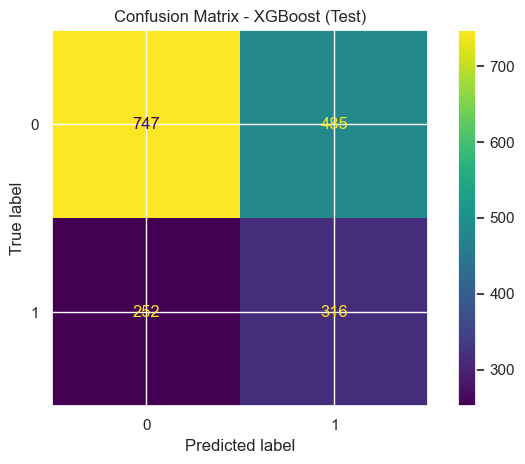

In [37]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb)
plt.title("Confusion Matrix - XGBoost (Test)")
plt.tight_layout()
plt.show()


Validació gràfica: Corva precision - recall

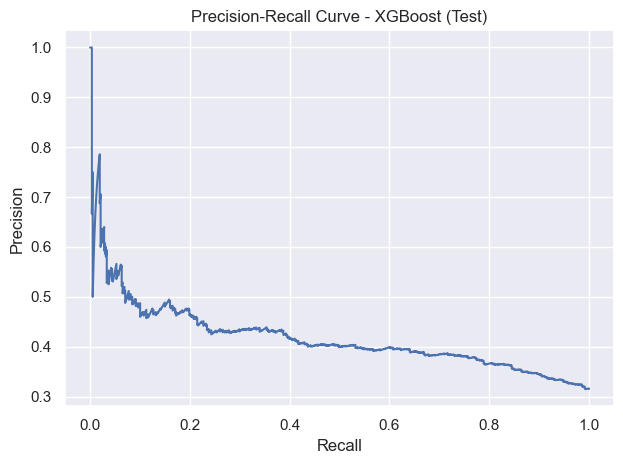

In [38]:
y_test_proba = best_xgb.predict_proba(X_test)[:, 1]

prec, rec, _ = precision_recall_curve(y_test, y_test_proba)

plt.figure()
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGBoost (Test)")
plt.tight_layout()
plt.show()


#### 3.3.3 Intents de millora

Iteració 1: Anàlisi d'hiperparàmetres

In [39]:

ratio = (y_train == 0).sum() / (y_train == 1).sum()

pipe_xgb = Pipeline([
    ("prep", preprocess),
    ("xgb", xgb.XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        use_label_encoder=False,
        verbosity=0
    ))
])

param_dist_xgb = {
    "xgb__n_estimators": [50, 100, 150, 200],
    "xgb__max_depth": [2, 3, 4, 5],
    "xgb__learning_rate": [0.01, 0.05],

    "xgb__subsample": [0.5, 0.6, 0.7, 0.8],
    "xgb__colsample_bytree": [0.5, 0.6, 0.7, 0.8],

    "xgb__min_child_weight": [3, 5, 10, 20],
    "xgb__gamma": [0.0, 0.3, 1.0, 2.0],

    "xgb__reg_alpha": [0.0, 0.1, 0.5, 1.0],
    "xgb__reg_lambda": [1.0, 2.0, 3.0, 5.0],

    "xgb__scale_pos_weight": [1.0, 1.3, 1.5, 1.8, ratio],
}

rs_xgb_extra = RandomizedSearchCV(
    estimator=pipe_xgb,
    param_distributions=param_dist_xgb,
    n_iter=15,
    cv=cv,
    scoring=scoring,          
    refit="f1_macro",         
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

rs_xgb_extra.fit(X_train, y_train)

best_xgb_extra = rs_xgb_extra.best_estimator_
print(f"Best CV F1-macro: {rs_xgb_extra.best_score_:.4f}")
rs_xgb_extra.best_params_


res_xgb_extra = pd.DataFrame(rs_xgb_extra.cv_results_)

cols_xgb = [
    "param_xgb__n_estimators",
    "param_xgb__max_depth",
    "param_xgb__learning_rate",
    "param_xgb__subsample",
    "param_xgb__colsample_bytree",
    "param_xgb__min_child_weight",
    "param_xgb__gamma",
    "param_xgb__reg_alpha",
    "param_xgb__reg_lambda",
    "param_xgb__scale_pos_weight",

    
    "mean_test_accuracy",
    "mean_test_precision_macro",
    "mean_test_recall_macro",
    "mean_test_f1_macro",
    "std_test_f1_macro",
    "rank_test_f1_macro",
]

table_xgb = (
    res_xgb_extra[cols_xgb]
    .sort_values("rank_test_f1_macro")
    .reset_index(drop=True)
)

table_xgb = table_xgb.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})


table_xgb.head(15)

Best CV F1-macro: 0.5801


,param_xgb__n_estimators,param_xgb__max_depth,param_xgb__learning_rate,param_xgb__subsample,param_xgb__colsample_bytree,param_xgb__min_child_weight,param_xgb__gamma,param_xgb__reg_alpha,param_xgb__reg_lambda,param_xgb__scale_pos_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro
0,100,3,0.05,0.8,0.6,5,0.0,1.0,3.0,1.800000,0.630556,0.579288,0.582143,0.580146,0.013968,1
1,100,4,0.01,0.6,0.5,20,2.0,0.0,3.0,2.171806,0.590972,0.585442,0.598518,0.573543,0.007794,2
2,100,4,0.01,0.7,0.6,10,1.0,1.0,3.0,2.171806,0.588750,0.584229,0.597252,0.571833,0.009590,3
3,100,5,0.05,0.7,0.5,20,1.0,0.0,2.0,2.171806,0.592500,0.576370,0.587512,0.569474,0.009562,4
4,100,3,0.01,0.7,0.5,3,1.0,0.1,3.0,2.171806,0.582361,0.582890,0.595676,0.567449,0.008906,5
5,200,5,0.05,0.7,0.7,5,0.0,0.0,5.0,2.171806,0.600139,0.568707,0.576689,0.566854,0.009672,6
6,100,3,0.05,0.7,0.8,20,0.0,0.1,5.0,1.500000,0.659722,0.581550,0.564104,0.564460,0.009116,7
7,50,3,0.05,0.5,0.5,10,1.0,0.5,2.0,1.500000,0.676667,0.593139,0.554966,0.546938,0.010593,8
8,100,4,0.05,0.8,0.6,5,1.0,0.1,1.0,1.300000,0.676667,0.590960,0.551282,0.541221,0.011473,9
9,100,3,0.05,0.8,0.8,20,2.0,0.0,1.0,1.300000,0.677778,0.592727,0.551499,0.540773,0.012090,10


In [40]:
y_pred_xgb_it1 = best_xgb_extra.predict(X_test)

metrics_xgb_extra = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_xgb_it1),
    "precision_macro": precision_score(y_test, y_pred_xgb_it1, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_xgb_it1, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_xgb_it1, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_xgb_it1, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_xgb_it1, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_xgb_it1, pos_label=1, zero_division=0),
}])

metrics_xgb_extra


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.611667,0.56495,0.569239,0.565805,0.398764,0.454225,0.424691


Taula resum

In [41]:

summary_xgb = pd.DataFrame([
    {
        "iteracio": "inicial",
        "f1_macro_train_cv": cv_train_test_f1(rs_xgb, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(rs_xgb, metric='f1_macro')[1],
        "f1_macro_test": metrics_xgb["f1_macro"].iloc[0],
    },
    {
        "iteracio": "1",
        "f1_macro_train_cv": cv_train_test_f1(rs_xgb_extra, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(rs_xgb_extra, metric='f1_macro')[1],
        "f1_macro_test": metrics_xgb_extra["f1_macro"].iloc[0],
    },
])

summary_xgb

,iteracio,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,inicial,0.742233,0.579667,0.565653
1,1,0.640965,0.580146,0.565805


### 3.4 Model regressió logística

3.4.1 Creació de la classe

In [44]:


class CustomLogisticRegression(BaseEstimator, ClassifierMixin):

    def __init__(self, lr=0.1, n_epochs=200, batch_size=64, reg_lambda=0.0,
                 class_weight=None,
                 fit_intercept=True, shuffle=True, random_state=42, verbose=False):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.reg_lambda = reg_lambda
        self.class_weight = class_weight
        self.fit_intercept = fit_intercept
        self.shuffle = shuffle
        self.random_state = random_state
        self.verbose = verbose

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        # y a vector 0/1
        y = np.asarray(y).astype(float).ravel()

        n_samples, n_features = X.shape
        rng = np.random.RandomState(self.random_state)

        # class_weight (None o "balanced")
        if self.class_weight is None:
            sample_weight = np.ones_like(y, dtype=float)
        else:
            # balanced: n_samples / (n_classes * bincount(y))
            counts = np.bincount(y.astype(int))
            w0 = n_samples / (2.0 * counts[0])
            w1 = n_samples / (2.0 * counts[1])
            sample_weight = np.where(y == 0.0, w0, w1).astype(float)

        # Inicialització
        self.coef_ = np.zeros(n_features, dtype=float)
        self.intercept_ = 0.0
        self.classes_ = np.array([0, 1])

        bs = int(self.batch_size)

        for epoch in range(int(self.n_epochs)):
            idx = np.arange(n_samples)
            if self.shuffle:
                rng.shuffle(idx)

            for start in range(0, n_samples, bs):
                batch_idx = idx[start:start + bs]
                Xb = X[batch_idx]
                yb = y[batch_idx]
                swb = sample_weight[batch_idx]

                # forward
                z = Xb.dot(self.coef_)
                if self.fit_intercept:
                    z = z + self.intercept_
                z = np.asarray(z).ravel()
                p = self._sigmoid(z)

                # gradients (ponderats)
                err = (p - yb) * swb
                den = swb.sum()

                grad_w = (Xb.T.dot(err)) / den
                if self.reg_lambda > 0:
                    grad_w = grad_w + self.reg_lambda * self.coef_

                if self.fit_intercept:
                    grad_b = np.sum(err) / den
                else:
                    grad_b = 0.0

                # update
                self.coef_ = self.coef_ - self.lr * np.asarray(grad_w).ravel()
                if self.fit_intercept:
                    self.intercept_ = self.intercept_ - self.lr * grad_b

            if self.verbose and (epoch % 50 == 0 or epoch == self.n_epochs - 1):
                z_all = X.dot(self.coef_) + (self.intercept_ if self.fit_intercept else 0.0)
                z_all = np.asarray(z_all).ravel()
                p_all = self._sigmoid(z_all)
                eps = 1e-12

                # loss ponderada
                loss = -np.sum(sample_weight * (y * np.log(p_all + eps) + (1 - y) * np.log(1 - p_all + eps))) / sample_weight.sum()
                if self.reg_lambda > 0:
                    loss += 0.5 * self.reg_lambda * np.sum(self.coef_ ** 2)

                print(f"epoch={epoch} loss={loss:.4f}")

        return self

    def decision_function(self, X):
        z = X.dot(self.coef_)
        if self.fit_intercept:
            z = z + self.intercept_
        return np.asarray(z).ravel()

    def predict_proba(self, X):
        z = self.decision_function(X)
        p1 = self._sigmoid(z)
        p0 = 1.0 - p1
        return np.vstack([p0, p1]).T

    def predict(self, X):
        proba = self.predict_proba(X)[:, 1]
        return (proba >= 0.5).astype(int)


#### 3.4.2 Anàlisi d'hiperparàmetres

In [45]:

pipe_lr = Pipeline([
    ("prep", preprocess),
    ("lr", CustomLogisticRegression(
        random_state=42
    ))
])

param_grid_lr = {
    "lr__batch_size": [4, 8, 16, 32, 64, 128],
    "lr__lr": [0.01, 0.05, 0.1],
    "lr__reg_lambda": [0.0, 1e-4, 1e-3],
    "lr__n_epochs": [200, 300, 400],
    "lr__class_weight": [None, "balanced"],
}

gs_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_lr.fit(X_train, y_train)

best_lr = gs_lr.best_estimator_
print(f"Best CV F1-macro: {gs_lr.best_score_:.4f}")
best_params_lr = gs_lr.best_params_
best_params_lr

res_lr = pd.DataFrame(gs_lr.cv_results_)

cols_lr = [
    "param_lr__batch_size",
    "param_lr__lr",
    "param_lr__reg_lambda",
    "param_lr__n_epochs",
    "param_lr__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_lr = res_lr[cols_lr].sort_values("rank_test_f1_macro").reset_index(drop=True)

table_lr = table_lr.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_lr.head(20)

Best CV F1-macro: 0.5964


,param_lr__batch_size,param_lr__lr,param_lr__reg_lambda,param_lr__n_epochs,param_lr__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
0,4,0.01,0.0010,200,balanced,0.639028,0.595189,0.601402,0.596408,0.008156,1,0.638403,0.595920,0.602610,0.596981
1,4,0.01,0.0000,200,balanced,0.638750,0.594552,0.600605,0.595762,0.009180,2,0.638750,0.596333,0.603042,0.597410
2,4,0.01,0.0001,200,balanced,0.638750,0.594552,0.600605,0.595762,0.009180,2,0.638611,0.596264,0.603000,0.597336
3,8,0.01,0.0010,400,balanced,0.628333,0.592371,0.601793,0.593056,0.006434,4,0.631771,0.596199,0.606027,0.596998
4,8,0.01,0.0001,400,balanced,0.627500,0.591746,0.601185,0.592374,0.005910,5,0.631736,0.596251,0.606120,0.597038
5,8,0.01,0.0000,400,balanced,0.627222,0.591454,0.600863,0.592065,0.005909,6,0.631701,0.596245,0.606125,0.597028
6,8,0.01,0.0010,200,balanced,0.620556,0.592713,0.604433,0.591414,0.004164,7,0.622917,0.595075,0.606930,0.593756
7,16,0.01,0.0010,400,balanced,0.618056,0.593668,0.606054,0.591133,0.008906,8,0.617743,0.593863,0.606569,0.591291
8,4,0.01,0.0010,400,balanced,0.644444,0.590687,0.592285,0.591111,0.011743,9,0.651389,0.599066,0.600030,0.598863
9,8,0.01,0.0000,200,balanced,0.620139,0.592328,0.604010,0.591008,0.003943,10,0.622743,0.595028,0.606922,0.593676


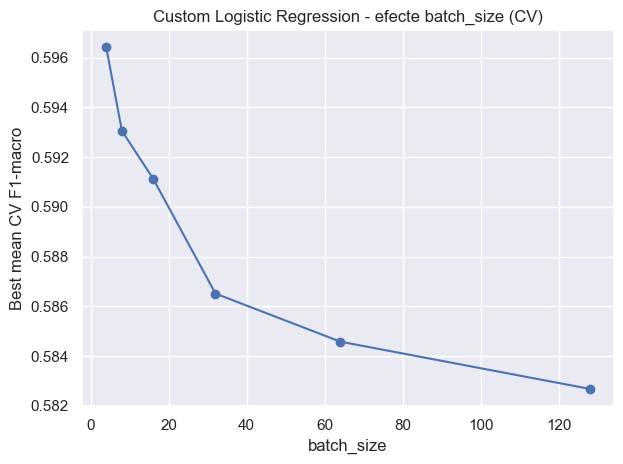

In [46]:

res = pd.DataFrame(gs_lr.cv_results_)

batch_plot = (
    res.groupby("param_lr__batch_size")["mean_test_f1_macro"]
       .max()
       .reset_index()
       .rename(columns={"mean_test_f1_macro": "best_mean_cv_f1_macro"})
)

plt.figure()
plt.plot(batch_plot["param_lr__batch_size"], batch_plot["best_mean_cv_f1_macro"], marker="o")
plt.xlabel("batch_size")
plt.ylabel("Best mean CV F1-macro")
plt.title("Custom Logistic Regression - efecte batch_size (CV)")
plt.tight_layout()
plt.show()

#### 3.4.3 Validació numèrica i gràfica

Validació numèrica: Mètriques

In [47]:
y_pred_lr_init = best_lr.predict(X_test)

metrics_lr = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_lr_init),
    "precision_macro": precision_score(y_test, y_pred_lr_init, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_lr_init, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_lr_init, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_lr_init, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_lr_init, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_lr_init, pos_label=1, zero_division=0),
}])

metrics_lr


,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.617222,0.578978,0.586582,0.579519,0.412698,0.503521,0.453608


Validació gràfica: Matriu de confusió

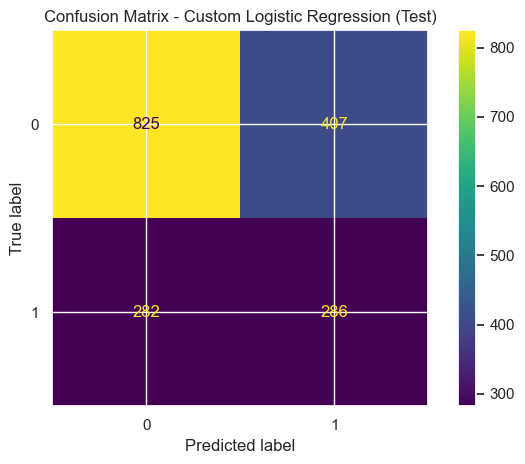

In [48]:

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_init)
plt.title("Confusion Matrix - Custom Logistic Regression (Test)")
plt.tight_layout()
plt.show()

Validació gràfica: Corva precision - recall

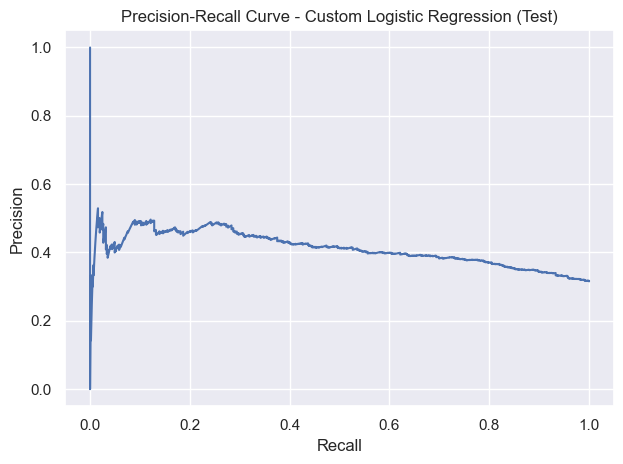

In [49]:
y_test_proba = best_lr.predict_proba(X_test)[:, 1]
prec, rec, _ = precision_recall_curve(y_test, y_test_proba)

plt.figure()
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Custom Logistic Regression (Test)")
plt.tight_layout()
plt.show()


#### 3.4.4 Intents de millora

Iteració 1: Nou anàlisi d'hiperparàmetres

In [50]:

pipe_lr_it1 = Pipeline([
    ("prep", preprocess),
    ("lr", CustomLogisticRegression(random_state=42))
])

param_grid_lr_it1 = {
    "lr__batch_size": [2, 4, 6, 8, 12, 16],
    "lr__lr": [0.005, 0.008, 0.01, 0.015],
    "lr__reg_lambda": [0.0, 1e-4, 3e-6],
    "lr__n_epochs": [200, 300, 400, 500],
    "lr__class_weight": ["balanced", None],
}

gs_lr_it1 = GridSearchCV(
    estimator=pipe_lr_it1,
    param_grid=param_grid_lr_it1,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_lr_it1.fit(X_train, y_train)

best_lr_it1 = gs_lr_it1.best_estimator_
print(f"Best CV F1-macro (LR iteració 1): {gs_lr_it1.best_score_:.4f}")
best_params_lr_it1 = gs_lr_it1.best_params_


res_lr_it1 = pd.DataFrame(gs_lr_it1.cv_results_)

cols_lr_it1 = [
    "param_lr__batch_size",
    "param_lr__lr",
    "param_lr__reg_lambda",
    "param_lr__n_epochs",
    "param_lr__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_lr_it1 = res_lr_it1[cols_lr_it1].sort_values("rank_test_f1_macro").reset_index(drop=True)

table_lr_it1 = table_lr_it1.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_lr_it1

Best CV F1-macro (LR iteració 1): 0.5960


,param_lr__batch_size,param_lr__lr,param_lr__reg_lambda,param_lr__n_epochs,param_lr__class_weight,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
0,4,0.008,0.000100,200,balanced,0.639583,0.594567,0.600382,0.595966,0.007879,1,0.640174,0.596852,0.603220,0.598045
1,4,0.008,0.000003,200,balanced,0.639444,0.594380,0.600162,0.595778,0.007832,2,0.640208,0.596879,0.603245,0.598076
2,4,0.008,0.000000,200,balanced,0.639444,0.594380,0.600162,0.595778,0.007832,2,0.640208,0.596879,0.603245,0.598076
3,4,0.010,0.000100,200,balanced,0.638750,0.594552,0.600605,0.595762,0.009180,4,0.638611,0.596264,0.603000,0.597336
4,4,0.010,0.000003,200,balanced,0.638750,0.594552,0.600605,0.595762,0.009180,4,0.638750,0.596333,0.603042,0.597410
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,8,0.010,0.000000,400,None,0.687917,0.613623,0.533232,0.496923,0.012703,569,0.691979,0.627797,0.537387,0.502365
572,12,0.015,0.000100,400,None,0.687917,0.613623,0.533232,0.496923,0.012703,569,0.692014,0.628055,0.537353,0.502253
573,6,0.008,0.000100,400,None,0.688056,0.614115,0.533215,0.496711,0.013209,574,0.691944,0.627548,0.537362,0.502309
574,6,0.008,0.000003,400,None,0.687917,0.613722,0.533113,0.496619,0.013060,575,0.691875,0.627207,0.537341,0.502340


In [51]:

y_pred_lr_it1 = best_lr_it1.predict(X_test)


metrics_lr_it1 = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_lr_it1),
    "precision_macro": precision_score(y_test, y_pred_lr_it1, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_lr_it1, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_lr_it1, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_lr_it1, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_lr_it1, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_lr_it1, pos_label=1, zero_division=0),
}])

metrics_lr_it1

,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.620556,0.582497,0.59044,0.583181,0.417027,0.508803,0.458366


Taula resum

In [52]:

summary_lr_compare = pd.DataFrame([
    {
        "model": "LR (inicial)",
        "f1_macro_train_cv": cv_train_test_f1(gs_lr, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_lr, metric='f1_macro')[1],
        "f1_macro_test":     metrics_lr["f1_macro"].iloc[0],
    },
    {
        "model": "LR (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_lr_it1, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_lr_it1, metric='f1_macro')[1],
        "f1_macro_test":     metrics_lr_it1["f1_macro"].iloc[0],
    },
]).sort_values(["f1_macro_test_cv", "f1_macro_test"], ascending=False).reset_index(drop=True)

summary_lr_compare

,model,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,LR (inicial),0.596981,0.596408,0.579519
1,LR (iteració 1),0.598045,0.595966,0.583181


***
## SECCIÓ 4: Selecció de model

### 4.1 Comparativa de mètriques

In [158]:

summary_models = pd.DataFrame([
    {
        "model": "SVM (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm_fine["f1_macro"].iloc[0],
    },
    {
        "model": "XGBoost (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(rs_xgb_extra, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(rs_xgb_extra, metric='f1_macro')[1],
        "f1_macro_test":     metrics_xgb_extra["f1_macro"].iloc[0],
    },
    {
        "model": "LR (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_lr_it1, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_lr_it1, metric='f1_macro')[1],
        "f1_macro_test":     metrics_lr_it1["f1_macro"].iloc[0],
    },
]).sort_values("f1_macro_test_cv", ascending=False).reset_index(drop=True)

summary_models

,model,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,LR (iteració 1),0.598045,0.595966,0.583181
1,SVM (iteració 1),0.593809,0.592394,0.572873
2,XGBoost (iteració 1),0.640965,0.580146,0.565805


### 4.2 Creació del fitxer submission

In [160]:

best_lr = gs_lr.best_estimator_
print("Best params (LR):", gs_lr.best_params_)

patient_ids = df_eval["patient_id"]

best_lr.fit(X_train_full, y_train_full)
y_pred = best_lr.predict(X_eval)

submission = pd.DataFrame({
    "patient_id": patient_ids,
    "TRS": y_pred
})
submission.to_csv("submission.csv", index=False)

print("Submission file created: submission.csv")
print(f"Submission shape: {submission.shape}")
print(submission.head(10))

Best params (LR): {'lr__batch_size': 4, 'lr__class_weight': 'balanced', 'lr__lr': 0.01, 'lr__n_epochs': 200, 'lr__reg_lambda': 0.001}
Submission file created: submission.csv
Submission shape: (1000, 2)
   patient_id  TRS
0           1    0
1           2    0
2           3    0
3           4    0
4           5    0
5           6    1
6           7    0
7           8    0
8           9    1
9          10    0


***
## SECCIÓ 5: Model Card

In [58]:
#Executar nomès si cal instal·lar

'''%pip install verifyml
%pip install seaborn

%pip install protobuf==3.20'''


'%pip install verifyml\n%pip install seaborn\n\n%pip install protobuf==3.20'

### Carreguem i dividim les dades

In [59]:

df = pd.read_csv("trs_train.csv")

X = df.drop(columns=["patient_id", "TRS"])
y = df["TRS"].copy()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, test_size=0.2, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Number of features: {X_train.shape[1]}")


Training set: 7200 samples
Test set: 1800 samples
Number of features: 26


In [60]:
X_train.head()

,Age,Sex,Ethnicity,Duration_untreated_psychosis,Family_history,Initial_response,Lymphocyte_count,Neutrophil_count,BMI,Triglycerides,Glucose,Alkaline_phosphatase,Prior_antipsychotics,CYP2D6_metabolic_phenotype,HLA_DRB1_04_02,HLA_B_15_02,HLA_A_31_01,Polygenic_risk_score,Del_22q11_2_status,IL_17A,CCL23,TWEAK,Ki_whole_striatum,Ki_associative_striatum,SUVRc_whole_striatum,SUVRc_associative_striatum
3221,30.0,0,Asian,1.9,0,95.1,1.72,6.38,19.5,62.3,65.0,NaN,1,Extensive,0,0,0,-0.028,0,2.86,4.87,3.82,0.01249,0.01186,1.008,1.308
5250,13.0,1,Caucasian,13.5,0,83.4,0.84,5.85,23.0,133.6,NaN,64.4,0,Extensive,0,1,0,0.222,0,2.10,4.99,3.13,0.01069,0.01044,0.800,0.816
3642,19.0,1,African,14.8,0,38.6,1.35,5.15,26.7,79.5,82.9,54.1,1,Extensive,0,0,0,0.144,0,2.91,4.66,4.94,0.01048,0.00955,1.233,1.060
7927,28.0,0,Caucasian,40.8,0,19.6,NaN,NaN,42.2,219.9,123.4,NaN,0,Extensive,0,0,0,0.135,0,2.43,4.27,3.01,0.01202,0.01205,1.037,0.803
5384,28.0,1,Asian,11.4,0,45.2,2.88,NaN,25.8,222.9,88.4,84.2,0,Extensive,0,0,0,-0.046,0,3.13,2.53,4.10,0.01483,0.01568,1.559,1.850


In [61]:
print("Target distribution (0=NTRS, 1=TRS):")
print(y_train.value_counts())


Target distribution (0=NTRS, 1=TRS):
TRS
0    4930
1    2270
Name: count, dtype: int64


### 5.2 Anàlisi de variables

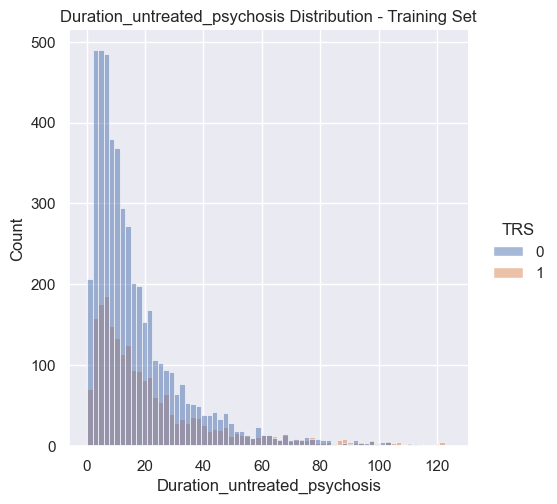

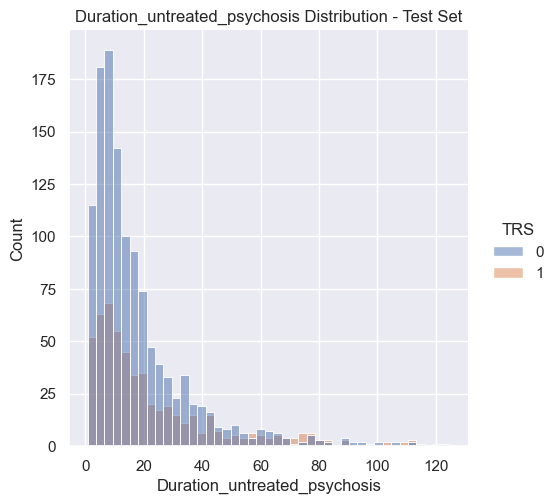

In [62]:

sns.displot(x=X_train['Duration_untreated_psychosis'], hue=y_train)
plt.title('Duration_untreated_psychosis Distribution - Training Set')
mean_radius_train = utils.plot_to_str()

sns.displot(x=X_test['Duration_untreated_psychosis'], hue=y_test)
plt.title('Duration_untreated_psychosis Distribution - Test Set')
mean_radius_test = utils.plot_to_str()


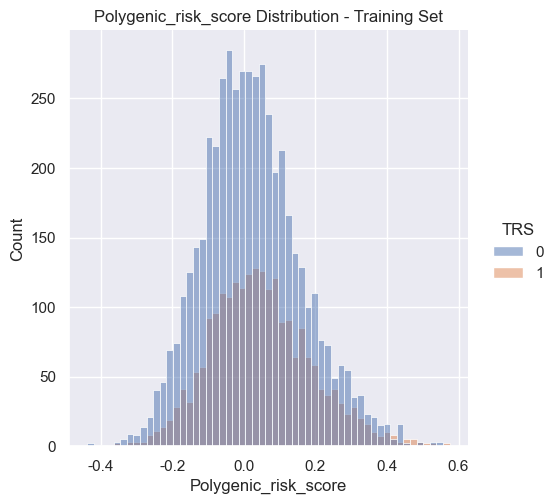

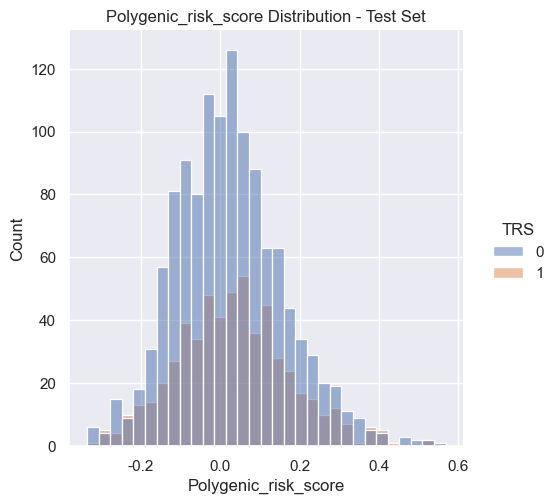

In [63]:

sns.displot(x=X_train['Polygenic_risk_score'], hue=y_train)
plt.title('Polygenic_risk_score Distribution - Training Set')
mean_texture_train = utils.plot_to_str()

sns.displot(x=X_test['Polygenic_risk_score'], hue=y_test)
plt.title('Polygenic_risk_score Distribution - Test Set')
mean_texture_test = utils.plot_to_str()


### 5.3 Entrenem el model

In [64]:

clf = best_lr.fit(X_train, y_train)


train_f1_macro = f1_score(y_train, clf.predict(X_train), average="macro", zero_division=0)
test_f1_macro = f1_score(y_test, clf.predict(X_test), average="macro", zero_division=0)

print(f"Training F1-macro: {train_f1_macro:.4f}")
print(f"Test F1-macro: {test_f1_macro:.4f}")

Training F1-macro: 0.6012
Test F1-macro: 0.5795


### 5.4 Validació gràfica del model

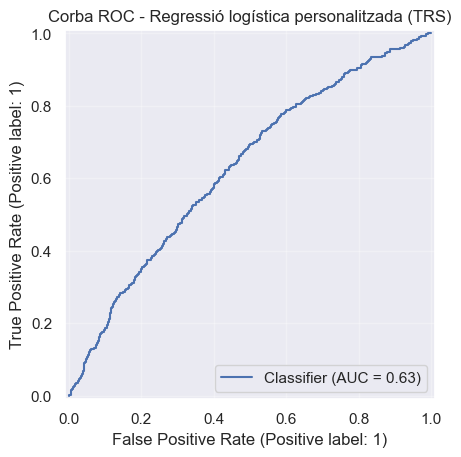

In [65]:

y_score = clf.predict_proba(X_test)[:, 1]
RocCurveDisplay.from_predictions(y_test, y_score)

plt.title("Corba ROC - Regressió logística personalitzada (TRS)")
plt.grid(alpha=0.3)
roc_curve = utils.plot_to_str()

In [ ]:
plt.figure()

y_pred = clf.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["NTRS(0)", "TRS(1)"],
    cmap="Blues",
    values_format="d"
)
plt.title("Matriu de confusió - Model (test)")

confusion_matrix_img = utils.plot_to_str()

plt.close()

<Figure size 640x480 with 0 Axes>

### 5.5 Creació de Model Card amb VerifyML

Inicialitzar Model Card Toolkit

In [132]:

mct = mctlib.ModelCardToolkit(
    output_dir='model_card_trs_lr_output',
    file_name='custom_lr_trs_model_card'
)

model_card = mct.scaffold_assets()

print(f"Model card inicialitzada a: {mct.output_dir}")


Model card inicialitzada a: model_card_trs_lr_output


Detalls del model

In [163]:

model_card.model_details.name = 'Conjunt TRS - Regressió logística personalitzada (inicial)'

model_card.model_details.overview = (
    'Aquest model prediu si un pacient presenta esquizofrènia resistent al tractament (TRS=1) o '
    'no resistent (NTRS=0) a partir de variables demogràfiques, clíniques, de laboratori, genètiques '
    'i de neuroimatge. El classificador és una regressió logística implementada manualment (CustomLogisticRegression) '
    'i entrenada dins un Pipeline amb preprocessament (imputació, escalat i one-hot encoding). '
    'En el context de la pràctica, la mètrica principal d’avaluació és el F1 macro.'
)


model_card.model_details.owners = [
    mctlib.Owner(
        name='Irene Miralles (estudiant IAA)',
        contact='irene.miralles.ortega@estudiantat.upc.edu',
        role='Estudiant'
    )
]


model_card.model_details.references = [
    mctlib.Reference(reference='IAA 25/26 Q1 - Laboratori TRS (Pràctica)'),
    mctlib.Reference(reference='https://scikit-learn.org/stable/'),
    mctlib.Reference(reference='https://xgboost.readthedocs.io/en/stable/parameter.html'),
]


model_card.model_details.version.name = str(uuid.uuid4())
model_card.model_details.version.date = str(date.today())

print("Detalls del model configurats ✓")


Detalls del model configurats ✓


Consideracions del model

In [164]:

model_card.considerations.ethical_considerations = [
    mctlib.Risk(
        name='Biaix i desigualtat de rendiment per subgrups (p. ex. sexe, etnicitat) en un problema de salut mental',
        mitigation_strategy='Avaluar mètriques per subgrups, reportar limitacions i evitar ús clínic o automatització de decisions'
    )
]


model_card.considerations.limitations = [
    mctlib.Limitation(
        description=(
            'Aquest model té limitacions tècniques conegudes: '
            '1) Pot no generalitzar fora del conjunt de dades proporcionat (dataset shift). '
            '2) Depèn del preprocessament (imputació, escalat i one-hot) i del mateix esquema de variables. '
            '3) El desbalanceig de classes pot afectar el rendiment i la interpretació. '
            '4) No està validat com a eina clínica; és només per finalitat educativa.'
        )
    )
]


model_card.considerations.use_cases = [
    mctlib.UseCase(
        description=(
            'L\'intenció d\'ús d\'aquest model és educativa (pràctica d\'Introducció a l\'Aprenentatge Automàtic) '
            'per explorar preprocessament, validació i documentació mitjançant una Model Card. '
            'Aquest model NO té cap intenció de ser usat per a diagnòstic o decisions clíniques.'
        )
    )
]


model_card.considerations.users = [
    mctlib.User(description='Estudiants de IAA'),
    mctlib.User(description='Professors de IAA')
]

print("Consideracions configurades ✓")


Consideracions configurades ✓


### 5.6 Afegits i actualització

In [165]:

mc_dataset_train = mctlib.Dataset()
mc_dataset_train.name = "Conjunt d'entrenament"
mc_dataset_train.graphics.description = (
    f'{len(X_train)} files amb {len(X_train.columns)} característiques. '
    f'Distribució de classes: {y_train.value_counts().to_dict()}'
)
mc_dataset_train.graphics.collection = [
    mctlib.Graphic(image=mean_radius_train, name='Duration_untreated_psychosis Distribució - Entrenament'),
    mctlib.Graphic(image=mean_texture_train, name='Polygenic_risk_score Distribució - Entrenament')
]


mc_dataset_test = mctlib.Dataset()
mc_dataset_test.name = 'Conjunt de test'
mc_dataset_test.graphics.description = (
    f'{len(X_test)} files amb {len(X_test.columns)} característiques. '
    f'Distribució de classes: {y_test.value_counts().to_dict()}'
)
mc_dataset_test.graphics.collection = [
    mctlib.Graphic(image=mean_radius_test, name='Duration_untreated_psychosis Distribució - Test'),
    mctlib.Graphic(image=mean_texture_test, name='Polygenic_risk_score Distribució - Test')
]

model_card.model_parameters.data = [mc_dataset_train, mc_dataset_test]

print("Paràmetres del model i dades configurats ✓")


Paràmetres del model i dades configurats ✓


In [166]:

model_card.quantitative_analysis.performance_metrics = [
    mctlib.PerformanceMetric(
        type='f1_macro',
        slice='training',
        value=f'{train_f1_macro:.4f}',
    ),
    mctlib.PerformanceMetric(
        type='f1_macro',
        slice='test',
        value=f'{test_f1_macro:.4f}',
    )
]


model_card.quantitative_analysis.graphics.description = (
    'Corba ROC i matriu de confusió per avaluar el model sobre el conjunt de test'
)
model_card.quantitative_analysis.graphics.collection = [
    mctlib.Graphic(image=roc_curve, name='Corba ROC'),
    mctlib.Graphic(image=confusion_matrix_img, name='Matriu de confusió')
]

print("Mètriques de rendiment configurades ✓")


Mètriques de rendiment configurades ✓


In [167]:

mct.update_model_card(model_card)

print("Model card actualitzada correctament ✓")


Model card actualitzada correctament ✓


In [168]:

md = mct.export_format(
    output_file='custom_lr_trs_model_card.md',
    template_path=f'{mct.output_dir}/template/md/default_template.md.jinja'
)

print(f"Model card en Markdown guardada a: {mct.output_dir}/model_cards/custom_lr_trs_model_card.md")


Model card en Markdown guardada a: model_card_trs_lr_output/model_cards/custom_lr_trs_model_card.md


### 5.7 Exportem com a Markdown

In [169]:

Markdown(md)



























# Model Card for Conjunt TRS - Regressió logística personalitzada (inicial)

## Model Details

### Overview
Aquest model prediu si un pacient presenta esquizofrènia resistent al tractament (TRS=1) o no resistent (NTRS=0) a partir de variables demogràfiques, clíniques, de laboratori, genètiques i de neuroimatge. El classificador és una regressió logística implementada manualment (CustomLogisticRegression) i entrenada dins un Pipeline amb preprocessament (imputació, escalat i one-hot encoding). En el context de la pràctica, la mètrica principal d’avaluació és el F1 macro. 

### Version
  
name: 1e243237-5481-4d33-aa27-8d6d8d3953c0 

  
date: 2025-12-28 

  

### Owners

* Irene Miralles (estudiant IAA)(owner.role), irene.miralles.ortega@estudiantat.upc.edu 


### References

* [IAA 25/26 Q1 - Laboratori TRS (Pràctica)](IAA 25/26 Q1 - Laboratori TRS (Pràctica))
* [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
* [https://xgboost.readthedocs.io/en/stable/parameter.html](https://xgboost.readthedocs.io/en/stable/parameter.html)


## Considerations

### Intended Users 
* Estudiants de IAA
* Professors de IAA


### Use Cases

* L&#39;intenció d&#39;ús d&#39;aquest model és educativa (pràctica d&#39;Introducció a l&#39;Aprenentatge Automàtic) per explorar preprocessament, validació i documentació mitjançant una Model Card. Aquest model NO té cap intenció de ser usat per a diagnòstic o decisions clíniques.



### Limitations

* Aquest model té limitacions tècniques conegudes: 1) Pot no generalitzar fora del conjunt de dades proporcionat (dataset shift). 2) Depèn del preprocessament (imputació, escalat i one-hot) i del mateix esquema de variables. 3) El desbalanceig de classes pot afectar el rendiment i la interpretació. 4) No està validat com a eina clínica; és només per finalitat educativa.




### Ethical Considerations

* __Risk:__ Biaix i desigualtat de rendiment per subgrups (p. ex. sexe, etnicitat) en un problema de salut mental
  * __Mitigation Strategy:__ Avaluar mètriques per subgrups, reportar limitacions i evitar ús clínic o automatització de decisions







## Datasets
  
    
### Conjunt d&#39;entrenament
    
    
    
#### Sensitive data
    
    
    
    
    
    
      
  
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;401.83pt&#39; height=&#39;363.31pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 401.83 363.31&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 363.31h401.83v-363.31h-401.83z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m50.025 321.43h287.36v-299.5h-287.36z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m62.456 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(59.398 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m104.52 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- 20 --%3e %3cg transform=&#39;translate(98.407 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_3&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m146.59 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- 40 --%3e %3cg transform=&#39;translate(140.47 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_4&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m188.66 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- 60 --%3e %3cg transform=&#39;translate(182.54 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-36&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_5&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cpath d=&#39;m230.73 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- 80 --%3e %3cg transform=&#39;translate(224.61 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-38&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1131 2484q-350 129-519 366-168 238-168 569 0 500 359 840 360 341 956 341 600 0 966-349 366-348 366-848 0-319-168-555-167-235-507-364 422-137 642-444 220-306 220-731 0-587-416-987-415-400-1093-400t-1094 401q-416 402-416 1002 0 447 227 748 227 302 645 411zm-112 954q0-325 209-532 210-206 544-206 325 0 533 204 208 205 208 502 0 310-215 521-214 211-532 211-322 0-535-207-212-206-212-493zm-181-2116q0-241 114-466t339-349q225-123 484-123 403 0 665 259 263 260 263 660 0 406-270 672t-677 266q-397 0-658-263-260-262-260-656z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_6&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cpath d=&#39;m272.79 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(263.62 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_7&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cpath d=&#39;m314.86 321.43v-299.5&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- 120 --%3e %3cg transform=&#39;translate(305.69 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- Duration_untreated_psychosis --%3e %3cg transform=&#39;translate(112.66 353.58) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-44&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1578q534 0 816-65 393-91 671-328 363-307 542-784 180-476 180-1088 0-522-122-925-121-403-312-668-191-264-418-416-226-151-546-229t-736-78h-1653zm606 541h978q453 0 711 84t411 238q216 215 336 579t120 883q0 719-236 1105t-573 517q-244 94-784 94h-963v-3500z&#39;/%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-61&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 409q-313-265-602-375-289-109-620-109-547 0-841 267t-294 683q0 244 111 445 111 202 291 324t405 184q165 44 500 85 681 81 1003 193 3 116 3 147 0 344-160 485-215 190-640 190-397 0-586-139t-280-492l-550 75q75 353 247 570t497 334q325 118 753 118 425 0 690-100 266-100 391-252 125-151 175-383 28-143 28-518v-750q0-785 36-993 36-207 143-398h-588q-87 175-112 409zm-47 1257q-307-125-919-213-347-50-491-113-143-62-222-182-78-120-78-267 0-225 170-375 171-150 499-150 325 0 578 142t372 389q91 191 91 562v207z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-5f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m-97-1272v406h3728v-406h-3728z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-64&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2575 0v419q-316-494-928-494-397 0-730 219t-516 611q-182 392-182 901 0 497 165 902 166 405 497 620 332 216 741 216 300 0 534-127 235-126 382-329v1643h559v-4581h-522zm-1778 1656q0-637 268-953 269-315 635-315 369 0 626 301 258 302 258 920 0 682-263 1e3 -262 319-646 319-375 0-627-306-251-306-251-966z&#39;/%3e %3cpath id=&#39;ArialMT-70&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422-1272v4591h512v-431q182 253 410 379 228 127 553 127 425 0 750-219t490-618q166-398 166-873 0-509-183-917-182-408-531-625-348-217-733-217-281 0-505 119-223 119-367 300v-1616h-562zm509 2913q0-641 259-947 260-306 629-306 375 0 642 317t267 983q0 634-261 949-261 316-623 316-360 0-637-336-276-336-276-976z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-79&#39; transform=&#39;scale(.015625)&#39; d=&#39;m397-1278-63 528q185-50 322-50 188 0 300 63 113 62 185 174 53 85 172 419 15 47 50 138l-1260 3325h606l691-1922q134-366 241-769 97 388 231 756l709 1935h563l-1263-3375q-203-547-315-753-150-279-344-408-194-130-463-130-162 0-362 69z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-68&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v4581h562v-1643q394 456 994 456 369 0 641-146 272-145 389-401t117-744v-2103h-562v2103q0 422-183 614t-517 192q-250 0-471-130-220-129-314-351t-94-612v-1816h-562z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(161.13)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(216.75)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(244.53)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(266.75)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(322.36)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(377.98)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(544.82)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(572.61)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(605.91)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(661.52)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(717.14)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(744.92)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(800.54)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(856.15)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(911.77)&#39; xlink:href=&#39;%23ArialMT-70&#39;/%3e %3cuse transform=&#39;translate(967.38)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1017.4)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(1067.4)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(1117.4)&#39; xlink:href=&#39;%23ArialMT-68&#39;/%3e %3cuse transform=&#39;translate(1173)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1228.6)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1278.6)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1300.8)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cpath d=&#39;m50.025 321.43h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(34.408 325.37) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cpath d=&#39;m50.025 263.22h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(22.174 267.16) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cpath d=&#39;m50.025 205.01h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- 200 --%3e %3cg transform=&#39;translate(22.174 208.95) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_11&#39;%3e %3cpath d=&#39;m50.025 146.8h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 300 --%3e %3cg transform=&#39;translate(22.174 150.74) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-33&#39; transform=&#39;scale(.015625)&#39; d=&#39;m269 1209 562 75q97-478 330-689t567-211q397 0 670 275 274 275 274 682 0 387-253 638-253 252-644 252-159 0-397-62l63 494q56-7 90-7 360 0 647 187 288 188 288 579 0 309-210 512-209 204-540 204-328 0-547-207-219-206-281-618l-563 100q103 565 468 876 366 311 910 311 375 0 690-161 316-161 483-439 168-278 168-591 0-296-160-540-159-244-471-388 406-93 631-389 225-295 225-739 0-600-438-1017-437-417-1106-417-603 0-1002 359-398 360-454 931z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-33&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_12&#39;%3e %3cpath d=&#39;m50.025 88.588h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 400 --%3e %3cg transform=&#39;translate(22.174 92.524) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_13&#39;%3e %3cpath d=&#39;m50.025 30.376h287.36&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- 500 --%3e %3cg transform=&#39;translate(22.174 34.313) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-35&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 1200 590 50q66-431 305-649 239-217 577-217 406 0 687 306 281 307 281 813 0 481-270 759-270 279-708 279-272 0-491-124-218-123-343-320l-528 69 443 2353h2279v-538h-1829l-246-1231q412 288 865 288 600 0 1012-416 413-416 413-1069 0-622-362-1075-441-556-1203-556-625 0-1021 350-395 350-451 928z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- Count --%3e %3cg transform=&#39;translate(15.789 187.69) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-43&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3763 1606 606-153q-191-747-686-1139t-1211-392q-741 0-1205 301-464 302-706 874t-242 1228q0 716 273 1248 274 533 778 809 505 277 1111 277 688 0 1156-350 469-350 654-984l-597-141q-160 500-463 728-303 229-762 229-528 0-883-254-355-253-499-680-143-426-143-879 0-584 170-1020t529-652q360-215 779-215 509 0 862 293 354 294 479 872z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(183.45)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(239.06)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m63.087 321.43h3.8991v-40.748h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m66.987 321.43h3.8991v-91.974h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m70.886 321.43h3.8991v-101.87h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m74.785 321.43h3.8991v-107.69h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m78.684 321.43h3.8991v-86.735h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_8&#39;%3e %3cpath d=&#39;m82.583 321.43h3.8991v-78.003h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_9&#39;%3e %3cpath d=&#39;m86.482 321.43h3.8991v-66.361h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_10&#39;%3e %3cpath d=&#39;m90.381 321.43h3.8991v-72.764h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_11&#39;%3e %3cpath d=&#39;m94.28 321.43h3.8991v-54.719h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_12&#39;%3e %3cpath d=&#39;m98.179 321.43h3.8991v-54.137h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_13&#39;%3e %3cpath d=&#39;m102.08 321.43h3.8991v-47.151h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_14&#39;%3e %3cpath d=&#39;m105.98 321.43h3.8991v-49.48h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_15&#39;%3e %3cpath d=&#39;m109.88 321.43h3.8991v-34.927h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_16&#39;%3e %3cpath d=&#39;m113.78 321.43h3.8991v-31.434h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_17&#39;%3e %3cpath d=&#39;m117.67 321.43h3.8991v-37.255h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_18&#39;%3e %3cpath d=&#39;m121.57 321.43h3.8991v-22.702h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_19&#39;%3e %3cpath d=&#39;m125.47 321.43h3.8991v-16.881h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_20&#39;%3e %3cpath d=&#39;m129.37 321.43h3.8991v-19.21h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_21&#39;%3e %3cpath d=&#39;m133.27 321.43h3.8991v-16.299h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_22&#39;%3e %3cpath d=&#39;m137.17 321.43h3.8991v-20.956h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_23&#39;%3e %3cpath d=&#39;m141.07 321.43h3.8991v-19.792h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_24&#39;%3e %3cpath d=&#39;m144.97 321.43h3.8991v-15.135h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_25&#39;%3e %3cpath d=&#39;m148.87 321.43h3.8991v-11.06h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_26&#39;%3e %3cpath d=&#39;m152.77 321.43h3.8991v-12.224h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_27&#39;%3e %3cpath d=&#39;m156.67 321.43h3.8991v-11.642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_28&#39;%3e %3cpath d=&#39;m160.56 321.43h3.8991v-13.971h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_29&#39;%3e %3cpath d=&#39;m164.46 321.43h3.8991v-6.9854h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_30&#39;%3e %3cpath d=&#39;m168.36 321.43h3.8991v-9.3138h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_31&#39;%3e %3cpath d=&#39;m172.26 321.43h3.8991v-7.5675h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_32&#39;%3e %3cpath d=&#39;m176.16 321.43h3.8991v-6.9854h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_33&#39;%3e %3cpath d=&#39;m180.06 321.43h3.8991v-5.8211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_34&#39;%3e %3cpath d=&#39;m183.96 321.43h3.8991v-6.4033h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_35&#39;%3e %3cpath d=&#39;m187.86 321.43h3.8991v-8.1496h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_36&#39;%3e %3cpath d=&#39;m191.76 321.43h3.8991v-8.1496h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_37&#39;%3e %3cpath d=&#39;m195.66 321.43h3.8991v-6.9854h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_38&#39;%3e %3cpath d=&#39;m199.56 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_39&#39;%3e %3cpath d=&#39;m203.45 321.43h3.8991v-7.5675h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_40&#39;%3e %3cpath d=&#39;m207.35 321.43h3.8991v-3.4927h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_41&#39;%3e %3cpath d=&#39;m211.25 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_42&#39;%3e %3cpath d=&#39;m215.15 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_43&#39;%3e %3cpath d=&#39;m219.05 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_44&#39;%3e %3cpath d=&#39;m222.95 321.43h3.8991v-6.4033h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_45&#39;%3e %3cpath d=&#39;m226.85 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_46&#39;%3e %3cpath d=&#39;m230.75 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_47&#39;%3e %3cpath d=&#39;m234.65 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_48&#39;%3e %3cpath d=&#39;m238.55 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_49&#39;%3e %3cpath d=&#39;m242.45 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_50&#39;%3e %3cpath d=&#39;m246.34 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_51&#39;%3e %3cpath d=&#39;m250.24 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_52&#39;%3e %3cpath d=&#39;m254.14 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_53&#39;%3e %3cpath d=&#39;m258.04 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_54&#39;%3e %3cpath d=&#39;m261.94 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_55&#39;%3e %3cpath d=&#39;m265.84 321.43h3.8991v-4.0748h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_56&#39;%3e %3cpath d=&#39;m269.74 321.43h3.8991v-1.7463h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_57&#39;%3e %3cpath d=&#39;m273.64 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_58&#39;%3e %3cpath d=&#39;m277.54 321.43h3.8991v-3.4927h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_59&#39;%3e %3cpath d=&#39;m281.44 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_60&#39;%3e %3cpath d=&#39;m285.34 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_61&#39;%3e %3cpath d=&#39;m289.23 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_62&#39;%3e %3cpath d=&#39;m293.13 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_63&#39;%3e %3cpath d=&#39;m297.03 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_64&#39;%3e %3cpath d=&#39;m300.93 321.43h3.8991v-1.7463h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_65&#39;%3e %3cpath d=&#39;m304.83 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_66&#39;%3e %3cpath d=&#39;m308.73 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_67&#39;%3e %3cpath d=&#39;m312.63 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_68&#39;%3e %3cpath d=&#39;m316.53 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_69&#39;%3e %3cpath d=&#39;m320.43 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_70&#39;%3e %3cpath d=&#39;m63.087 321.43h3.8991v-120.5h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_71&#39;%3e %3cpath d=&#39;m66.987 321.43h3.8991v-285.24h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_72&#39;%3e %3cpath d=&#39;m70.886 321.43h3.8991v-285.24h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_73&#39;%3e %3cpath d=&#39;m74.785 321.43h3.8991v-282.33h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_74&#39;%3e %3cpath d=&#39;m78.684 321.43h3.8991v-221.2h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_75&#39;%3e %3cpath d=&#39;m82.583 321.43h3.8991v-214.8h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_76&#39;%3e %3cpath d=&#39;m86.482 321.43h3.8991v-171.14h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_77&#39;%3e %3cpath d=&#39;m90.381 321.43h3.8991v-158.33h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_78&#39;%3e %3cpath d=&#39;m94.28 321.43h3.8991v-117h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_79&#39;%3e %3cpath d=&#39;m98.179 321.43h3.8991v-115.26h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_80&#39;%3e %3cpath d=&#39;m102.08 321.43h3.8991v-89.063h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_81&#39;%3e %3cpath d=&#39;m105.98 321.43h3.8991v-97.795h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_82&#39;%3e %3cpath d=&#39;m109.88 321.43h3.8991v-61.704h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_83&#39;%3e %3cpath d=&#39;m113.78 321.43h3.8991v-59.958h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_84&#39;%3e %3cpath d=&#39;m117.67 321.43h3.8991v-54.719h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_85&#39;%3e %3cpath d=&#39;m121.57 321.43h3.8991v-52.972h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_86&#39;%3e %3cpath d=&#39;m125.47 321.43h3.8991v-37.255h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_87&#39;%3e %3cpath d=&#39;m129.37 321.43h3.8991v-44.823h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_88&#39;%3e %3cpath d=&#39;m133.27 321.43h3.8991v-30.852h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_89&#39;%3e %3cpath d=&#39;m137.17 321.43h3.8991v-30.27h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_90&#39;%3e %3cpath d=&#39;m141.07 321.43h3.8991v-29.106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_91&#39;%3e %3cpath d=&#39;m144.97 321.43h3.8991v-22.12h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_92&#39;%3e %3cpath d=&#39;m148.87 321.43h3.8991v-22.12h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_93&#39;%3e %3cpath d=&#39;m152.77 321.43h3.8991v-24.449h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_94&#39;%3e %3cpath d=&#39;m156.67 321.43h3.8991v-19.21h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_95&#39;%3e %3cpath d=&#39;m160.56 321.43h3.8991v-23.867h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_96&#39;%3e %3cpath d=&#39;m164.46 321.43h3.8991v-16.299h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_97&#39;%3e %3cpath d=&#39;m168.36 321.43h3.8991v-10.478h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_98&#39;%3e %3cpath d=&#39;m172.26 321.43h3.8991v-10.478h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_99&#39;%3e %3cpath d=&#39;m176.16 321.43h3.8991v-8.1496h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_100&#39;%3e %3cpath d=&#39;m180.06 321.43h3.8991v-5.8211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_101&#39;%3e %3cpath d=&#39;m183.96 321.43h3.8991v-13.389h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_102&#39;%3e %3cpath d=&#39;m187.86 321.43h3.8991v-8.1496h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_103&#39;%3e %3cpath d=&#39;m191.76 321.43h3.8991v-8.1496h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_104&#39;%3e %3cpath d=&#39;m195.66 321.43h3.8991v-5.8211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_105&#39;%3e %3cpath d=&#39;m199.56 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_106&#39;%3e %3cpath d=&#39;m203.45 321.43h3.8991v-8.7317h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_107&#39;%3e %3cpath d=&#39;m207.35 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_108&#39;%3e %3cpath d=&#39;m211.25 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_109&#39;%3e %3cpath d=&#39;m215.15 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_110&#39;%3e %3cpath d=&#39;m219.05 321.43h3.8991v-6.4033h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_111&#39;%3e %3cpath d=&#39;m222.95 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_112&#39;%3e %3cpath d=&#39;m226.85 321.43h3.8991v-5.239h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_113&#39;%3e %3cpath d=&#39;m230.75 321.43h3.8991v-4.0748h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_114&#39;%3e %3cpath d=&#39;m234.65 321.43h3.8991v-4.0748h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_115&#39;%3e %3cpath d=&#39;m238.55 321.43h3.8991v-1.7463h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_116&#39;%3e %3cpath d=&#39;m242.45 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_117&#39;%3e %3cpath d=&#39;m246.34 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_118&#39;%3e %3cpath d=&#39;m250.24 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_119&#39;%3e %3cpath d=&#39;m254.14 321.43h3.8991v-4.6569h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_120&#39;%3e %3cpath d=&#39;m258.04 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_121&#39;%3e %3cpath d=&#39;m261.94 321.43h3.8991v-2.3285h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_122&#39;%3e %3cpath d=&#39;m265.84 321.43h3.8991v-3.4927h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_123&#39;%3e %3cpath d=&#39;m269.74 321.43h3.8991v-1.7463h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_124&#39;%3e %3cpath d=&#39;m273.64 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_125&#39;%3e %3cpath d=&#39;m277.54 321.43h3.8991v-2.9106h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_126&#39;%3e %3cpath d=&#39;m281.44 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_127&#39;%3e %3cpath d=&#39;m285.34 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_128&#39;%3e %3cpath d=&#39;m289.23 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_129&#39;%3e %3cpath d=&#39;m293.13 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_130&#39;%3e %3cpath d=&#39;m297.03 321.43h3.8991v-1.1642h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_131&#39;%3e %3cpath d=&#39;m300.93 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_132&#39;%3e %3cpath d=&#39;m304.83 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_133&#39;%3e %3cpath d=&#39;m308.73 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_134&#39;%3e %3cpath d=&#39;m312.63 321.43h3.8991-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_135&#39;%3e %3cpath d=&#39;m316.53 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_136&#39;%3e %3cpath d=&#39;m320.43 321.43h3.8991v-0.58211h-3.8991z&#39; clip-path=&#39;url(%23p387ab0ee21)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.40914&#39;/%3e %3c/g%3e %3cg id=&#39;patch_137&#39;%3e %3cpath d=&#39;m50.025 321.43v-299.5&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_138&#39;%3e %3cpath d=&#39;m50.025 321.43h287.36&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_16&#39;%3e %3c!-- Duration_untreated_psychosis Distribution - Training Set --%3e %3cg transform=&#39;translate(43.637 15.936) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-67&#39; transform=&#39;scale(.015625)&#39; d=&#39;m319-275 547-81q34-253 190-369 210-156 572-156 391 0 603 156 213 156 288 437 44 172 40 722-368-434-918-434-685 0-1060 494t-375 1184q0 475 172 876 172 402 498 621 327 219 768 219 587 0 969-475v400h518v-2869q0-775-158-1098-157-324-500-511-342-188-842-188-593 0-959 267t-353 805zm465 1994q0-653 259-953 260-300 651-300 387 0 649 298 263 299 263 936 0 609-270 918-270 310-652 310-375 0-638-305-262-304-262-904z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(161.13)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(216.75)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(244.53)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(266.75)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(322.36)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(377.98)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(544.82)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(572.61)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(605.91)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(661.52)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(717.14)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(744.92)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(800.54)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(856.15)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(911.77)&#39; xlink:href=&#39;%23ArialMT-70&#39;/%3e %3cuse transform=&#39;translate(967.38)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1017.4)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(1067.4)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(1117.4)&#39; xlink:href=&#39;%23ArialMT-68&#39;/%3e %3cuse transform=&#39;translate(1173)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1228.6)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1278.6)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1300.8)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1350.8)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1378.6)&#39; xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(1450.8)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1473)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1523)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1550.8)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1584.1)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1606.3)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1662)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(1717.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1745.4)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1767.6)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1823.2)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1878.8)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1906.6)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(1939.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1965.9)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(2023.3)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(2056.6)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(2112.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(2134.4)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(2190)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(2212.2)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(2267.8)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(2323.5)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(2351.2)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(2417.9)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(2473.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;legend_1&#39;%3e %3cg id=&#39;text_17&#39;%3e %3c!-- TRS --%3e %3cg transform=&#39;translate(361.47 169.2) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_139&#39;%3e %3cpath d=&#39;m355.01 184.95h22v-7.7h-22z&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_18&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(385.81 184.95) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_140&#39;%3e %3cpath d=&#39;m355.01 200.51h22v-7.7h-22z&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_19&#39;%3e %3c!-- 1 --%3e %3cg transform=&#39;translate(385.81 200.51) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;p387ab0ee21&#39;%3e %3crect x=&#39;50.025&#39; y=&#39;21.936&#39; width=&#39;287.36&#39; height=&#39;299.5&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;401.83pt&#39; height=&#39;363.36pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 401.83 363.36&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 363.36h401.83v-363.36h-401.83z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m50.025 321.49h286.87v-299.55h-286.87z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m72.6 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- -0.4 --%3e %3cg transform=&#39;translate(63.124 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3cpath id=&#39;ArialMT-2e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m581 0v641h641v-641h-641z&#39;/%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(33.301)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(88.916)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(116.7)&#39; xlink:href=&#39;%23ArialMT-34&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m124.14 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- -0.2 --%3e %3cg transform=&#39;translate(114.66 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(33.301)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(88.916)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(116.7)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_3&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m175.68 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- 0.0 --%3e %3cg transform=&#39;translate(168.04 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_4&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m227.22 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- 0.2 --%3e %3cg transform=&#39;translate(219.58 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_5&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cpath d=&#39;m278.76 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- 0.4 --%3e %3cg transform=&#39;translate(271.12 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-34&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_6&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cpath d=&#39;m330.3 321.49v-299.55&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- 0.6 --%3e %3cg transform=&#39;translate(322.66 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- Polygenic_risk_score --%3e %3cg transform=&#39;translate(136.77 353.64) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-50&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1728q456 0 697-43 337-57 565-215 229-157 368-442 139-284 139-625 0-584-372-989-372-404-1344-404h-1175v-1863h-606zm606 2403h1184q588 0 835 219t247 616q0 287-146 491-145 205-382 271-154 41-566 41h-1172v-1638z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-6c&#39; transform=&#39;scale(.015625)&#39; d=&#39;m409 0v4581h563v-4581h-563z&#39;/%3e %3cpath id=&#39;ArialMT-79&#39; transform=&#39;scale(.015625)&#39; d=&#39;m397-1278-63 528q185-50 322-50 188 0 300 63 113 62 185 174 53 85 172 419 15 47 50 138l-1260 3325h606l691-1922q134-366 241-769 97 388 231 756l709 1935h563l-1263-3375q-203-547-315-753-150-279-344-408-194-130-463-130-162 0-362 69z&#39;/%3e %3cpath id=&#39;ArialMT-67&#39; transform=&#39;scale(.015625)&#39; d=&#39;m319-275 547-81q34-253 190-369 210-156 572-156 391 0 603 156 213 156 288 437 44 172 40 722-368-434-918-434-685 0-1060 494t-375 1184q0 475 172 876 172 402 498 621 327 219 768 219 587 0 969-475v400h518v-2869q0-775-158-1098-157-324-500-511-342-188-842-188-593 0-959 267t-353 805zm465 1994q0-653 259-953 260-300 651-300 387 0 649 298 263 299 263 936 0 609-270 918-270 310-652 310-375 0-638-305-262-304-262-904z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-5f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m-97-1272v406h3728v-406h-3728z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-6b&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 0v4581h563v-2612l1331 1350h728l-1269-1231 1397-2088h-694l-1097 1697-396-381v-1316h-563z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(66.699)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(122.31)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(144.53)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(194.53)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(250.15)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(305.76)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(361.38)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(383.59)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(522.51)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(544.73)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(594.73)&#39; xlink:href=&#39;%23ArialMT-6b&#39;/%3e %3cuse transform=&#39;translate(644.73)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(700.34)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(750.34)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(800.34)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(855.96)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(889.26)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cpath d=&#39;m50.025 321.49h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(34.408 325.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cpath d=&#39;m50.025 271.44h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 50 --%3e %3cg transform=&#39;translate(28.291 275.38) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-35&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 1200 590 50q66-431 305-649 239-217 577-217 406 0 687 306 281 307 281 813 0 481-270 759-270 279-708 279-272 0-491-124-218-123-343-320l-528 69 443 2353h2279v-538h-1829l-246-1231q412 288 865 288 600 0 1012-416 413-416 413-1069 0-622-362-1075-441-556-1203-556-625 0-1021 350-395 350-451 928z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cpath d=&#39;m50.025 221.39h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(22.174 225.32) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cpath d=&#39;m50.025 171.34h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- 150 --%3e %3cg transform=&#39;translate(22.174 175.27) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_11&#39;%3e %3cpath d=&#39;m50.025 121.29h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 200 --%3e %3cg transform=&#39;translate(22.174 125.22) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_12&#39;%3e %3cpath d=&#39;m50.025 71.236h286.87&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 250 --%3e %3cg transform=&#39;translate(22.174 75.172) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- Count --%3e %3cg transform=&#39;translate(15.789 187.72) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-43&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3763 1606 606-153q-191-747-686-1139t-1211-392q-741 0-1205 301-464 302-706 874t-242 1228q0 716 273 1248 274 533 778 809 505 277 1111 277 688 0 1156-350 469-350 654-984l-597-141q-160 500-463 728-303 229-762 229-528 0-883-254-355-253-499-680-143-426-143-879 0-584 170-1020t529-652q360-215 779-215 509 0 862 293 354 294 479 872z&#39;/%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(183.45)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(239.06)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m63.065 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m67.807 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m72.549 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m77.29 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m82.032 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_8&#39;%3e %3cpath d=&#39;m86.774 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_9&#39;%3e %3cpath d=&#39;m91.515 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_10&#39;%3e %3cpath d=&#39;m96.257 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_11&#39;%3e %3cpath d=&#39;m101 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_12&#39;%3e %3cpath d=&#39;m105.74 321.49h4.7417v-8.0081h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_13&#39;%3e %3cpath d=&#39;m110.48 321.49h4.7417v-11.011h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_14&#39;%3e %3cpath d=&#39;m115.22 321.49h4.7417v-14.014h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_15&#39;%3e %3cpath d=&#39;m119.97 321.49h4.7417v-19.019h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_16&#39;%3e %3cpath d=&#39;m124.71 321.49h4.7417v-28.028h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_17&#39;%3e %3cpath d=&#39;m129.45 321.49h4.7417v-41.042h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_18&#39;%3e %3cpath d=&#39;m134.19 321.49h4.7417v-32.032h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_19&#39;%3e %3cpath d=&#39;m138.93 321.49h4.7417v-53.054h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_20&#39;%3e %3cpath d=&#39;m143.67 321.49h4.7417v-57.058h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_21&#39;%3e %3cpath d=&#39;m148.42 321.49h4.7417v-92.093h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_22&#39;%3e %3cpath d=&#39;m153.16 321.49h4.7417v-96.097h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_23&#39;%3e %3cpath d=&#39;m157.9 321.49h4.7417v-110.11h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_24&#39;%3e %3cpath d=&#39;m162.64 321.49h4.7417v-107.11h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_25&#39;%3e %3cpath d=&#39;m167.38 321.49h4.7417v-118.12h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_26&#39;%3e %3cpath d=&#39;m172.12 321.49h4.7417v-114.12h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_27&#39;%3e %3cpath d=&#39;m176.87 321.49h4.7417v-124.13h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_28&#39;%3e %3cpath d=&#39;m181.61 321.49h4.7417v-128.13h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_29&#39;%3e %3cpath d=&#39;m186.35 321.49h4.7417v-126.13h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_30&#39;%3e %3cpath d=&#39;m191.09 321.49h4.7417v-113.11h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_31&#39;%3e %3cpath d=&#39;m195.83 321.49h4.7417v-121.12h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_32&#39;%3e %3cpath d=&#39;m200.57 321.49h4.7417v-89.09h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_33&#39;%3e %3cpath d=&#39;m205.32 321.49h4.7417v-91.092h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_34&#39;%3e %3cpath d=&#39;m210.06 321.49h4.7417v-64.065h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_35&#39;%3e %3cpath d=&#39;m214.8 321.49h4.7417v-85.086h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_36&#39;%3e %3cpath d=&#39;m219.54 321.49h4.7417v-64.065h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_37&#39;%3e %3cpath d=&#39;m224.28 321.49h4.7417v-58.059h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_38&#39;%3e %3cpath d=&#39;m229.02 321.49h4.7417v-41.042h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_39&#39;%3e %3cpath d=&#39;m233.77 321.49h4.7417v-37.038h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_40&#39;%3e %3cpath d=&#39;m238.51 321.49h4.7417v-41.042h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_41&#39;%3e %3cpath d=&#39;m243.25 321.49h4.7417v-31.031h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_42&#39;%3e %3cpath d=&#39;m247.99 321.49h4.7417v-23.023h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_43&#39;%3e %3cpath d=&#39;m252.73 321.49h4.7417v-28.028h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_44&#39;%3e %3cpath d=&#39;m257.47 321.49h4.7417v-20.02h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_45&#39;%3e %3cpath d=&#39;m262.22 321.49h4.7417v-16.016h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_46&#39;%3e %3cpath d=&#39;m266.96 321.49h4.7417v-10.01h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_47&#39;%3e %3cpath d=&#39;m271.7 321.49h4.7417v-7.0071h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_48&#39;%3e %3cpath d=&#39;m276.44 321.49h4.7417v-10.01h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_49&#39;%3e %3cpath d=&#39;m281.18 321.49h4.7417v-8.0081h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_50&#39;%3e %3cpath d=&#39;m285.92 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_51&#39;%3e %3cpath d=&#39;m290.67 321.49h4.7417v-5.0051h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_52&#39;%3e %3cpath d=&#39;m295.41 321.49h4.7417v-5.0051h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_53&#39;%3e %3cpath d=&#39;m300.15 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_54&#39;%3e %3cpath d=&#39;m304.89 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_55&#39;%3e %3cpath d=&#39;m309.63 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_56&#39;%3e %3cpath d=&#39;m314.37 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_57&#39;%3e %3cpath d=&#39;m319.12 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_58&#39;%3e %3cpath d=&#39;m63.065 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_59&#39;%3e %3cpath d=&#39;m67.807 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_60&#39;%3e %3cpath d=&#39;m72.549 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_61&#39;%3e %3cpath d=&#39;m77.29 321.49h4.7417-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_62&#39;%3e %3cpath d=&#39;m82.032 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_63&#39;%3e %3cpath d=&#39;m86.774 321.49h4.7417v-5.0051h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_64&#39;%3e %3cpath d=&#39;m91.515 321.49h4.7417v-9.0091h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_65&#39;%3e %3cpath d=&#39;m96.257 321.49h4.7417v-8.0081h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_66&#39;%3e %3cpath d=&#39;m101 321.49h4.7417v-14.014h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_67&#39;%3e %3cpath d=&#39;m105.74 321.49h4.7417v-21.021h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_68&#39;%3e %3cpath d=&#39;m110.48 321.49h4.7417v-40.041h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_69&#39;%3e %3cpath d=&#39;m115.22 321.49h4.7417v-46.047h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_70&#39;%3e %3cpath d=&#39;m119.97 321.49h4.7417v-69.07h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_71&#39;%3e %3cpath d=&#39;m124.71 321.49h4.7417v-74.075h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_72&#39;%3e %3cpath d=&#39;m129.45 321.49h4.7417v-108.11h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_73&#39;%3e %3cpath d=&#39;m134.19 321.49h4.7417v-125.13h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_74&#39;%3e %3cpath d=&#39;m138.93 321.49h4.7417v-143.15h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_75&#39;%3e %3cpath d=&#39;m143.67 321.49h4.7417v-149.15h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_76&#39;%3e %3cpath d=&#39;m148.42 321.49h4.7417v-222.23h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_77&#39;%3e %3cpath d=&#39;m153.16 321.49h4.7417v-216.22h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_78&#39;%3e %3cpath d=&#39;m157.9 321.49h4.7417v-265.27h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_79&#39;%3e %3cpath d=&#39;m162.64 321.49h4.7417v-285.29h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_80&#39;%3e %3cpath d=&#39;m167.38 321.49h4.7417v-257.26h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_81&#39;%3e %3cpath d=&#39;m172.12 321.49h4.7417v-270.27h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_82&#39;%3e %3cpath d=&#39;m176.87 321.49h4.7417v-270.27h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_83&#39;%3e %3cpath d=&#39;m181.61 321.49h4.7417v-266.27h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_84&#39;%3e %3cpath d=&#39;m186.35 321.49h4.7417v-275.28h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_85&#39;%3e %3cpath d=&#39;m191.09 321.49h4.7417v-239.24h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_86&#39;%3e %3cpath d=&#39;m195.83 321.49h4.7417v-197.2h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_87&#39;%3e %3cpath d=&#39;m200.57 321.49h4.7417v-213.22h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_88&#39;%3e %3cpath d=&#39;m205.32 321.49h4.7417v-166.17h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_89&#39;%3e %3cpath d=&#39;m210.06 321.49h4.7417v-139.14h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_90&#39;%3e %3cpath d=&#39;m214.8 321.49h4.7417v-129.13h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_91&#39;%3e %3cpath d=&#39;m219.54 321.49h4.7417v-100.1h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_92&#39;%3e %3cpath d=&#39;m224.28 321.49h4.7417v-110.11h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_93&#39;%3e %3cpath d=&#39;m229.02 321.49h4.7417v-76.077h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_94&#39;%3e %3cpath d=&#39;m233.77 321.49h4.7417v-73.074h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_95&#39;%3e %3cpath d=&#39;m238.51 321.49h4.7417v-49.05h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_96&#39;%3e %3cpath d=&#39;m243.25 321.49h4.7417v-58.059h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_97&#39;%3e %3cpath d=&#39;m247.99 321.49h4.7417v-55.056h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_98&#39;%3e %3cpath d=&#39;m252.73 321.49h4.7417v-35.036h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_99&#39;%3e %3cpath d=&#39;m257.47 321.49h4.7417v-37.038h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_100&#39;%3e %3cpath d=&#39;m262.22 321.49h4.7417v-23.023h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_101&#39;%3e %3cpath d=&#39;m266.96 321.49h4.7417v-21.021h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_102&#39;%3e %3cpath d=&#39;m271.7 321.49h4.7417v-15.015h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_103&#39;%3e %3cpath d=&#39;m276.44 321.49h4.7417v-16.016h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_104&#39;%3e %3cpath d=&#39;m281.18 321.49h4.7417v-5.0051h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_105&#39;%3e %3cpath d=&#39;m285.92 321.49h4.7417v-16.016h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_106&#39;%3e %3cpath d=&#39;m290.67 321.49h4.7417v-2.002h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_107&#39;%3e %3cpath d=&#39;m295.41 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_108&#39;%3e %3cpath d=&#39;m300.15 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_109&#39;%3e %3cpath d=&#39;m304.89 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_110&#39;%3e %3cpath d=&#39;m309.63 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_111&#39;%3e %3cpath d=&#39;m314.37 321.49h4.7417v-3.003h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_112&#39;%3e %3cpath d=&#39;m319.12 321.49h4.7417v-1.001h-4.7417z&#39; clip-path=&#39;url(%23pc1cad225c3)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.49841&#39;/%3e %3c/g%3e %3cg id=&#39;patch_113&#39;%3e %3cpath d=&#39;m50.025 321.49v-299.55&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_114&#39;%3e %3cpath d=&#39;m50.025 321.49h286.87&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- Polygenic_risk_score Distribution - Training Set --%3e %3cg transform=&#39;translate(67.746 15.936) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-44&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1578q534 0 816-65 393-91 671-328 363-307 542-784 180-476 180-1088 0-522-122-925-121-403-312-668-191-264-418-416-226-151-546-229t-736-78h-1653zm606 541h978q453 0 711 84t411 238q216 215 336 579t120 883q0 719-236 1105t-573 517q-244 94-784 94h-963v-3500z&#39;/%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-61&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 409q-313-265-602-375-289-109-620-109-547 0-841 267t-294 683q0 244 111 445 111 202 291 324t405 184q165 44 500 85 681 81 1003 193 3 116 3 147 0 344-160 485-215 190-640 190-397 0-586-139t-280-492l-550 75q75 353 247 570t497 334q325 118 753 118 425 0 690-100 266-100 391-252 125-151 175-383 28-143 28-518v-750q0-785 36-993 36-207 143-398h-588q-87 175-112 409zm-47 1257q-307-125-919-213-347-50-491-113-143-62-222-182-78-120-78-267 0-225 170-375 171-150 499-150 325 0 578 142t372 389q91 191 91 562v207z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(66.699)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(122.31)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(144.53)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(194.53)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(250.15)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(305.76)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(361.38)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(383.59)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(522.51)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(544.73)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(594.73)&#39; xlink:href=&#39;%23ArialMT-6b&#39;/%3e %3cuse transform=&#39;translate(644.73)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(700.34)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(750.34)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(800.34)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(855.96)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(889.26)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(944.87)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(972.66)&#39; xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(1044.9)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1067.1)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1117.1)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1144.9)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1178.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1200.4)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1256)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(1311.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1339.4)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1361.6)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1417.2)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1472.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1500.6)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(1533.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1560)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(1617.3)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1650.6)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(1706.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1728.4)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1784.1)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1806.3)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1861.9)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(1917.5)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1945.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(2012)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(2067.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;legend_1&#39;%3e %3cg id=&#39;text_16&#39;%3e %3c!-- TRS --%3e %3cg transform=&#39;translate(361.47 169.22) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_115&#39;%3e %3cpath d=&#39;m355.01 184.98h22v-7.7h-22z&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_17&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(385.81 184.98) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_116&#39;%3e %3cpath d=&#39;m355.01 200.54h22v-7.7h-22z&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_18&#39;%3e %3c!-- 1 --%3e %3cg transform=&#39;translate(385.81 200.54) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;pc1cad225c3&#39;%3e %3crect x=&#39;50.025&#39; y=&#39;21.936&#39; width=&#39;286.87&#39; height=&#39;299.55&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  

    
    
    
### Conjunt de test
    
    
    
#### Sensitive data
    
    
    
    
    
    
      
  
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;401.74pt&#39; height=&#39;363.31pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 401.74 363.31&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 363.31h401.74v-363.31h-401.74z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m50.025 321.43h287.27v-299.5h-287.27z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m61.613 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(58.554 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m103.63 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- 20 --%3e %3cg transform=&#39;translate(97.516 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_3&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m145.65 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- 40 --%3e %3cg transform=&#39;translate(139.54 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_4&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m187.67 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- 60 --%3e %3cg transform=&#39;translate(181.56 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-36&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_5&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cpath d=&#39;m229.69 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- 80 --%3e %3cg transform=&#39;translate(223.58 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-38&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1131 2484q-350 129-519 366-168 238-168 569 0 500 359 840 360 341 956 341 600 0 966-349 366-348 366-848 0-319-168-555-167-235-507-364 422-137 642-444 220-306 220-731 0-587-416-987-415-400-1093-400t-1094 401q-416 402-416 1002 0 447 227 748 227 302 645 411zm-112 954q0-325 209-532 210-206 544-206 325 0 533 204 208 205 208 502 0 310-215 521-214 211-532 211-322 0-535-207-212-206-212-493zm-181-2116q0-241 114-466t339-349q225-123 484-123 403 0 665 259 263 260 263 660 0 406-270 672t-677 266q-397 0-658-263-260-262-260-656z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_6&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cpath d=&#39;m271.71 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(262.54 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_7&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cpath d=&#39;m313.74 321.43v-299.5&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- 120 --%3e %3cg transform=&#39;translate(304.56 338.81) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- Duration_untreated_psychosis --%3e %3cg transform=&#39;translate(112.62 353.58) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-44&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1578q534 0 816-65 393-91 671-328 363-307 542-784 180-476 180-1088 0-522-122-925-121-403-312-668-191-264-418-416-226-151-546-229t-736-78h-1653zm606 541h978q453 0 711 84t411 238q216 215 336 579t120 883q0 719-236 1105t-573 517q-244 94-784 94h-963v-3500z&#39;/%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-61&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 409q-313-265-602-375-289-109-620-109-547 0-841 267t-294 683q0 244 111 445 111 202 291 324t405 184q165 44 500 85 681 81 1003 193 3 116 3 147 0 344-160 485-215 190-640 190-397 0-586-139t-280-492l-550 75q75 353 247 570t497 334q325 118 753 118 425 0 690-100 266-100 391-252 125-151 175-383 28-143 28-518v-750q0-785 36-993 36-207 143-398h-588q-87 175-112 409zm-47 1257q-307-125-919-213-347-50-491-113-143-62-222-182-78-120-78-267 0-225 170-375 171-150 499-150 325 0 578 142t372 389q91 191 91 562v207z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-5f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m-97-1272v406h3728v-406h-3728z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-64&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2575 0v419q-316-494-928-494-397 0-730 219t-516 611q-182 392-182 901 0 497 165 902 166 405 497 620 332 216 741 216 300 0 534-127 235-126 382-329v1643h559v-4581h-522zm-1778 1656q0-637 268-953 269-315 635-315 369 0 626 301 258 302 258 920 0 682-263 1e3 -262 319-646 319-375 0-627-306-251-306-251-966z&#39;/%3e %3cpath id=&#39;ArialMT-70&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422-1272v4591h512v-431q182 253 410 379 228 127 553 127 425 0 750-219t490-618q166-398 166-873 0-509-183-917-182-408-531-625-348-217-733-217-281 0-505 119-223 119-367 300v-1616h-562zm509 2913q0-641 259-947 260-306 629-306 375 0 642 317t267 983q0 634-261 949-261 316-623 316-360 0-637-336-276-336-276-976z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-79&#39; transform=&#39;scale(.015625)&#39; d=&#39;m397-1278-63 528q185-50 322-50 188 0 300 63 113 62 185 174 53 85 172 419 15 47 50 138l-1260 3325h606l691-1922q134-366 241-769 97 388 231 756l709 1935h563l-1263-3375q-203-547-315-753-150-279-344-408-194-130-463-130-162 0-362 69z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-68&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v4581h562v-1643q394 456 994 456 369 0 641-146 272-145 389-401t117-744v-2103h-562v2103q0 422-183 614t-517 192q-250 0-471-130-220-129-314-351t-94-612v-1816h-562z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(161.13)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(216.75)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(244.53)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(266.75)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(322.36)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(377.98)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(544.82)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(572.61)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(605.91)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(661.52)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(717.14)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(744.92)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(800.54)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(856.15)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(911.77)&#39; xlink:href=&#39;%23ArialMT-70&#39;/%3e %3cuse transform=&#39;translate(967.38)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1017.4)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(1067.4)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(1117.4)&#39; xlink:href=&#39;%23ArialMT-68&#39;/%3e %3cuse transform=&#39;translate(1173)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1228.6)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1278.6)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1300.8)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cpath d=&#39;m50.025 321.43h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(34.408 325.37) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cpath d=&#39;m50.025 283.7h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 25 --%3e %3cg transform=&#39;translate(28.291 287.64) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-35&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 1200 590 50q66-431 305-649 239-217 577-217 406 0 687 306 281 307 281 813 0 481-270 759-270 279-708 279-272 0-491-124-218-123-343-320l-528 69 443 2353h2279v-538h-1829l-246-1231q412 288 865 288 600 0 1012-416 413-416 413-1069 0-622-362-1075-441-556-1203-556-625 0-1021 350-395 350-451 928z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cpath d=&#39;m50.025 245.97h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- 50 --%3e %3cg transform=&#39;translate(28.291 249.91) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_11&#39;%3e %3cpath d=&#39;m50.025 208.24h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 75 --%3e %3cg transform=&#39;translate(28.291 212.18) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-37&#39; transform=&#39;scale(.015625)&#39; d=&#39;m303 3981v541h2966v-438q-438-465-868-1237-429-772-663-1588-169-575-216-1259h-578q9 541 212 1306 203 766 583 1477t808 1198h-2244z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-37&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_12&#39;%3e %3cpath d=&#39;m50.025 170.51h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(22.174 174.45) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_13&#39;%3e %3cpath d=&#39;m50.025 132.79h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- 125 --%3e %3cg transform=&#39;translate(22.174 136.72) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_7&#39;%3e %3cg id=&#39;line2d_14&#39;%3e %3cpath d=&#39;m50.025 95.056h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- 150 --%3e %3cg transform=&#39;translate(22.174 98.992) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_8&#39;%3e %3cg id=&#39;line2d_15&#39;%3e %3cpath d=&#39;m50.025 57.326h287.27&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_16&#39;%3e %3c!-- 175 --%3e %3cg transform=&#39;translate(22.174 61.263) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-37&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_17&#39;%3e %3c!-- Count --%3e %3cg transform=&#39;translate(15.789 187.69) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-43&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3763 1606 606-153q-191-747-686-1139t-1211-392q-741 0-1205 301-464 302-706 874t-242 1228q0 716 273 1248 274 533 778 809 505 277 1111 277 688 0 1156-350 469-350 654-984l-597-141q-160 500-463 728-303 229-762 229-528 0-883-254-355-253-499-680-143-426-143-879 0-584 170-1020t529-652q360-215 779-215 509 0 862 293 354 294 479 872z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(183.45)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(239.06)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m63.083 321.43h6.0734v-78.478h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m69.157 321.43h6.0734v-95.079h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m75.23 321.43h6.0734v-102.62h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m81.304 321.43h6.0734v-83.005h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m87.377 321.43h6.0734v-67.913h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_8&#39;%3e %3cpath d=&#39;m93.45 321.43h6.0734v-51.312h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_9&#39;%3e %3cpath d=&#39;m99.524 321.43h6.0734v-52.821h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_10&#39;%3e %3cpath d=&#39;m105.6 321.43h6.0734v-30.184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_11&#39;%3e %3cpath d=&#39;m111.67 321.43h6.0734v-25.656h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_12&#39;%3e %3cpath d=&#39;m117.74 321.43h6.0734v-28.674h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_13&#39;%3e %3cpath d=&#39;m123.82 321.43h6.0734v-22.638h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_14&#39;%3e %3cpath d=&#39;m129.89 321.43h6.0734v-16.601h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_15&#39;%3e %3cpath d=&#39;m135.96 321.43h6.0734v-22.638h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_16&#39;%3e %3cpath d=&#39;m142.04 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_17&#39;%3e %3cpath d=&#39;m148.11 321.43h6.0734v-22.638h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_18&#39;%3e %3cpath d=&#39;m154.18 321.43h6.0734v-10.564h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_19&#39;%3e %3cpath d=&#39;m160.26 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_20&#39;%3e %3cpath d=&#39;m166.33 321.43h6.0734v-7.5459h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_21&#39;%3e %3cpath d=&#39;m172.4 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_22&#39;%3e %3cpath d=&#39;m178.48 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_23&#39;%3e %3cpath d=&#39;m184.55 321.43h6.0734v-7.5459h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_24&#39;%3e %3cpath d=&#39;m190.63 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_25&#39;%3e %3cpath d=&#39;m196.7 321.43h6.0734v-7.5459h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_26&#39;%3e %3cpath d=&#39;m202.77 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_27&#39;%3e %3cpath d=&#39;m208.85 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_28&#39;%3e %3cpath d=&#39;m214.92 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_29&#39;%3e %3cpath d=&#39;m220.99 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_30&#39;%3e %3cpath d=&#39;m227.07 321.43h6.0734v-4.5276h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_31&#39;%3e %3cpath d=&#39;m233.14 321.43h6.0734v-4.5276h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_32&#39;%3e %3cpath d=&#39;m239.21 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_33&#39;%3e %3cpath d=&#39;m245.29 321.43h6.0734v-4.5276h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_34&#39;%3e %3cpath d=&#39;m251.36 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_35&#39;%3e %3cpath d=&#39;m257.43 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_36&#39;%3e %3cpath d=&#39;m263.51 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_37&#39;%3e %3cpath d=&#39;m269.58 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_38&#39;%3e %3cpath d=&#39;m275.65 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_39&#39;%3e %3cpath d=&#39;m281.73 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_40&#39;%3e %3cpath d=&#39;m287.8 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_41&#39;%3e %3cpath d=&#39;m293.87 321.43h6.0734v-4.5276h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_42&#39;%3e %3cpath d=&#39;m299.95 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_43&#39;%3e %3cpath d=&#39;m306.02 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_44&#39;%3e %3cpath d=&#39;m312.09 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_45&#39;%3e %3cpath d=&#39;m318.17 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_46&#39;%3e %3cpath d=&#39;m63.083 321.43h6.0734v-173.56h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_47&#39;%3e %3cpath d=&#39;m69.157 321.43h6.0734v-273.16h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_48&#39;%3e %3cpath d=&#39;m75.23 321.43h6.0734v-285.24h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_49&#39;%3e %3cpath d=&#39;m81.304 321.43h6.0734v-214.3h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_50&#39;%3e %3cpath d=&#39;m87.377 321.43h6.0734v-150.92h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_51&#39;%3e %3cpath d=&#39;m93.45 321.43h6.0734v-140.35h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_52&#39;%3e %3cpath d=&#39;m99.524 321.43h6.0734v-111.68h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_53&#39;%3e %3cpath d=&#39;m105.6 321.43h6.0734v-70.932h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_54&#39;%3e %3cpath d=&#39;m111.67 321.43h6.0734v-58.858h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_55&#39;%3e %3cpath d=&#39;m117.74 321.43h6.0734v-49.803h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_56&#39;%3e %3cpath d=&#39;m123.82 321.43h6.0734v-34.711h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_57&#39;%3e %3cpath d=&#39;m129.89 321.43h6.0734v-51.312h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_58&#39;%3e %3cpath d=&#39;m135.96 321.43h6.0734v-30.184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_59&#39;%3e %3cpath d=&#39;m142.04 321.43h6.0734v-28.674h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_60&#39;%3e %3cpath d=&#39;m148.11 321.43h6.0734v-24.147h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_61&#39;%3e %3cpath d=&#39;m154.18 321.43h6.0734v-13.583h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_62&#39;%3e %3cpath d=&#39;m160.26 321.43h6.0734v-12.073h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_63&#39;%3e %3cpath d=&#39;m166.33 321.43h6.0734v-15.092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_64&#39;%3e %3cpath d=&#39;m172.4 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_65&#39;%3e %3cpath d=&#39;m178.48 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_66&#39;%3e %3cpath d=&#39;m184.55 321.43h6.0734v-12.073h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_67&#39;%3e %3cpath d=&#39;m190.63 321.43h6.0734v-10.564h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_68&#39;%3e %3cpath d=&#39;m196.7 321.43h6.0734v-9.0551h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_69&#39;%3e %3cpath d=&#39;m202.77 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_70&#39;%3e %3cpath d=&#39;m208.85 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_71&#39;%3e %3cpath d=&#39;m214.92 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_72&#39;%3e %3cpath d=&#39;m220.99 321.43h6.0734v-7.5459h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_73&#39;%3e %3cpath d=&#39;m227.07 321.43h6.0734v-4.5276h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_74&#39;%3e %3cpath d=&#39;m233.14 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_75&#39;%3e %3cpath d=&#39;m239.21 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_76&#39;%3e %3cpath d=&#39;m245.29 321.43h6.0734v-6.0367h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_77&#39;%3e %3cpath d=&#39;m251.36 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_78&#39;%3e %3cpath d=&#39;m257.43 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_79&#39;%3e %3cpath d=&#39;m263.51 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_80&#39;%3e %3cpath d=&#39;m269.58 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_81&#39;%3e %3cpath d=&#39;m275.65 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_82&#39;%3e %3cpath d=&#39;m281.73 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_83&#39;%3e %3cpath d=&#39;m287.8 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_84&#39;%3e %3cpath d=&#39;m293.87 321.43h6.0734v-3.0184h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_85&#39;%3e %3cpath d=&#39;m299.95 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_86&#39;%3e %3cpath d=&#39;m306.02 321.43h6.0734-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_87&#39;%3e %3cpath d=&#39;m312.09 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_88&#39;%3e %3cpath d=&#39;m318.17 321.43h6.0734v-1.5092h-6.0734z&#39; clip-path=&#39;url(%23p380bbf2e58)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.6375&#39;/%3e %3c/g%3e %3cg id=&#39;patch_89&#39;%3e %3cpath d=&#39;m50.025 321.43v-299.5&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_90&#39;%3e %3cpath d=&#39;m50.025 321.43h287.27&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_18&#39;%3e %3c!-- Duration_untreated_psychosis Distribution - Test Set --%3e %3cg transform=&#39;translate(54.041 15.936) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(161.13)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(216.75)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(244.53)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(266.75)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(322.36)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(377.98)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(544.82)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(572.61)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(605.91)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(661.52)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(717.14)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(744.92)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(800.54)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(856.15)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(911.77)&#39; xlink:href=&#39;%23ArialMT-70&#39;/%3e %3cuse transform=&#39;translate(967.38)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1017.4)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(1067.4)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(1117.4)&#39; xlink:href=&#39;%23ArialMT-68&#39;/%3e %3cuse transform=&#39;translate(1173)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1228.6)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1278.6)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1300.8)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1350.8)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1378.6)&#39; xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(1450.8)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1473)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1523)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1550.8)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1584.1)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1606.3)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1662)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(1717.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1745.4)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1767.6)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1823.2)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1878.8)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1906.6)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(1939.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1965.9)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(2015.9)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(2071.5)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(2121.5)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(2149.3)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(2177.1)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(2243.8)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(2299.4)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;legend_1&#39;%3e %3cg id=&#39;text_19&#39;%3e %3c!-- TRS --%3e %3cg transform=&#39;translate(361.38 169.2) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_91&#39;%3e %3cpath d=&#39;m354.92 184.95h22v-7.7h-22z&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_20&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(385.72 184.95) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_92&#39;%3e %3cpath d=&#39;m354.92 200.51h22v-7.7h-22z&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_21&#39;%3e %3c!-- 1 --%3e %3cg transform=&#39;translate(385.72 200.51) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;p380bbf2e58&#39;%3e %3crect x=&#39;50.025&#39; y=&#39;21.936&#39; width=&#39;287.27&#39; height=&#39;299.5&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;401.83pt&#39; height=&#39;363.36pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 401.83 363.36&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 363.36h401.83v-363.36h-401.83z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m50.025 321.49h283.83v-299.55h-283.83z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m101.74 321.49v-299.55&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- -0.2 --%3e %3cg transform=&#39;translate(92.268 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3cpath id=&#39;ArialMT-2e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m581 0v641h641v-641h-641z&#39;/%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(33.301)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(88.916)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(116.7)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m158.83 321.49v-299.55&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- 0.0 --%3e %3cg transform=&#39;translate(151.18 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_3&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m215.91 321.49v-299.55&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- 0.2 --%3e %3cg transform=&#39;translate(208.27 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_4&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m273 321.49v-299.55&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- 0.4 --%3e %3cg transform=&#39;translate(265.35 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-34&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_5&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cpath d=&#39;m330.08 321.49v-299.55&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- 0.6 --%3e %3cg transform=&#39;translate(322.44 338.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- Polygenic_risk_score --%3e %3cg transform=&#39;translate(135.25 353.64) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-50&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1728q456 0 697-43 337-57 565-215 229-157 368-442 139-284 139-625 0-584-372-989-372-404-1344-404h-1175v-1863h-606zm606 2403h1184q588 0 835 219t247 616q0 287-146 491-145 205-382 271-154 41-566 41h-1172v-1638z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-6c&#39; transform=&#39;scale(.015625)&#39; d=&#39;m409 0v4581h563v-4581h-563z&#39;/%3e %3cpath id=&#39;ArialMT-79&#39; transform=&#39;scale(.015625)&#39; d=&#39;m397-1278-63 528q185-50 322-50 188 0 300 63 113 62 185 174 53 85 172 419 15 47 50 138l-1260 3325h606l691-1922q134-366 241-769 97 388 231 756l709 1935h563l-1263-3375q-203-547-315-753-150-279-344-408-194-130-463-130-162 0-362 69z&#39;/%3e %3cpath id=&#39;ArialMT-67&#39; transform=&#39;scale(.015625)&#39; d=&#39;m319-275 547-81q34-253 190-369 210-156 572-156 391 0 603 156 213 156 288 437 44 172 40 722-368-434-918-434-685 0-1060 494t-375 1184q0 475 172 876 172 402 498 621 327 219 768 219 587 0 969-475v400h518v-2869q0-775-158-1098-157-324-500-511-342-188-842-188-593 0-959 267t-353 805zm465 1994q0-653 259-953 260-300 651-300 387 0 649 298 263 299 263 936 0 609-270 918-270 310-652 310-375 0-638-305-262-304-262-904z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-5f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m-97-1272v406h3728v-406h-3728z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-6b&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 0v4581h563v-2612l1331 1350h728l-1269-1231 1397-2088h-694l-1097 1697-396-381v-1316h-563z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(66.699)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(122.31)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(144.53)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(194.53)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(250.15)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(305.76)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(361.38)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(383.59)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(522.51)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(544.73)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(594.73)&#39; xlink:href=&#39;%23ArialMT-6b&#39;/%3e %3cuse transform=&#39;translate(644.73)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(700.34)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(750.34)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(800.34)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(855.96)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(889.26)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cpath d=&#39;m50.025 321.49h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(34.408 325.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cpath d=&#39;m50.025 276.21h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- 20 --%3e %3cg transform=&#39;translate(28.291 280.14) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cpath d=&#39;m50.025 230.92h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 40 --%3e %3cg transform=&#39;translate(28.291 234.86) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cpath d=&#39;m50.025 185.64h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 60 --%3e %3cg transform=&#39;translate(28.291 189.57) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-36&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cpath d=&#39;m50.025 140.35h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- 80 --%3e %3cg transform=&#39;translate(28.291 144.29) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-38&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1131 2484q-350 129-519 366-168 238-168 569 0 500 359 840 360 341 956 341 600 0 966-349 366-348 366-848 0-319-168-555-167-235-507-364 422-137 642-444 220-306 220-731 0-587-416-987-415-400-1093-400t-1094 401q-416 402-416 1002 0 447 227 748 227 302 645 411zm-112 954q0-325 209-532 210-206 544-206 325 0 533 204 208 205 208 502 0 310-215 521-214 211-532 211-322 0-535-207-212-206-212-493zm-181-2116q0-241 114-466t339-349q225-123 484-123 403 0 665 259 263 260 263 660 0 406-270 672t-677 266q-397 0-658-263-260-262-260-656z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_11&#39;%3e %3cpath d=&#39;m50.025 95.069h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 100 --%3e %3cg transform=&#39;translate(22.174 99.006) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_7&#39;%3e %3cg id=&#39;line2d_12&#39;%3e %3cpath d=&#39;m50.025 49.785h283.83&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 120 --%3e %3cg transform=&#39;translate(22.174 53.722) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- Count --%3e %3cg transform=&#39;translate(15.789 187.72) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-43&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3763 1606 606-153q-191-747-686-1139t-1211-392q-741 0-1205 301-464 302-706 874t-242 1228q0 716 273 1248 274 533 778 809 505 277 1111 277 688 0 1156-350 469-350 654-984l-597-141q-160 500-463 728-303 229-762 229-528 0-883-254-355-253-499-680-143-426-143-879 0-584 170-1020t529-652q360-215 779-215 509 0 862 293 354 294 479 872z&#39;/%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(183.45)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(239.06)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m62.927 321.49h8.3234v-2.2642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m71.25 321.49h8.3234v-11.321h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m79.573 321.49h8.3234v-9.0568h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m87.897 321.49h8.3234v-22.642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m96.22 321.49h8.3234v-29.435h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_8&#39;%3e %3cpath d=&#39;m104.54 321.49h8.3234v-31.699h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_9&#39;%3e %3cpath d=&#39;m112.87 321.49h8.3234v-45.284h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_10&#39;%3e %3cpath d=&#39;m121.19 321.49h8.3234v-61.133h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_11&#39;%3e %3cpath d=&#39;m129.51 321.49h8.3234v-88.304h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_12&#39;%3e %3cpath d=&#39;m137.84 321.49h8.3234v-76.983h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_13&#39;%3e %3cpath d=&#39;m146.16 321.49h8.3234v-108.68h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_14&#39;%3e %3cpath d=&#39;m154.48 321.49h8.3234v-92.832h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_15&#39;%3e %3cpath d=&#39;m162.81 321.49h8.3234v-110.95h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_16&#39;%3e %3cpath d=&#39;m171.13 321.49h8.3234v-122.27h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_17&#39;%3e %3cpath d=&#39;m179.45 321.49h8.3234v-81.511h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_18&#39;%3e %3cpath d=&#39;m187.78 321.49h8.3234v-101.89h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_19&#39;%3e %3cpath d=&#39;m196.1 321.49h8.3234v-63.398h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_20&#39;%3e %3cpath d=&#39;m204.42 321.49h8.3234v-54.341h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_21&#39;%3e %3cpath d=&#39;m212.75 321.49h8.3234v-38.491h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_22&#39;%3e %3cpath d=&#39;m221.07 321.49h8.3234v-33.963h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_23&#39;%3e %3cpath d=&#39;m229.39 321.49h8.3234v-22.642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_24&#39;%3e %3cpath d=&#39;m237.72 321.49h8.3234v-27.17h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_25&#39;%3e %3cpath d=&#39;m246.04 321.49h8.3234v-15.849h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_26&#39;%3e %3cpath d=&#39;m254.36 321.49h8.3234v-2.2642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_27&#39;%3e %3cpath d=&#39;m262.69 321.49h8.3234v-13.585h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_28&#39;%3e %3cpath d=&#39;m271.01 321.49h8.3234v-11.321h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_29&#39;%3e %3cpath d=&#39;m279.33 321.49h8.3234v-2.2642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_30&#39;%3e %3cpath d=&#39;m287.66 321.49h8.3234-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_31&#39;%3e %3cpath d=&#39;m295.98 321.49h8.3234-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_32&#39;%3e %3cpath d=&#39;m304.3 321.49h8.3234v-4.5284h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_33&#39;%3e %3cpath d=&#39;m312.63 321.49h8.3234-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_34&#39;%3e %3cpath d=&#39;m62.927 321.49h8.3234v-13.585h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_35&#39;%3e %3cpath d=&#39;m71.25 321.49h8.3234v-9.0568h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_36&#39;%3e %3cpath d=&#39;m79.573 321.49h8.3234v-33.963h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_37&#39;%3e %3cpath d=&#39;m87.897 321.49h8.3234v-20.378h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_38&#39;%3e %3cpath d=&#39;m96.22 321.49h8.3234v-40.756h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_39&#39;%3e %3cpath d=&#39;m104.54 321.49h8.3234v-70.19h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_40&#39;%3e %3cpath d=&#39;m112.87 321.49h8.3234v-129.06h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_41&#39;%3e %3cpath d=&#39;m121.19 321.49h8.3234v-183.4h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_42&#39;%3e %3cpath d=&#39;m129.51 321.49h8.3234v-206.04h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_43&#39;%3e %3cpath d=&#39;m137.84 321.49h8.3234v-181.14h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_44&#39;%3e %3cpath d=&#39;m146.16 321.49h8.3234v-253.59h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_45&#39;%3e %3cpath d=&#39;m154.48 321.49h8.3234v-237.74h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_46&#39;%3e %3cpath d=&#39;m162.81 321.49h8.3234v-285.29h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_47&#39;%3e %3cpath d=&#39;m171.13 321.49h8.3234v-226.42h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_48&#39;%3e %3cpath d=&#39;m179.45 321.49h8.3234v-199.25h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_49&#39;%3e %3cpath d=&#39;m187.78 321.49h8.3234v-142.64h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_50&#39;%3e %3cpath d=&#39;m196.1 321.49h8.3234v-142.64h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_51&#39;%3e %3cpath d=&#39;m204.42 321.49h8.3234v-99.625h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_52&#39;%3e %3cpath d=&#39;m212.75 321.49h8.3234v-76.983h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_53&#39;%3e %3cpath d=&#39;m221.07 321.49h8.3234v-65.662h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_54&#39;%3e %3cpath d=&#39;m229.39 321.49h8.3234v-45.284h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_55&#39;%3e %3cpath d=&#39;m237.72 321.49h8.3234v-43.02h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_56&#39;%3e %3cpath d=&#39;m246.04 321.49h8.3234v-24.906h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_57&#39;%3e %3cpath d=&#39;m254.36 321.49h8.3234v-20.378h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_58&#39;%3e %3cpath d=&#39;m262.69 321.49h8.3234v-11.321h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_59&#39;%3e %3cpath d=&#39;m271.01 321.49h8.3234v-9.0568h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_60&#39;%3e %3cpath d=&#39;m279.33 321.49h8.3234-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_61&#39;%3e %3cpath d=&#39;m287.66 321.49h8.3234v-6.7926h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_62&#39;%3e %3cpath d=&#39;m295.98 321.49h8.3234v-4.5284h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_63&#39;%3e %3cpath d=&#39;m304.3 321.49h8.3234v-4.5284h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_64&#39;%3e %3cpath d=&#39;m312.63 321.49h8.3234v-2.2642h-8.3234z&#39; clip-path=&#39;url(%23pd5ac3acc53)&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39; stroke-width=&#39;.88428&#39;/%3e %3c/g%3e %3cg id=&#39;patch_65&#39;%3e %3cpath d=&#39;m50.025 321.49v-299.55&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_66&#39;%3e %3cpath d=&#39;m50.025 321.49h283.83&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- Polygenic_risk_score Distribution - Test Set --%3e %3cg transform=&#39;translate(76.672 15.936) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-44&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1578q534 0 816-65 393-91 671-328 363-307 542-784 180-476 180-1088 0-522-122-925-121-403-312-668-191-264-418-416-226-151-546-229t-736-78h-1653zm606 541h978q453 0 711 84t411 238q216 215 336 579t120 883q0 719-236 1105t-573 517q-244 94-784 94h-963v-3500z&#39;/%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(66.699)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(122.31)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(144.53)&#39; xlink:href=&#39;%23ArialMT-79&#39;/%3e %3cuse transform=&#39;translate(194.53)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(250.15)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(305.76)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(361.38)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(383.59)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(433.59)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(489.21)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(522.51)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(544.73)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(594.73)&#39; xlink:href=&#39;%23ArialMT-6b&#39;/%3e %3cuse transform=&#39;translate(644.73)&#39; xlink:href=&#39;%23ArialMT-5f&#39;/%3e %3cuse transform=&#39;translate(700.34)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(750.34)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(800.34)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(855.96)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(889.26)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(944.87)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(972.66)&#39; xlink:href=&#39;%23ArialMT-44&#39;/%3e %3cuse transform=&#39;translate(1044.9)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1067.1)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1117.1)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1144.9)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1178.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1200.4)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1256)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(1311.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1339.4)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1361.6)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1417.2)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1472.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1500.6)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(1533.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1560)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(1609.9)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1665.5)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1715.5)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1743.3)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1771.1)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(1837.8)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1893.4)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;legend_1&#39;%3e %3cg id=&#39;text_16&#39;%3e %3c!-- TRS --%3e %3cg transform=&#39;translate(361.47 169.22) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_67&#39;%3e %3cpath d=&#39;m355.01 184.98h22v-7.7h-22z&#39; fill=&#39;%234c72b0&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_17&#39;%3e %3c!-- 0 --%3e %3cg transform=&#39;translate(385.81 184.98) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_68&#39;%3e %3cpath d=&#39;m355.01 200.54h22v-7.7h-22z&#39; fill=&#39;%23dd8452&#39; fill-opacity=&#39;.5&#39; stroke=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;text_18&#39;%3e %3c!-- 1 --%3e %3cg transform=&#39;translate(385.81 200.54) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;pd5ac3acc53&#39;%3e %3crect x=&#39;50.025&#39; y=&#39;21.936&#39; width=&#39;283.83&#39; height=&#39;299.55&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  

    
    




## Quantitative Analysis
  
    
      
### f1_macro - 0.6012(training)
  
  
  
  

    
      
### f1_macro - 0.5795(test)
  
  
  
  

    
  
  
    
  
_Corba ROC i matriu de confusió per avaluar el model sobre el conjunt de test_
  
    
  
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;333.22pt&#39; height=&#39;330.08pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 333.22 330.08&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 330.08h333.22v-330.08h-333.22z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m47.251 288.06h266.11v-266.11h-266.11z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m49.86 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- 0.0 --%3e %3cg transform=&#39;translate(42.215 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3cpath id=&#39;ArialMT-2e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m581 0v641h641v-641h-641z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m102.04 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- 0.2 --%3e %3cg transform=&#39;translate(94.394 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_3&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m154.22 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- 0.4 --%3e %3cg transform=&#39;translate(146.57 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-34&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_4&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m206.4 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- 0.6 --%3e %3cg transform=&#39;translate(198.75 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_5&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cpath d=&#39;m258.58 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- 0.8 --%3e %3cg transform=&#39;translate(250.93 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-38&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1131 2484q-350 129-519 366-168 238-168 569 0 500 359 840 360 341 956 341 600 0 966-349 366-348 366-848 0-319-168-555-167-235-507-364 422-137 642-444 220-306 220-731 0-587-416-987-415-400-1093-400t-1094 401q-416 402-416 1002 0 447 227 748 227 302 645 411zm-112 954q0-325 209-532 210-206 544-206 325 0 533 204 208 205 208 502 0 310-215 521-214 211-532 211-322 0-535-207-212-206-212-493zm-181-2116q0-241 114-466t339-349q225-123 484-123 403 0 665 259 263 260 263 660 0 406-270 672t-677 266q-397 0-658-263-260-262-260-656z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-38&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_6&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cpath d=&#39;m310.75 288.06v-266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- 1.0 --%3e %3cg transform=&#39;translate(303.11 305.43) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- False Positive Rate (Positive label: 1) --%3e %3cg transform=&#39;translate(80.937 320.35) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-46&#39; transform=&#39;scale(.015625)&#39; d=&#39;m525 0v4581h3091v-540h-2485v-1419h2150v-541h-2150v-2081h-606z&#39;/%3e %3cpath id=&#39;ArialMT-61&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 409q-313-265-602-375-289-109-620-109-547 0-841 267t-294 683q0 244 111 445 111 202 291 324t405 184q165 44 500 85 681 81 1003 193 3 116 3 147 0 344-160 485-215 190-640 190-397 0-586-139t-280-492l-550 75q75 353 247 570t497 334q325 118 753 118 425 0 690-100 266-100 391-252 125-151 175-383 28-143 28-518v-750q0-785 36-993 36-207 143-398h-588q-87 175-112 409zm-47 1257q-307-125-919-213-347-50-491-113-143-62-222-182-78-120-78-267 0-225 170-375 171-150 499-150 325 0 578 142t372 389q91 191 91 562v207z&#39;/%3e %3cpath id=&#39;ArialMT-6c&#39; transform=&#39;scale(.015625)&#39; d=&#39;m409 0v4581h563v-4581h-563z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-50&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1728q456 0 697-43 337-57 565-215 229-157 368-442 139-284 139-625 0-584-372-989-372-404-1344-404h-1175v-1863h-606zm606 2403h1184q588 0 835 219t247 616q0 287-146 491-145 205-382 271-154 41-566 41h-1172v-1638z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3cpath id=&#39;ArialMT-76&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1344 0-1263 3319h594l713-1988q115-322 212-668 75 262 209 631l738 2025h578l-1256-3319h-525z&#39;/%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3cpath id=&#39;ArialMT-28&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1497-1347q-466 588-788 1375-321 788-321 1631 0 744 240 1425 281 791 869 1575h403q-378-650-500-928-191-431-300-900-134-584-134-1175 0-1503 934-3003h-403z&#39;/%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3cpath id=&#39;ArialMT-3a&#39; transform=&#39;scale(.015625)&#39; d=&#39;m578 2678v641h641v-641h-641zm0-2678v641h641v-641h-641z&#39;/%3e %3cpath id=&#39;ArialMT-29&#39; transform=&#39;scale(.015625)&#39; d=&#39;m791-1347h-403q934 1500 934 3003 0 588-134 1166-107 469-297 900-122 281-503 937h403q587-784 868-1575 241-681 241-1425 0-843-324-1631-323-787-785-1375z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-46&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(116.7)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(138.92)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(188.92)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(244.53)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(272.31)&#39; xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(339.01)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(394.63)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(444.63)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(466.85)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(494.63)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(516.85)&#39; xlink:href=&#39;%23ArialMT-76&#39;/%3e %3cuse transform=&#39;translate(566.85)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(622.46)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(650.24)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(722.46)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(778.08)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(805.86)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(861.47)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(889.26)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(922.56)&#39; xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(989.26)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1044.9)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1094.9)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1117.1)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1144.9)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1167.1)&#39; xlink:href=&#39;%23ArialMT-76&#39;/%3e %3cuse transform=&#39;translate(1217.1)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1272.7)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1300.5)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1322.7)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(1378.3)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1433.9)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1489.6)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1511.8)&#39; xlink:href=&#39;%23ArialMT-3a&#39;/%3e %3cuse transform=&#39;translate(1539.6)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1567.3)&#39; xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(1622.9)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cpath d=&#39;m47.251 285.45h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- 0.0 --%3e %3cg transform=&#39;translate(22.461 289.38) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cpath d=&#39;m47.251 233.27h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 0.2 --%3e %3cg transform=&#39;translate(22.461 237.2) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cpath d=&#39;m47.251 181.09h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 0.4 --%3e %3cg transform=&#39;translate(22.461 185.03) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-34&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cpath d=&#39;m47.251 128.91h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- 0.6 --%3e %3cg transform=&#39;translate(22.461 132.85) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_11&#39;%3e %3cpath d=&#39;m47.251 76.731h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 0.8 --%3e %3cg transform=&#39;translate(22.461 80.668) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-38&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_12&#39;%3e %3cpath d=&#39;m47.251 24.552h266.11&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39; stroke-opacity=&#39;.3&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 1.0 --%3e %3cg transform=&#39;translate(22.461 28.489) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(83.398)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- True Positive Rate (Positive label: 1) --%3e %3cg transform=&#39;translate(15.936 251.81) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(57.334)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(90.635)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(146.25)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(201.87)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(229.65)&#39; xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(296.35)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(351.96)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(401.96)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(424.18)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(451.96)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(474.18)&#39; xlink:href=&#39;%23ArialMT-76&#39;/%3e %3cuse transform=&#39;translate(524.18)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(579.79)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(607.58)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(679.79)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(735.41)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(763.19)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(818.81)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(846.59)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(879.89)&#39; xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(946.59)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1002.2)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1052.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1074.4)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1102.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1124.4)&#39; xlink:href=&#39;%23ArialMT-76&#39;/%3e %3cuse transform=&#39;translate(1174.4)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1230)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1257.8)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1280)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(1335.7)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(1391.3)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1446.9)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1469.1)&#39; xlink:href=&#39;%23ArialMT-3a&#39;/%3e %3cuse transform=&#39;translate(1496.9)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1524.7)&#39; xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(1580.3)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;line2d_13&#39;%3e %3cpath d=&#39;m49.86 285.45h0.42353v-0.45932h0.84706v-0.91864h0.21176v-0.45932h0.21176v-2.2966h0.42353v-0.45932h0.21176v-0.45932h0.42353v-1.378h0.63529v-0.45932h0.84706v-1.378h1.2706v-0.45932h0.63529v-0.45932h0.63529v-1.378h0.21176v-0.45932h0.21176v-0.45932h0.42353v-0.45932h0.21176v-0.91864h1.0588v-0.45932h0.21176v-0.91864h0.21176v-0.45932h0.21176v-0.45932h0.63529v-0.91864h0.21176v-1.8373h0.21176v-1.8373h0.21176v-2.7559h0.21176v-0.91864h0.63529v-0.91864h0.42353v-0.91864h0.21176v-0.45932h0.21176v-0.45932h0.21176v-0.45932h0.63529v-0.91864h0.42353v-0.45932h0.21176v-1.378h0.63529v-0.91864h0.21176v-1.378h0.63529v-0.91864h0.21176v-0.45932h0.21176v-0.45932h2.1176v-0.45932h0.21176v-0.45932h1.0588v-0.45932h0.21176v-1.378h0.63529v-0.91864h0.21176v-0.91864h0.63529v-0.91864h0.21176v-0.45932h0.21176v-0.91864h0.42353v-0.45932h0.21176v-0.91864h0.21176v-0.45932h0.21176v-0.45932h0.21176v-1.378h0.21176v-0.45932h0.6353v-0.45932h0.63529v-0.45932h0.42353v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.21176v-0.45932h0.84706v-1.378h1.2706v-2.2966h0.42353v-1.378h0.42353v-0.91864h0.21176v-0.45932h0.6353v-1.378h0.21176v-0.45932h0.21176v-3.2152h0.21176v-0.45932h0.21176v-0.91864h0.21176v-2.7559h0.42353v-0.45932h0.63529v-0.45932h0.63529v-2.2966h0.42353v-0.91864h0.63529v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.6353v-1.378h0.21176v-0.45932h0.42353v-0.45932h0.21176v-0.45932h1.0588v-0.91864h0.84706v-1.8373h1.6941v-0.91864h1.4824v-0.45932h0.42353v-0.45932h0.63529v-0.91864h1.0588v-0.45932h0.21176v-0.45932h0.84706v-0.91864h0.21176v-0.91864h0.21176v-0.45932h0.84706v-0.45932h1.0588v-0.45932h0.63529v-0.45932h0.21176v-1.8373h0.84706v-0.45932h0.21176v-0.91864h0.21176v-0.91864h0.84706v-0.45932h0.42353v-0.91864h0.63529v-0.45932h0.63529v-1.378h0.21176v-0.45932h1.0588v-1.378h0.42353v-0.45932h0.63529v-1.378h0.84706v-0.45932h0.42353v-0.45932h0.63529v-0.45932h0.42353v-0.45932h0.63529v-0.45932h0.42353v-1.8373h0.21176v-0.45932h0.21176v-0.91864h2.5412v-0.91864h0.63529v-0.91864h0.42353v-0.45932h0.84706v-0.91864h1.2706v-0.91864h0.21176v-1.378h0.84706v-0.45932h0.42353v-0.45932h0.63529v-0.45932h1.0588v-0.45932h0.42353v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.42353v-0.91864h0.63529v-0.91864h0.21176v-0.45932h0.21176v-0.45932h0.21176v-0.91864h0.21176v-0.45932h0.21176v-0.45932h1.2706v-1.378h0.42353v-0.45932h0.21176v-0.91864h1.2706v-0.45932h1.2706v-0.45932h0.21176v-0.45932h0.6353v-0.45932h0.42353v-0.45932h1.2706v-0.91864h0.63529v-0.91864h0.84706v-0.45932h0.21176v-0.91864h0.42353v-0.45932h0.21176v-0.91864h0.21176v-0.45932h0.42353v-2.2966h1.4824v-0.45932h0.21176v-0.45932h1.0588v-0.91864h0.21176v-1.378h0.21176v-0.45932h0.42353v-0.45932h0.42353v-1.378h0.84706v-0.45932h1.4824v-0.45932h0.21176v-0.45932h0.63529v-0.91864h0.84706v-1.378h1.0588v-1.378h1.0588v-2.2966h0.42353v-0.45932h0.42353v-0.45932h2.3294v-2.2966h1.6941v-0.45932h0.21176v-0.45932h1.0588v-0.45932h0.84706v-0.45932h0.21176v-0.45932h0.84706v-0.45932h0.84706v-0.91864h0.42353v-0.91864h1.4824v-0.91864h2.1176v-0.91864h0.21176v-0.45932h0.42353v-0.45932h0.21176v-0.91864h0.84706v-0.91864h0.63529v-0.45932h0.21176v-2.2966h0.6353v-0.91864h0.42353v-0.45932h1.2706v-0.91864h1.0588v-0.45932h0.21176v-0.45932h0.21176v-0.91864h0.42353v-0.91864h0.63529v-0.45932h0.21176v-0.45932h1.4824v-0.45932h0.21176v-0.45932h0.63529v-0.91864h0.63529v-1.8373h0.21176v-0.91864h2.5412v-0.91864h0.21176v-1.378h0.42353v-0.45932h0.21176v-0.45932h0.84706v-0.45932h1.9059v-0.45932h0.6353v-0.45932h1.0588v-0.45932h0.63529v-0.91864h0.21176v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.42353v-0.91864h0.42353v-0.45932h0.21176v-1.8373h1.0588v-0.45932h0.42353v-0.45932h0.84706v-0.45932h0.42353v-1.378h0.42353v-0.45932h0.84706v-0.91864h0.42353v-0.91864h1.4824v-0.91864h0.21176v-0.45932h0.84706v-1.378h0.42353v-0.45932h2.3294v-0.91864h0.63529v-0.45932h2.3294v-0.45932h0.21176v-1.378h1.2706v-0.45932h0.42353v-0.45932h0.21176v-0.91864h0.21176v-1.8373h0.42353v-1.378h1.0588v-0.91864h0.84706v-0.45932h1.6941v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.63529v-0.45932h0.63529v-0.45932h0.84706v-0.45932h0.63529v-0.45932h0.21176v-0.91864h1.0588v-0.91864h1.4824v-0.45932h0.42353v-0.45932h1.0588v-0.45932h0.63529v-1.378h0.63529v-1.378h0.84706v-0.45932h0.21176v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.42353v-0.91864h1.4824v-0.45932h0.21176v-0.45932h1.0588v-0.45932h0.21176v-0.45932h0.63529v-0.45932h0.21176v-0.45932h0.63529v-0.45932h2.1176v-0.45932h0.21176v-0.45932h1.6941v-0.45932h0.21176v-0.45932h0.42353v-0.45932h1.2706v-0.45932h0.42353v-0.91864h0.21176v-0.45932h2.9647v-0.45932h1.0588v-0.45932h0.21176v-0.45932h0.21176v-0.45932h1.0588v-0.91864h0.63529v-0.45932h0.21176v-0.45932h0.21176v-0.45932h2.5412v-0.91864h0.84706v-0.45932h1.4824v-0.45932h0.63529v-0.45932h1.9059v-0.45932h1.4824v-0.45932h0.42353v-0.45932h0.21176v-0.45932h1.4824v-0.45932h0.42353v-0.45932h0.42353v-0.45932h0.84706v-0.45932h0.42353v-0.45932h1.9059v-0.45932h0.42353v-0.45932h0.63529v-0.45932h1.2706v-0.45932h1.9059v-0.91864h0.84706v-0.45932h0.84706v-0.45932h0.63529v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.42353v-0.45932h1.0588v-0.91864h0.6353v-0.45932h1.2706v-0.45932h0.63529v-1.378h0.42353v-0.45932h1.0588v-0.45932h0.21176v-1.378h0.42353v-0.45932h1.0588v-0.45932h0.84706v-0.45932h1.2706v-0.91864h0.63529v-0.45932h2.9647v-0.45932h1.6941v-0.91864h0.63529v-0.45932h2.1176v-0.45932h0.21176v-0.45932h0.21176v-0.45932h0.21176v-0.45932h0.21176v-0.45932h0.63529v-0.45932h2.1176v-0.45932h0.84706v-0.91864h0.84706v-0.91864h0.63529v-0.45932h0.63529v-0.45932h1.0588v-0.45932h0.21176v-0.91864h6.7765v-0.45932h0.63529v-0.45932h1.0588v-0.45932h1.0588v-1.378h0.42353v-0.45932h1.2706v-0.45932h1.4824v-0.45932h0.42353v-0.45932h0.21176v-0.91864h0.21176v-0.45932h2.5412v-0.45932h4.6588v-0.45932h2.5412v-0.45932h0.42353v-0.45932h0.21176v-0.45932h0.42353v-0.45932h0.63529v-0.45932h1.2706v-0.45932h1.0588v-0.45932h0.42353v-0.45932h0.42353v-0.45932h0.6353v-0.45932h0.42353v-0.45932h0.42353v-0.45932h1.4824v-0.45932h1.4824v-0.45932h1.4824v-0.91864h0.21176v-0.45932h1.2706v-0.45932h2.9647v-0.45932h1.0588v-0.91864h0.63529v-0.45932h0.63529v-0.45932h2.1176v0&#39; clip-path=&#39;url(%23p0aa5b18635)&#39; fill=&#39;none&#39; stroke=&#39;%234c72b0&#39; stroke-linecap=&#39;round&#39; stroke-width=&#39;1.5&#39;/%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m47.251 288.06v-266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m313.36 288.06v-266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m47.251 288.06h266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m47.251 21.943h266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- Corba ROC - Regressió logística personalitzada (TRS) --%3e %3cg transform=&#39;translate(34.595 15.943) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-43&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3763 1606 606-153q-191-747-686-1139t-1211-392q-741 0-1205 301-464 302-706 874t-242 1228q0 716 273 1248 274 533 778 809 505 277 1111 277 688 0 1156-350 469-350 654-984l-597-141q-160 500-463 728-303 229-762 229-528 0-883-254-355-253-499-680-143-426-143-879 0-584 170-1020t529-652q360-215 779-215 509 0 862 293 354 294 479 872z&#39;/%3e %3cpath id=&#39;ArialMT-4f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m309 2231q0 1141 612 1786 613 646 1582 646 635 0 1144-304 509-303 776-845 268-542 268-1230 0-696-282-1246-281-550-797-833-515-283-1112-283-647 0-1157 312-509 313-772 853-262 541-262 1144zm625-9q0-828 445-1305 446-476 1118-476 684 0 1126 481 443 481 443 1366 0 559-189 976t-554 647q-364 230-817 230-643 0-1108-443-464-442-464-1476z&#39;/%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3cpath id=&#39;ArialMT-67&#39; transform=&#39;scale(.015625)&#39; d=&#39;m319-275 547-81q34-253 190-369 210-156 572-156 391 0 603 156 213 156 288 437 44 172 40 722-368-434-918-434-685 0-1060 494t-375 1184q0 475 172 876 172 402 498 621 327 219 768 219 587 0 969-475v400h518v-2869q0-775-158-1098-157-324-500-511-342-188-842-188-593 0-959 267t-353 805zm465 1994q0-653 259-953 260-300 651-300 387 0 649 298 263 299 263 936 0 609-270 918-270 310-652 310-375 0-638-305-262-304-262-904z&#39;/%3e %3cpath id=&#39;ArialMT-f3&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953zm663 2072 415 875h738l-688-875h-465z&#39;/%3e %3cpath id=&#39;ArialMT-ed&#39; transform=&#39;scale(.015625)&#39; d=&#39;m619 0v3319h562v-3319h-562zm-29 3731 415 875h738l-688-875h-465z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-70&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422-1272v4591h512v-431q182 253 410 379 228 127 553 127 425 0 750-219t490-618q166-398 166-873 0-509-183-917-182-408-531-625-348-217-733-217-281 0-505 119-223 119-367 300v-1616h-562zm509 2913q0-641 259-947 260-306 629-306 375 0 642 317t267 983q0 634-261 949-261 316-623 316-360 0-637-336-276-336-276-976z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-7a&#39; transform=&#39;scale(.015625)&#39; d=&#39;m125 0v456l2113 2425q-360-18-635-18h-1353v456h2713v-372l-1797-2106-347-385q378 28 709 28h1535v-484h-2938z&#39;/%3e %3cpath id=&#39;ArialMT-64&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2575 0v419q-316-494-928-494-397 0-730 219t-516 611q-182 392-182 901 0 497 165 902 166 405 497 620 332 216 741 216 300 0 534-127 235-126 382-329v1643h559v-4581h-522zm-1778 1656q0-637 268-953 269-315 635-315 369 0 626 301 258 302 258 920 0 682-263 1e3 -262 319-646 319-375 0-627-306-251-306-251-966z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(127.83)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(161.13)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(216.75)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(272.36)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(300.15)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(372.36)&#39; xlink:href=&#39;%23ArialMT-4f&#39;/%3e %3cuse transform=&#39;translate(450.15)&#39; xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(522.36)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(550.15)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(583.45)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(611.23)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(683.45)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(739.06)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(794.68)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(827.98)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(883.59)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(933.59)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(983.59)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1005.8)&#39; xlink:href=&#39;%23ArialMT-f3&#39;/%3e %3cuse transform=&#39;translate(1061.4)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1089.2)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1111.4)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1167)&#39; xlink:href=&#39;%23ArialMT-67&#39;/%3e %3cuse transform=&#39;translate(1222.7)&#39; xlink:href=&#39;%23ArialMT-ed&#39;/%3e %3cuse transform=&#39;translate(1250.4)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1300.4)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1328.2)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1350.4)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(1400.4)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(1456.1)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1483.8)&#39; xlink:href=&#39;%23ArialMT-70&#39;/%3e %3cuse transform=&#39;translate(1539.5)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1595.1)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(1628.4)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1678.4)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1734)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(1789.6)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(1845.2)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1867.4)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(1889.6)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1917.4)&#39; xlink:href=&#39;%23ArialMT-7a&#39;/%3e %3cuse transform=&#39;translate(1967.4)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(2023)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(2078.7)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(2134.3)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(2162.1)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(2195.4)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(2256.4)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(2328.7)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(2395.4)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;legend_1&#39;%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m157.68 282.56h147.98q2.2 0 2.2-2.2v-14.723q0-2.2-2.2-2.2h-147.98q-2.2 0-2.2 2.2v14.723q0 2.2 2.2 2.2z&#39; fill=&#39;%23eaeaf2&#39; opacity=&#39;.8&#39; stroke=&#39;%23ccc&#39;/%3e %3c/g%3e %3cg id=&#39;line2d_14&#39;%3e %3cpath d=&#39;m159.88 271.99h11 11&#39; fill=&#39;none&#39; stroke=&#39;%234c72b0&#39; stroke-linecap=&#39;round&#39; stroke-width=&#39;1.5&#39;/%3e %3c/g%3e %3cg id=&#39;text_16&#39;%3e %3c!-- Classifier (AUC = 0.63) --%3e %3cg transform=&#39;translate(190.68 275.84) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-66&#39; transform=&#39;scale(.015625)&#39; d=&#39;m556 0v2881h-497v438h497v353q0 334 60 497 81 219 285 354 205 136 574 136 238 0 525-56l-84-490q-175 31-332 31-256 0-362-110-106-109-106-409v-306h647v-438h-647v-2881h-560z&#39;/%3e %3cpath id=&#39;ArialMT-41&#39; transform=&#39;scale(.015625)&#39; d=&#39;m-9 0 1759 4581h653l1875-4581h-690l-535 1388h-1915l-504-1388h-643zm1322 1881h1553l-478 1269q-219 578-325 950-88-441-247-875l-503-1344z&#39;/%3e %3cpath id=&#39;ArialMT-55&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3500 4581h606v-2647q0-690-156-1097-156-406-564-661-408-254-1070-254-644 0-1054 222-409 222-584 642t-175 1148v2647h606v-2643q0-597 111-880t381-436q271-153 662-153 668 0 952 303 285 303 285 1166v2643z&#39;/%3e %3cpath id=&#39;ArialMT-3d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3381 2694h-3025v525h3025v-525zm0-1391h-3025v525h3025v-525z&#39;/%3e %3cpath id=&#39;ArialMT-33&#39; transform=&#39;scale(.015625)&#39; d=&#39;m269 1209 562 75q97-478 330-689t567-211q397 0 670 275 274 275 274 682 0 387-253 638-253 252-644 252-159 0-397-62l63 494q56-7 90-7 360 0 647 187 288 188 288 579 0 309-210 512-209 204-540 204-328 0-547-207-219-206-281-618l-563 100q103 565 468 876 366 311 910 311 375 0 690-161 316-161 483-439 168-278 168-591 0-296-160-540-159-244-471-388 406-93 631-389 225-295 225-739 0-600-438-1017-437-417-1106-417-603 0-1002 359-398 360-454 931z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(94.434)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(150.05)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(200.05)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(250.05)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(272.27)&#39; xlink:href=&#39;%23ArialMT-66&#39;/%3e %3cuse transform=&#39;translate(300.05)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(322.27)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(377.88)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(411.18)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(438.96)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(472.27)&#39; xlink:href=&#39;%23ArialMT-41&#39;/%3e %3cuse transform=&#39;translate(538.96)&#39; xlink:href=&#39;%23ArialMT-55&#39;/%3e %3cuse transform=&#39;translate(611.18)&#39; xlink:href=&#39;%23ArialMT-43&#39;/%3e %3cuse transform=&#39;translate(683.4)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(711.18)&#39; xlink:href=&#39;%23ArialMT-3d&#39;/%3e %3cuse transform=&#39;translate(769.58)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(797.36)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(852.98)&#39; xlink:href=&#39;%23ArialMT-2e&#39;/%3e %3cuse transform=&#39;translate(880.76)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3cuse transform=&#39;translate(936.38)&#39; xlink:href=&#39;%23ArialMT-33&#39;/%3e %3cuse transform=&#39;translate(991.99)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;p0aa5b18635&#39;%3e %3crect x=&#39;47.251&#39; y=&#39;21.943&#39; width=&#39;266.11&#39; height=&#39;266.11&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  
  
<img src='data:image/svg+xml,%3c?xml version=&#39;1.0&#39; encoding=&#39;UTF-8&#39;?%3e %3c!DOCTYPE svg PUBLIC &#39;-//W3C//DTD SVG 1.1//EN&#39; &#39;http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd&#39;%3e %3csvg width=&#39;407.39pt&#39; height=&#39;330.04pt&#39; version=&#39;1.1&#39; viewBox=&#39;0 0 407.39 330.04&#39; xmlns=&#39;http://www.w3.org/2000/svg&#39; xmlns:xlink=&#39;http://www.w3.org/1999/xlink&#39;%3e %3cdefs%3e %3cstyle type=&#39;text/css&#39;%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id=&#39;figure_1&#39;%3e %3cg id=&#39;patch_1&#39;%3e %3cpath d=&#39;m0 330.04h407.39v-330.04h-407.39z&#39; fill=&#39;%23fff&#39;/%3e %3c/g%3e %3cg id=&#39;axes_1&#39;%3e %3cg id=&#39;patch_2&#39;%3e %3cpath d=&#39;m75.061 288.05h266.11v-266.11h-266.11z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg clip-path=&#39;url(%23pb8c15aa1ef)&#39;%3e %3cimage id=&#39;imagea2dac067fe&#39; transform=&#39;scale(1 -1) translate(0 -266.4)&#39; x=&#39;75.061&#39; y=&#39;-21.648&#39; width=&#39;266.4&#39; height=&#39;266.4&#39; xlink:href=&#39;data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAXIAAAFyCAYAAADoJFEJAAAFTElEQVR4nO3WwQ2DQAwAQeCVcugrdVBOmkhTefC4FIEQ2tNMBZZlrbz+zjEWmNhw4kxue3oAAK4RcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAOCEHiBNygDghB4gTcoA4IQeIE3KAuPW1v8fTQ8Cdvp/DgpmajxwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAeKEHCBOyAHihBwgTsgB4oQcIE7IAZa2Pwg6DWYkxdQEAAAAAElFTkSuQmCC&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_1&#39;%3e %3cg id=&#39;xtick_1&#39;%3e %3cg id=&#39;line2d_1&#39;%3e %3cpath d=&#39;m141.59 288.05v-266.11&#39; clip-path=&#39;url(%23pb8c15aa1ef)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_1&#39;%3e %3c!-- NTRS(0) --%3e %3cg transform=&#39;translate(119.9 305.56) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-4e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m488 0v4581h621l2407-3597v3597h581v-4581h-622l-2406 3600v-3600h-581z&#39;/%3e %3cpath id=&#39;ArialMT-54&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1659 0v4041h-1509v540h3631v-540h-1515v-4041h-607z&#39;/%3e %3cpath id=&#39;ArialMT-52&#39; transform=&#39;scale(.015625)&#39; d=&#39;m503 0v4581h2031q613 0 931-124 319-123 510-436 191-312 191-690 0-487-316-822-316-334-975-425 241-115 366-228 265-243 503-609l797-1247h-763l-606 953q-266 413-438 631-171 219-307 306-136 88-277 123-103 21-337 21h-704v-2034h-606zm606 2559h1304q415 0 649 86 235 86 357 275t122 411q0 325-236 534-236 210-746 210h-1450v-1516z&#39;/%3e %3cpath id=&#39;ArialMT-53&#39; transform=&#39;scale(.015625)&#39; d=&#39;m288 1472 571 50q41-344 189-564 149-220 461-356 313-136 704-136 346 0 612 103t395 282q130 180 130 393 0 215-125 376t-412 271q-185 72-816 223-631 152-884 286-329 172-490 426-160 255-160 571 0 347 196 648 197 302 575 458 379 156 841 156 509 0 898-164 390-164 599-483 209-318 225-721l-581-44q-47 434-318 656-270 222-798 222-550 0-802-202-251-201-251-485 0-247 178-407 175-159 914-326t1014-292q400-185 590-468 191-282 191-651 0-366-209-690-209-323-602-503-392-179-882-179-622 0-1043 181-420 181-659 545-239 365-251 824z&#39;/%3e %3cpath id=&#39;ArialMT-28&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1497-1347q-466 588-788 1375-321 788-321 1631 0 744 240 1425 281 791 869 1575h403q-378-650-500-928-191-431-300-900-134-584-134-1175 0-1503 934-3003h-403z&#39;/%3e %3cpath id=&#39;ArialMT-30&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 2259q0 813 167 1308 167 496 496 764 330 269 830 269 369 0 647-149 278-148 459-428 182-279 285-681 103-401 103-1083 0-806-166-1301-165-495-495-766-329-270-833-270-662 0-1040 475-453 572-453 1862zm578 0q0-1128 264-1502 264-373 651-373 388 0 652 375t264 1500q0 1132-264 1503-264 372-658 372-387 0-619-328-290-418-290-1547z&#39;/%3e %3cpath id=&#39;ArialMT-29&#39; transform=&#39;scale(.015625)&#39; d=&#39;m791-1347h-403q934 1500 934 3003 0 588-134 1166-107 469-297 900-122 281-503 937h403q587-784 868-1575 241-681 241-1425 0-843-324-1631-323-787-785-1375z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-4e&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(205.52)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(272.22)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(305.52)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(361.13)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;xtick_2&#39;%3e %3cg id=&#39;line2d_2&#39;%3e %3cpath d=&#39;m274.64 288.05v-266.11&#39; clip-path=&#39;url(%23pb8c15aa1ef)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_2&#39;%3e %3c!-- TRS(1) --%3e %3cg transform=&#39;translate(256.92 305.56) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-31&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2384 0h-562v3584q-203-193-533-387t-592-291v544q472 222 825 537 353 316 500 613h362v-4600z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(200)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(233.3)&#39; xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(288.92)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_3&#39;%3e %3c!-- Predicted label --%3e %3cg transform=&#39;translate(168.43 320.46) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-50&#39; transform=&#39;scale(.015625)&#39; d=&#39;m494 0v4581h1728q456 0 697-43 337-57 565-215 229-157 368-442 139-284 139-625 0-584-372-989-372-404-1344-404h-1175v-1863h-606zm606 2403h1184q588 0 835 219t247 616q0 287-146 491-145 205-382 271-154 41-566 41h-1172v-1638z&#39;/%3e %3cpath id=&#39;ArialMT-72&#39; transform=&#39;scale(.015625)&#39; d=&#39;m416 0v3319h506v-503q194 353 358 465 164 113 361 113 284 0 578-181l-194-522q-206 122-412 122-185 0-332-111t-209-308q-94-300-94-656v-1738h-562z&#39;/%3e %3cpath id=&#39;ArialMT-65&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2694 1069 581-72q-137-509-509-791-372-281-950-281-728 0-1155 448-427 449-427 1258 0 838 431 1300 432 463 1119 463 666 0 1088-453t422-1275q0-50-3-150h-2475q31-547 309-838 278-290 694-290 309 0 528 162 219 163 347 519zm-1847 909h1853q-37 419-212 628-269 325-697 325-388 0-652-259t-292-694z&#39;/%3e %3cpath id=&#39;ArialMT-64&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2575 0v419q-316-494-928-494-397 0-730 219t-516 611q-182 392-182 901 0 497 165 902 166 405 497 620 332 216 741 216 300 0 534-127 235-126 382-329v1643h559v-4581h-522zm-1778 1656q0-637 268-953 269-315 635-315 369 0 626 301 258 302 258 920 0 682-263 1e3 -262 319-646 319-375 0-627-306-251-306-251-966z&#39;/%3e %3cpath id=&#39;ArialMT-69&#39; transform=&#39;scale(.015625)&#39; d=&#39;m425 3934v647h563v-647h-563zm0-3934v3319h563v-3319h-563z&#39;/%3e %3cpath id=&#39;ArialMT-63&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 1216 553-72q-91-572-465-896-373-323-917-323-681 0-1095 445-414 446-414 1277 0 537 178 940 178 404 542 605 364 202 793 202 540 0 884-274 344-273 441-776l-547-85q-78 335-277 503-198 169-480 169-425 0-691-305-265-304-265-963 0-669 256-972 257-303 669-303 331 0 553 203t282 625z&#39;/%3e %3cpath id=&#39;ArialMT-74&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1650 503 81-497q-237-50-425-50-306 0-475 97-168 97-237 255t-69 664v1909h-412v438h412v822l559 337v-1159h566v-438h-566v-1940q0-241 30-310 30-68 97-109t192-41q94 0 247 22z&#39;/%3e %3cpath id=&#39;ArialMT-6c&#39; transform=&#39;scale(.015625)&#39; d=&#39;m409 0v4581h563v-4581h-563z&#39;/%3e %3cpath id=&#39;ArialMT-61&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2588 409q-313-265-602-375-289-109-620-109-547 0-841 267t-294 683q0 244 111 445 111 202 291 324t405 184q165 44 500 85 681 81 1003 193 3 116 3 147 0 344-160 485-215 190-640 190-397 0-586-139t-280-492l-550 75q75 353 247 570t497 334q325 118 753 118 425 0 690-100 266-100 391-252 125-151 175-383 28-143 28-518v-750q0-785 36-993 36-207 143-398h-588q-87 175-112 409zm-47 1257q-307-125-919-213-347-50-491-113-143-62-222-182-78-120-78-267 0-225 170-375 171-150 499-150 325 0 578 142t372 389q91 191 91 562v207z&#39;/%3e %3cpath id=&#39;ArialMT-62&#39; transform=&#39;scale(.015625)&#39; d=&#39;m941 0h-522v4581h562v-1634q357 447 910 447 306 0 579-124 274-123 450-347 177-223 277-539 100-315 100-675 0-853-422-1319-422-465-1012-465-588 0-922 491v-416zm-7 1684q0-596 163-862 266-434 719-434 368 0 637 320t269 955q0 650-258 959t-623 309q-369 0-638-320t-269-927z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-50&#39;/%3e %3cuse transform=&#39;translate(66.699)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(100)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(155.62)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(211.23)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(233.45)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(283.45)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(311.23)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(366.85)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(422.46)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(450.24)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(472.46)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(528.08)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(583.69)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(639.31)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_2&#39;%3e %3cg id=&#39;ytick_1&#39;%3e %3cg id=&#39;line2d_3&#39;%3e %3cpath d=&#39;m75.061 88.464h266.11&#39; clip-path=&#39;url(%23pb8c15aa1ef)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_4&#39;%3e %3c!-- NTRS(0) --%3e %3cg transform=&#39;translate(22.174 92.467) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-4e&#39;/%3e %3cuse transform=&#39;translate(72.217)&#39; xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(205.52)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(272.22)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(305.52)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(361.13)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_2&#39;%3e %3cg id=&#39;line2d_4&#39;%3e %3cpath d=&#39;m75.061 221.52h266.11&#39; clip-path=&#39;url(%23pb8c15aa1ef)&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;round&#39;/%3e %3c/g%3e %3cg id=&#39;text_5&#39;%3e %3c!-- TRS(1) --%3e %3cg transform=&#39;translate(30.118 225.52) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(61.084)&#39; xlink:href=&#39;%23ArialMT-52&#39;/%3e %3cuse transform=&#39;translate(133.3)&#39; xlink:href=&#39;%23ArialMT-53&#39;/%3e %3cuse transform=&#39;translate(200)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(233.3)&#39; xlink:href=&#39;%23ArialMT-31&#39;/%3e %3cuse transform=&#39;translate(288.92)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_6&#39;%3e %3c!-- True label --%3e %3cg transform=&#39;translate(15.789 181.45) rotate(-90) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-75&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2597 0v488q-388-563-1053-563-294 0-549 112-254 113-378 283-123 171-173 418-35 165-35 525v2056h563v-1841q0-440 34-594 53-221 225-348t425-127 475 130 314 353q93 224 93 649v1778h562v-3319h-503z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-54&#39;/%3e %3cuse transform=&#39;translate(57.334)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(90.635)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(146.25)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(201.87)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(229.65)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(251.87)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(307.48)&#39; xlink:href=&#39;%23ArialMT-62&#39;/%3e %3cuse transform=&#39;translate(363.1)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(418.71)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;patch_3&#39;%3e %3cpath d=&#39;m75.061 288.05v-266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_4&#39;%3e %3cpath d=&#39;m341.17 288.05v-266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_5&#39;%3e %3cpath d=&#39;m75.061 288.05h266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;patch_6&#39;%3e %3cpath d=&#39;m75.061 21.936h266.11&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3cg id=&#39;text_7&#39;%3e %3c!-- 825 --%3e %3cg transform=&#39;translate(131.58 91.566) scale(.12 -.12)&#39; fill=&#39;%23f7fbff&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-38&#39; transform=&#39;scale(.015625)&#39; d=&#39;m1131 2484q-350 129-519 366-168 238-168 569 0 500 359 840 360 341 956 341 600 0 966-349 366-348 366-848 0-319-168-555-167-235-507-364 422-137 642-444 220-306 220-731 0-587-416-987-415-400-1093-400t-1094 401q-416 402-416 1002 0 447 227 748 227 302 645 411zm-112 954q0-325 209-532 210-206 544-206 325 0 533 204 208 205 208 502 0 310-215 521-214 211-532 211-322 0-535-207-212-206-212-493zm-181-2116q0-241 114-466t339-349q225-123 484-123 403 0 665 259 263 260 263 660 0 406-270 672t-677 266q-397 0-658-263-260-262-260-656z&#39;/%3e %3cpath id=&#39;ArialMT-32&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3222 541v-541h-3028q-6 203 65 391 116 309 370 609 255 300 737 694 747 612 1009 970 263 358 263 677 0 334-240 563-239 230-623 230-406 0-650-244-244-243-247-674l-578 59q59 647 446 986 388 339 1042 339 659 0 1043-366 385-365 385-906 0-275-113-541-112-265-373-559t-867-806q-507-425-651-577-143-151-237-304h2247z&#39;/%3e %3cpath id=&#39;ArialMT-35&#39; transform=&#39;scale(.015625)&#39; d=&#39;m266 1200 590 50q66-431 305-649 239-217 577-217 406 0 687 306 281 307 281 813 0 481-270 759-270 279-708 279-272 0-491-124-218-123-343-320l-528 69 443 2353h2279v-538h-1829l-246-1231q412 288 865 288 600 0 1012-416 413-416 413-1069 0-622-362-1075-441-556-1203-556-625 0-1021 350-395 350-451 928z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-35&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_8&#39;%3e %3c!-- 407 --%3e %3cg transform=&#39;translate(264.64 91.566) scale(.12 -.12)&#39; fill=&#39;%2308306b&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-34&#39; transform=&#39;scale(.015625)&#39; d=&#39;m2069 0v1097h-1988v516l2091 2968h459v-2968h619v-516h-619v-1097h-562zm0 1613v2065l-1435-2065h1435z&#39;/%3e %3cpath id=&#39;ArialMT-37&#39; transform=&#39;scale(.015625)&#39; d=&#39;m303 3981v541h2966v-438q-438-465-868-1237-429-772-663-1588-169-575-216-1259h-578q9 541 212 1306 203 766 583 1477t808 1198h-2244z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-37&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_9&#39;%3e %3c!-- 282 --%3e %3cg transform=&#39;translate(131.58 224.62) scale(.12 -.12)&#39; fill=&#39;%2308306b&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-32&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_10&#39;%3e %3c!-- 286 --%3e %3cg transform=&#39;translate(264.64 224.62) scale(.12 -.12)&#39; fill=&#39;%2308306b&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-36&#39; transform=&#39;scale(.015625)&#39; d=&#39;m3184 3459-559-43q-75 331-212 481-229 241-563 241-269 0-472-150-265-194-419-566-153-372-159-1059 203 309 497 459t616 150q562 0 957-414 396-414 396-1070 0-432-186-802t-511-567-738-197q-703 0-1147 517-443 517-443 1705 0 1328 490 1931 428 525 1153 525 541 0 886-303 346-303 414-838zm-2296-1975q0-290 123-556 123-265 345-405 222-139 466-139 356 0 612 287 257 288 257 782 0 475-254 748-253 274-637 274-381 0-647-274-265-273-265-717z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-32&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-36&#39;/%3e %3c/g%3e %3c/g%3e %3cg id=&#39;text_11&#39;%3e %3c!-- Matriu de confusió - Model (test) --%3e %3cg transform=&#39;translate(122.09 15.936) scale(.12 -.12)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-4d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m475 0v4581h913l1084-3243q150-454 219-679 78 250 243 735l1097 3187h816v-4581h-584v3834l-1332-3834h-547l-1325 3900v-3900h-584z&#39;/%3e %3cpath id=&#39;ArialMT-6f&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953z&#39;/%3e %3cpath id=&#39;ArialMT-6e&#39; transform=&#39;scale(.015625)&#39; d=&#39;m422 0v3319h506v-472q366 547 1056 547 300 0 552-108t377-283 175-415q31-157 31-547v-2041h-563v2019q0 344-66 514-65 170-232 271-167 102-392 102-360 0-621-228t-261-865v-1813h-562z&#39;/%3e %3cpath id=&#39;ArialMT-66&#39; transform=&#39;scale(.015625)&#39; d=&#39;m556 0v2881h-497v438h497v353q0 334 60 497 81 219 285 354 205 136 574 136 238 0 525-56l-84-490q-175 31-332 31-256 0-362-110-106-109-106-409v-306h647v-438h-647v-2881h-560z&#39;/%3e %3cpath id=&#39;ArialMT-73&#39; transform=&#39;scale(.015625)&#39; d=&#39;m197 991 556 87q47-334 261-512t599-178q387 0 574 157 188 158 188 371 0 190-166 300-115 75-575 190-618 157-857 271t-363 315q-123 202-123 446 0 221 101 410 102 190 277 315 131 96 357 163 227 68 487 68 390 0 685-113 296-112 436-305 141-192 194-513l-550-75q-37 256-217 399-180 144-508 144-387 0-553-128t-166-300q0-109 69-197 69-90 216-150 84-31 497-143 597-160 832-262 236-101 370-295 135-193 135-481 0-281-164-530-164-248-474-384-309-136-699-136-647 0-986 269t-433 797z&#39;/%3e %3cpath id=&#39;ArialMT-f3&#39; transform=&#39;scale(.015625)&#39; d=&#39;m213 1659q0 922 512 1366 428 369 1044 369 684 0 1118-449 435-448 435-1239 0-640-192-1008-192-367-560-570-367-203-801-203-697 0-1127 447-429 447-429 1287zm578 0q0-637 278-954t700-317q419 0 697 318 278 319 278 972 0 616-280 933t-695 317q-422 0-700-316-278-315-278-953zm663 2072 415 875h738l-688-875h-465z&#39;/%3e %3cpath id=&#39;ArialMT-2d&#39; transform=&#39;scale(.015625)&#39; d=&#39;m203 1375v566h1728v-566h-1728z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-4d&#39;/%3e %3cuse transform=&#39;translate(83.301)&#39; xlink:href=&#39;%23ArialMT-61&#39;/%3e %3cuse transform=&#39;translate(138.92)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(166.7)&#39; xlink:href=&#39;%23ArialMT-72&#39;/%3e %3cuse transform=&#39;translate(200)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(222.22)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(277.83)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(305.62)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(361.23)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(416.85)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(444.63)&#39; xlink:href=&#39;%23ArialMT-63&#39;/%3e %3cuse transform=&#39;translate(494.63)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(550.24)&#39; xlink:href=&#39;%23ArialMT-6e&#39;/%3e %3cuse transform=&#39;translate(605.86)&#39; xlink:href=&#39;%23ArialMT-66&#39;/%3e %3cuse transform=&#39;translate(633.64)&#39; xlink:href=&#39;%23ArialMT-75&#39;/%3e %3cuse transform=&#39;translate(689.26)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(739.26)&#39; xlink:href=&#39;%23ArialMT-69&#39;/%3e %3cuse transform=&#39;translate(761.47)&#39; xlink:href=&#39;%23ArialMT-f3&#39;/%3e %3cuse transform=&#39;translate(817.09)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(844.87)&#39; xlink:href=&#39;%23ArialMT-2d&#39;/%3e %3cuse transform=&#39;translate(878.17)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(905.96)&#39; xlink:href=&#39;%23ArialMT-4d&#39;/%3e %3cuse transform=&#39;translate(989.26)&#39; xlink:href=&#39;%23ArialMT-6f&#39;/%3e %3cuse transform=&#39;translate(1044.9)&#39; xlink:href=&#39;%23ArialMT-64&#39;/%3e %3cuse transform=&#39;translate(1100.5)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1156.1)&#39; xlink:href=&#39;%23ArialMT-6c&#39;/%3e %3cuse transform=&#39;translate(1178.3)&#39; xlink:href=&#39;%23ArialMT-20&#39;/%3e %3cuse transform=&#39;translate(1206.1)&#39; xlink:href=&#39;%23ArialMT-28&#39;/%3e %3cuse transform=&#39;translate(1239.4)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1267.2)&#39; xlink:href=&#39;%23ArialMT-65&#39;/%3e %3cuse transform=&#39;translate(1322.8)&#39; xlink:href=&#39;%23ArialMT-73&#39;/%3e %3cuse transform=&#39;translate(1372.8)&#39; xlink:href=&#39;%23ArialMT-74&#39;/%3e %3cuse transform=&#39;translate(1400.6)&#39; xlink:href=&#39;%23ArialMT-29&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;axes_2&#39;%3e %3cg id=&#39;patch_7&#39;%3e %3cpath d=&#39;m359.03 288.05h13.306v-266.11h-13.306z&#39; fill=&#39;%23eaeaf2&#39;/%3e %3c/g%3e %3cg id=&#39;matplotlib.axis_4&#39;%3e %3cg id=&#39;ytick_3&#39;%3e %3cg id=&#39;line2d_5&#39;%3e %3cdefs%3e %3cpath id=&#39;m3188fd72bb&#39; d=&#39;m0 0h6&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39;/%3e %3c/defs%3e %3cuse x=&#39;372.334381&#39; y=&#39;279.226233&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_12&#39;%3e %3c!-- 300 --%3e %3cg transform=&#39;translate(381.83 283.16) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cdefs%3e %3cpath id=&#39;ArialMT-33&#39; transform=&#39;scale(.015625)&#39; d=&#39;m269 1209 562 75q97-478 330-689t567-211q397 0 670 275 274 275 274 682 0 387-253 638-253 252-644 252-159 0-397-62l63 494q56-7 90-7 360 0 647 187 288 188 288 579 0 309-210 512-209 204-540 204-328 0-547-207-219-206-281-618l-563 100q103 565 468 876 366 311 910 311 375 0 690-161 316-161 483-439 168-278 168-591 0-296-160-540-159-244-471-388 406-93 631-389 225-295 225-739 0-600-438-1017-437-417-1106-417-603 0-1002 359-398 360-454 931z&#39;/%3e %3c/defs%3e %3cuse xlink:href=&#39;%23ArialMT-33&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_4&#39;%3e %3cg id=&#39;line2d_6&#39;%3e %3cuse x=&#39;372.334381&#39; y=&#39;230.218498&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_13&#39;%3e %3c!-- 400 --%3e %3cg transform=&#39;translate(381.83 234.16) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-34&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_5&#39;%3e %3cg id=&#39;line2d_7&#39;%3e %3cuse x=&#39;372.334381&#39; y=&#39;181.210763&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_14&#39;%3e %3c!-- 500 --%3e %3cg transform=&#39;translate(381.83 185.15) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-35&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_6&#39;%3e %3cg id=&#39;line2d_8&#39;%3e %3cuse x=&#39;372.334381&#39; y=&#39;132.203028&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_15&#39;%3e %3c!-- 600 --%3e %3cg transform=&#39;translate(381.83 136.14) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-36&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_7&#39;%3e %3cg id=&#39;line2d_9&#39;%3e %3cuse x=&#39;372.334381&#39; y=&#39;83.195294&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_16&#39;%3e %3c!-- 700 --%3e %3cg transform=&#39;translate(381.83 87.132) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-37&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cg id=&#39;ytick_8&#39;%3e %3cg id=&#39;line2d_10&#39;%3e %3cuse x=&#39;372.334381&#39; y=&#39;34.187559&#39; fill=&#39;%23262626&#39; stroke=&#39;%23262626&#39; stroke-width=&#39;1.25&#39; xlink:href=&#39;%23m3188fd72bb&#39;/%3e %3c/g%3e %3cg id=&#39;text_17&#39;%3e %3c!-- 800 --%3e %3cg transform=&#39;translate(381.83 38.124) scale(.11 -.11)&#39; fill=&#39;%23262626&#39;%3e %3cuse xlink:href=&#39;%23ArialMT-38&#39;/%3e %3cuse transform=&#39;translate(55.615)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3cuse transform=&#39;translate(111.23)&#39; xlink:href=&#39;%23ArialMT-30&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cimage id=&#39;image2d6d834363&#39; transform=&#39;scale(1 -1) translate(0 -266.4)&#39; x=&#39;359.28&#39; y=&#39;-21.6&#39; width=&#39;12.96&#39; height=&#39;266.4&#39; xlink:href=&#39;data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAABIAAAFyCAYAAAD4TYq5AAAB2ElEQVR4nO2bS44kMRBCmVDc/7qzGMn0EZwLNMI0HOCpMI5PWqo/f/+REGgg0mp+D7CEhjQSCoCFzppGk5vaqg57NBjoUlsaWmOotVGB1s7a2qW2fo0Nbo1tJBQ0tS9qak82Nrg1ttFg0CXig7r6PdnYkLtEMHeJQFO7qd+0j05aakAwtKbRNrWrOo7u6ji6q0vEXW1sv3scHdE8GgkFvZBftCf364i51k6uNdINdILPCLHWTq41ajhQWqMGdNx+0ThuI3QbR4i1xtyiPaqiZW78J/ex7sjiZ6y1Y2eNbvvROsYPFYix8TN3h2TshSRiz4i5RXvcnjRGg0H2EgEViLlnxNzNn2agyX2tGT9rzB1HzC1aBqcGFYhu1o7bhVy/ScvcryO6vUOOiIPk1Y9u1tawZ1MGYmzPhps1NrX3qn80GLRnv5kacy8kddaoAiH3jCDRaDCotQ9qak/ukMxdtJhsjSoQJJpca3tE31kjoSD9ZkMFogQ0EgrSrdHt3/SMPSPmWkPyOGKqNbRob2r8T95stmh/8xkx1xo6aR9MjY3/waKFLrUjAY2Eglr7r6lt47+qN/vFfrSqXzQSCmrtixZ2D+Noq72pRXtX+9GjRUsJaHKtrd0O+QOI5BuglkhbyQAAAABJRU5ErkJggg==&#39;/%3e %3cg id=&#39;patch_8&#39;%3e %3cpath d=&#39;m359.03 288.05h6.6528 6.6528v-266.11h-6.6528-6.6528v266.11z&#39; fill=&#39;none&#39; stroke=&#39;%23fff&#39; stroke-linecap=&#39;square&#39; stroke-width=&#39;1.25&#39;/%3e %3c/g%3e %3c/g%3e %3c/g%3e %3cdefs%3e %3cclipPath id=&#39;pb8c15aa1ef&#39;%3e %3crect x=&#39;75.061&#39; y=&#39;21.936&#39; width=&#39;266.11&#39; height=&#39;266.11&#39;/%3e %3c/clipPath%3e %3c/defs%3e %3c/svg%3e'/>
    
  
    

  





### 5.8 Exportem com a HTML

In [170]:

html = mct.export_format(
    output_file='custom_lr_trs_model_card.html'
)

print(f"Model card en HTML guardada a: {mct.output_dir}/model_cards/custom_lr_trs_model_card.html")


Model card en HTML guardada a: model_card_trs_lr_output/model_cards/custom_lr_trs_model_card.html


In [171]:

HTML(html)


***
## BONUS 1: Model EBM

### 6.1 Anàlisi d'hiperparàmetres

In [77]:

def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

pipe_ebm = Pipeline([
    ("prep", preprocess),
    ("dense", FunctionTransformer(to_dense, accept_sparse=True, validate=False)),
    ("ebm", ExplainableBoostingClassifier(random_state=42))
])

param_grid_ebm = {
    "ebm__interactions": [0, 10],
    "ebm__max_bins": [64, 128],
    "ebm__learning_rate": [0.01, 0.05],
    "ebm__max_leaves": [3, 5],
    "ebm__min_samples_leaf": [2, 5],
}

gs_ebm = GridSearchCV(
    estimator=pipe_ebm,
    param_grid=param_grid_ebm,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_ebm.fit(X_train, y_train)

best_ebm = gs_ebm.best_estimator_
print(f"Best CV F1-macro (EBM): {gs_ebm.best_score_:.4f}")
best_params_ebm = gs_ebm.best_params_
best_params_ebm

res_ebm = pd.DataFrame(gs_ebm.cv_results_)

cols_ebm = [
    "param_ebm__interactions",
    "param_ebm__max_bins",
    "param_ebm__learning_rate",
    "param_ebm__max_leaves",
    "param_ebm__min_samples_leaf",

    # TEST (CV)
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN (CV)
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_ebm = res_ebm[cols_ebm].sort_values("rank_test_f1_macro").reset_index(drop=True)

table_ebm = table_ebm.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_ebm.head(20)

Best CV F1-macro (EBM): 0.4856


,param_ebm__interactions,param_ebm__max_bins,param_ebm__learning_rate,param_ebm__max_leaves,param_ebm__min_samples_leaf,mean_test_cv_accuracy,mean_test_cv_precision_macro,mean_test_cv_recall_macro,mean_test_cv_f1_macro,std_test_cv_f1_macro,rank_test_cv_f1_macro,mean_train_cv_accuracy,mean_train_cv_precision_macro,mean_train_cv_recall_macro,mean_train_cv_f1_macro
0,10,64,0.05,3,2,0.685972,0.602347,0.527534,0.485632,0.016612,1,0.701806,0.672142,0.546197,0.512525
1,10,128,0.05,3,2,0.687083,0.605930,0.527870,0.484873,0.020384,2,0.701076,0.669219,0.545011,0.510448
2,10,64,0.05,3,5,0.685972,0.601247,0.527296,0.484863,0.019623,3,0.702257,0.673997,0.546705,0.513188
3,10,128,0.01,3,5,0.690694,0.626348,0.529437,0.484583,0.015554,4,0.702222,0.682623,0.543411,0.505458
4,10,64,0.01,3,5,0.688611,0.614802,0.528272,0.484162,0.018370,5,0.702222,0.680825,0.544243,0.507549
5,10,128,0.05,3,5,0.686250,0.601540,0.526667,0.482953,0.021520,6,0.700660,0.669201,0.543904,0.508359
6,10,64,0.01,3,2,0.688472,0.614290,0.527577,0.482609,0.017653,7,0.702014,0.681236,0.543556,0.506179
7,10,128,0.01,3,2,0.690139,0.622335,0.528318,0.482356,0.018461,8,0.701181,0.681092,0.541254,0.501511
8,10,128,0.05,5,5,0.687083,0.606404,0.525493,0.478879,0.019763,9,0.702951,0.685552,0.544716,0.507817
9,10,128,0.05,5,2,0.686667,0.602377,0.525189,0.478546,0.022749,10,0.702569,0.683910,0.544199,0.506996


### 6.2 Validació gràfica i numèrica

Validació numèrica: Mètriques

In [78]:

y_test_pred_ebm = best_ebm.predict(X_test)

metrics_ebm = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_test_pred_ebm),
    "precision(TRS)": precision_score(y_test, y_test_pred_ebm, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_test_pred_ebm, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_test_pred_ebm, pos_label=1, zero_division=0),
    "f1_macro": f1_score(y_test, y_test_pred_ebm, average="macro", zero_division=0),
}])

metrics_ebm

,accuracy,precision(TRS),recall(TRS),f1(TRS),f1_macro
0,0.682778,0.486726,0.096831,0.161527,0.482956


Validació gràfica: Matriu de confusió

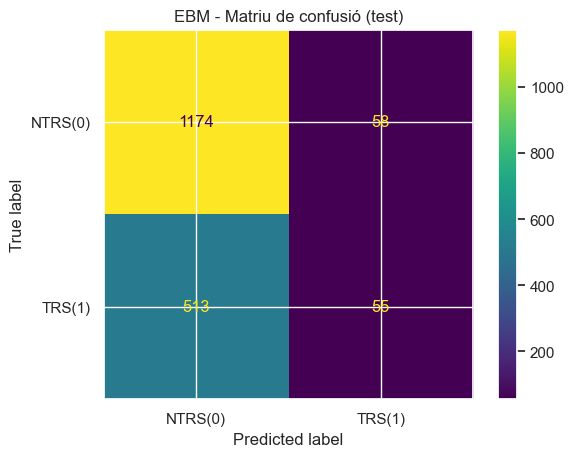

In [145]:

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_ebm,
    labels=[0, 1],
    display_labels=["NTRS(0)", "TRS(1)"],
    values_format="d"
)
plt.title("EBM - Matriu de confusió (test)")
plt.show()


In [146]:
type(confusion_matrix), confusion_matrix


(str,
 "data:image/svg+xml,%3c?xml version='1.0' encoding='UTF-8'?%3e %3c!DOCTYPE svg PUBLIC '-//W3C//DTD SVG 1.1//EN' 'http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd'%3e %3csvg width='475.2pt' height='360pt' version='1.1' viewBox='0 0 475.2 360' xmlns='http://www.w3.org/2000/svg'%3e %3cdefs%3e %3cstyle type='text/css'%3e*%7bstroke-linejoin: round; stroke-linecap: butt%7d%3c/style%3e %3c/defs%3e %3cg id='figure_1'%3e %3cg id='patch_1'%3e %3cpath d='m0 360h475.2v-360h-475.2z' fill='%23fff'/%3e %3c/g%3e %3c/g%3e %3c/svg%3e")

Validació gràfica: Corva precision - recall

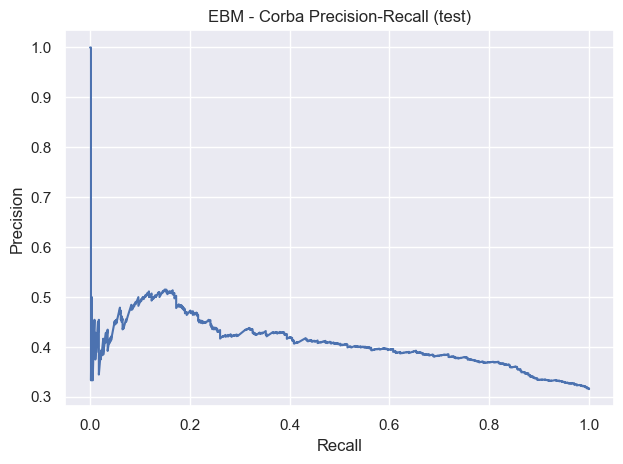

In [147]:

scores_ebm = best_ebm.predict_proba(X_test)[:, 1]

p, r, _ = precision_recall_curve(y_test, scores_ebm, pos_label=1)

plt.figure()
plt.plot(r, p)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("EBM - Corba Precision-Recall (test)")
plt.tight_layout()
plt.show()

### 6.3 Taula comparativa

In [162]:
summary_models = pd.DataFrame([
    {
        "model": "SVM (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm_fine["f1_macro"].iloc[0],
    },
    {
        "model": "XGBoost (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(rs_xgb_extra, metric="f1_macro")[0],
        "f1_macro_test_cv":  cv_train_test_f1(rs_xgb_extra, metric="f1_macro")[1],
        "f1_macro_test":     metrics_xgb_extra["f1_macro"].iloc[0],
    },
    {
        "model": "LR (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_lr_it1, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_lr_it1, metric='f1_macro')[1],
        "f1_macro_test":     metrics_lr_it1["f1_macro"].iloc[0],
    },
    {
        "model": "EBM (bonus 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_ebm, metric="f1_macro")[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_ebm, metric="f1_macro")[1],
        "f1_macro_test":     metrics_ebm["f1_macro"].iloc[0],
    },
    
]).sort_values("f1_macro_test_cv", ascending=False).reset_index(drop=True)

summary_models


,model,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,LR (iteració 1),0.598045,0.595966,0.583181
1,SVM (iteració 1),0.593809,0.592394,0.572873
2,XGBoost (iteració 1),0.640965,0.580146,0.565805
3,EBM (bonus 1),0.512525,0.485632,0.482956


***
## BONUS 2: Model extra - Random Forest

### 7.1 Anàlisi d'hiperparàmetres

In [149]:

pipe_rf = Pipeline([
    ("prep", preprocess),
    ("rf", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "rf__n_estimators": [200, 500],
    "rf__max_depth": [None, 10, 20],
    "rf__min_samples_leaf": [1, 2, 5],
    "rf__max_features": ["sqrt", "log2"],
    "rf__class_weight": [None, "balanced"]
}

gs_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid_rf,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

gs_rf.fit(X_train, y_train)

print(f"Best CV F1-macro (RF): {gs_rf.best_score_:.4f}")

res_rf = pd.DataFrame(gs_rf.cv_results_)

cols_rf = [
    "param_rf__n_estimators", "param_rf__max_depth", "param_rf__min_samples_leaf",
    "param_rf__max_features", "param_rf__class_weight",

    # TEST
    "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    "std_test_f1_macro", "rank_test_f1_macro",

    # TRAIN
    "mean_train_accuracy", "mean_train_precision_macro", "mean_train_recall_macro", "mean_train_f1_macro",
]

table_rf = res_rf[cols_rf].sort_values("rank_test_f1_macro")

table_rf = table_rf.rename(columns={
    "mean_test_accuracy": "mean_test_cv_accuracy",
    "mean_test_precision_macro": "mean_test_cv_precision_macro",
    "mean_test_recall_macro": "mean_test_cv_recall_macro",
    "mean_test_f1_macro": "mean_test_cv_f1_macro",
    "std_test_f1_macro": "std_test_cv_f1_macro",
    "rank_test_f1_macro": "rank_test_cv_f1_macro",
    "mean_train_accuracy": "mean_train_cv_accuracy",
    "mean_train_precision_macro": "mean_train_cv_precision_macro",
    "mean_train_recall_macro": "mean_train_cv_recall_macro",
    "mean_train_f1_macro": "mean_train_cv_f1_macro",
})

table_rf

gs_rf.best_estimator_.named_steps["rf"]

Best CV F1-macro (RF): 0.5878


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

### 7.2 Validació numèrica i gràfica

Validació numèrica: Mètriques

In [150]:

best_rf = gs_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)

metrics_rf = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred_rf),
    "precision_macro": precision_score(y_test, y_pred_rf, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_rf, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_rf, average="macro", zero_division=0),
    "precision(TRS)": precision_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
    "recall(TRS)": recall_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
    "f1(TRS)": f1_score(y_test, y_pred_rf, pos_label=1, zero_division=0),
}])

metrics_rf

,accuracy,precision_macro,recall_macro,f1_macro,precision(TRS),recall(TRS),f1(TRS)
0,0.609444,0.56827,0.574258,0.56874,0.400589,0.478873,0.436247


Validació gràfica: Matriu de confusió

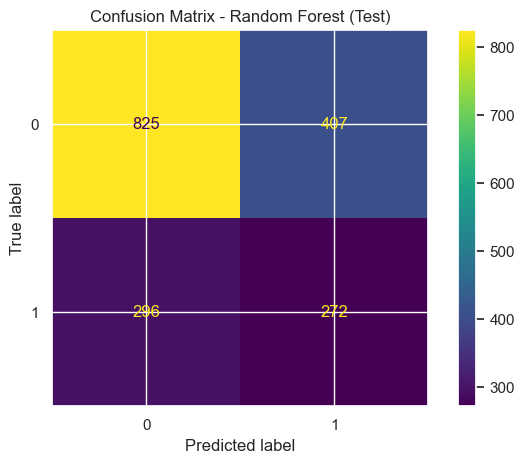

In [151]:

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, labels=[0, 1])
plt.title("Confusion Matrix - Random Forest (Test)")
plt.tight_layout()
plt.show()

Validació gràfica: Corva precision - recall

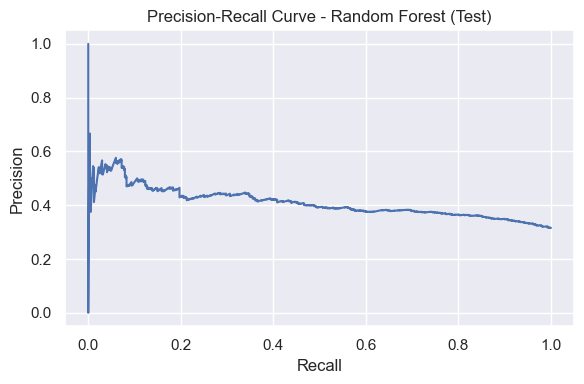

In [152]:

y_test_proba_rf = best_rf.predict_proba(X_test)[:, 1]

prec, rec, _ = precision_recall_curve(y_test, y_test_proba_rf)

plt.figure(figsize=(6, 4))
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest (Test)")
plt.grid(True)
plt.tight_layout()
plt.show()

### 7.3 Taula comparativa

In [161]:
summary_models = pd.DataFrame([
    {
        "model": "SVM (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_kernel_fine, metric='f1_macro')[1],
        "f1_macro_test": metrics_svm_fine["f1_macro"].iloc[0],
    },
    {
        "model": "XGBoost (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(rs_xgb_extra, metric="f1_macro")[0],
        "f1_macro_test_cv":  cv_train_test_f1(rs_xgb_extra, metric="f1_macro")[1],
        "f1_macro_test":     metrics_xgb_extra["f1_macro"].iloc[0],
    },
    {
        "model": "LR (iteració 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_lr_it1, metric='f1_macro')[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_lr_it1, metric='f1_macro')[1],
        "f1_macro_test":     metrics_lr_it1["f1_macro"].iloc[0],
    },
    {
        "model": "EBM (bonus 1)",
        "f1_macro_train_cv": cv_train_test_f1(gs_ebm, metric="f1_macro")[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_ebm, metric="f1_macro")[1],
        "f1_macro_test":     metrics_ebm["f1_macro"].iloc[0],
    },
    {
        "model": "Random Forest (bonus 2)",
        "f1_macro_train_cv": cv_train_test_f1(gs_rf, metric="f1_macro")[0],
        "f1_macro_test_cv":  cv_train_test_f1(gs_rf, metric="f1_macro")[1],
        "f1_macro_test":     metrics_rf["f1_macro"].iloc[0],
    },
]).sort_values("f1_macro_test_cv", ascending=False).reset_index(drop=True)

summary_models


,model,f1_macro_train_cv,f1_macro_test_cv,f1_macro_test
0,LR (iteració 1),0.598045,0.595966,0.583181
1,SVM (iteració 1),0.593809,0.592394,0.572873
2,Random Forest (bonus 2),0.833329,0.587804,0.568740
3,XGBoost (iteració 1),0.640965,0.580146,0.565805
4,EBM (bonus 1),0.512525,0.485632,0.482956
